<img src="https://www.javeriana.edu.co/recursosdb/20125/5571273/escudo-circular.png" alt="Your Image" style="float:left;">
</div><h1>Pontificia Universidad Javeriana</h1>

<h1> Taller de Procesamiento de Lenguaje Natural</h1>

### Integrantes:


# Análisis de discursos presidenciales en Colombia

## Objetivos

- Aplicar técnicas fundamentales de procesamiento de lenguaje natural (NLP) en español, comparando un enfoque clásico (NLTK) con un pipeline moderno basado en spaCy.
- Analizar la frecuencia léxica y patrones de estilo en textos políticos, incluyendo patrones gramaticales identificados con el Matcher de spaCy.
- Medir la diversidad léxica y complejidad discursiva con herramientas de estilometría (TextStat y textdescriptives).
- Explorar entidades nombradas (personas, lugares, organizaciones) como huella temática de cada discurso y periodo.
- Explorar el cambio del discurso político colombiano a lo largo del tiempo.
- Interpretar resultados lingüísticos desde una perspectiva crítica e histórica.

## 1 Comprensión del problema

El corpus **presidentes** contiene discursos de diferentes presidentes de Colombia. Se espera que esté organizado como un diccionario de Python.

[Corpus Presidentes](https://puj-nlp.github.io/open_corpus_co_es/corpus)





## 2 Estudio y comprensión de los datos

### 2.1 Instalación de librerías

In [1]:
# =====================================================================
# Instalacion de dependencias (robusta para Colab y para ejecucion local)
# ---------------------------------------------------------------------
# Se usa subprocess con sys.executable para que la instalacion emplee el
# mismo interprete del kernel (el de Colab o el venv local). Si el
# paquete o el modelo ya estan instalados, no se vuelve a descargar y
# la celda no interrumpe la ejecucion del notebook.
# =====================================================================
import subprocess
import sys

# 1) Paquete del corpus de discursos presidenciales
try:
    import open_corpus_co_es
    print("open_corpus_co_es ya esta instalado.")
except ImportError:
    print("Instalando open_corpus_co_es ...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "open_corpus_co_es", "-q"]
    )
    print("open_corpus_co_es instalado correctamente.")

# 2) Modelo de espanol de spaCy
import spacy
if not spacy.util.is_package("es_core_news_md"):
    print("Descargando el modelo es_core_news_md ...")
    subprocess.check_call(
        [sys.executable, "-m", "spacy", "download", "es_core_news_md", "-q"]
    )
    print("Modelo es_core_news_md instalado correctamente.")
else:
    print("El modelo es_core_news_md ya esta instalado.")
# 3) textstat para indices de legibilidad (puntos 7 y 8)
#    El enunciado del taller pide textstat==0.2, pero esa version es de
#    Python 2 y no importa en Python 3 (ni en Colab actual). Se instala la
#    ultima version, cuya API es compatible: flesch_reading_ease, gunning_fog,
#    smog_index y flesch_kincaid_grade.
try:
    import textstat
    import importlib
    version_ts = getattr(textstat, "__version__", (0, 0, 0))
    if isinstance(version_ts, tuple):
        version_ts = tuple(int(p) for p in version_ts)
    else:
        version_ts = tuple(int(p) for p in str(version_ts).split("."))
    if version_ts < (0, 7, 0):
        print("textstat desactualizado ({}); actualizando ...".format(textstat.__version__))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "--upgrade", "textstat", "-q"]
        )
        importlib.reload(textstat)
        print("textstat actualizado:", textstat.__version__)
    else:
        print("textstat", textstat.__version__, "ya esta instalado.")
except ImportError:
    print("Instalando textstat (ultima version, API compatible) ...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--upgrade", "textstat", "-q"]
    )
    import textstat
    print("textstat instalado:", textstat.__version__)

# 4) textdescriptives para estilometria dentro del pipeline de spaCy
#    (punto 7 del taller). El simple 'import textdescriptives' registra las
#    factories del componente, en particular 'textdescriptives/readability',
#    que anade a cada Doc las extensiones _.readability, _.token_length y
#    _.sentence_length. Si el paquete no esta instalado, se instala primero.
try:
    import textdescriptives
    print("textdescriptives", getattr(textdescriptives, "__version__", "?"),
          "ya esta instalado.")
except ImportError:
    print("Instalando textdescriptives ...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "textdescriptives", "-q"]
    )
    import textdescriptives
    print("textdescriptives instalado:", getattr(textdescriptives, "__version__", "?"))


open_corpus_co_es ya esta instalado.


El modelo es_core_news_md ya esta instalado.
textstat (0, 7, 13) ya esta instalado.
textdescriptives 2.8.4 ya esta instalado.


In [2]:
import math
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.util import ngrams
from nltk import word_tokenize
nltk.download('stopwords')

import spacy
nlp = spacy.load("es_core_news_md")

from wordcloud import WordCloud

import open_corpus_co_es
from open_corpus_co_es import download_corpus, load_corpus

[nltk_data] Downloading package stopwords to /home/carlos/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
# ============================================================
# Configuracion de guardado de figuras y datos textuales
# Cada grafico del notebook se guarda en la carpeta images/ (dpi 150,
# bbox_inches='tight') y, ademas, se generan CSVs con los datos de cada
# grafico para permitir el analisis de resultados sin la imagen.
# ============================================================
import os
os.makedirs("images", exist_ok=True)

def guardar_figura(fig, nombre_archivo):
    """Guarda la figura en images/ y la devuelve para mostrarla.

    Args:
        fig (matplotlib.figure.Figure): Figura a guardar.
        nombre_archivo (str): Nombre del archivo (solo minusculas,
            guiones bajos, sin tildes ni espacios).

    Returns:
        matplotlib.figure.Figure: La misma figura, para que el notebook
        continue mostrandola con plt.show().
    """
    os.makedirs("images", exist_ok=True)
    fig.savefig(os.path.join("images", nombre_archivo), dpi=150, bbox_inches="tight")
    return fig


### Guardado automático de figuras y datos

A partir de este punto, **cada gráfico generado** se guarda automáticamente en la carpeta `images/`
con `dpi=150` y `bbox_inches="tight"`, sin dejar de mostrarse en el notebook (se conserva `plt.show()`).

Además, para cada gráfico se exportan sus **datos en archivos CSV** dentro de la misma carpeta `images/`:

- `frecuencias_top20.csv`: frecuencias de términos por presidente (top-20).
- `nubes_top10_corriente_politica.csv` y `nubes_top10_decada.csv`: top-10 de lemas por grupo.
- `matcher_top_matches.csv`: coincidencias del Matcher de spaCy (top-20) con su patrón.

De esta forma los resultados pueden analizarse sin necesidad de abrir la imagen.

### 2.2 Cargue de los datos

In [4]:
# Descarga y cargue del corpus
corpus = download_corpus('presidentes')
discursos = load_corpus('presidentes')


INFO - Corpus 'presidentes' ya descargado. Usa force=True para reescribir.


## 3 Exploración de los datos

El corpus es una lista de diccionarios.

In [5]:
# Se valida el tipo de dato
type(discursos)

list

In [6]:
# Se valida cuantos elementos contiene la lista
len(discursos)

22

In [7]:
# Cada elemento de la lista es un diccionario
type(discursos[1])

dict

Al explorar el primer elemento de la lista, nos damos cuenta que es un diccionario que cuenta con cinco elementos:

- text
- fecha_inicio
- fecha_fin
- nombre
- archivo





In [8]:
for key in discursos[1].keys():
    print(key)


text
fecha_inicio
fecha_fin
nombre
archivo


Al listar los presidentes (Nota: Jorge Eliecer Gaitan, no alcanzo a ser presidente) corrabaromos que hay 22 en total.

In [9]:
for k, i in enumerate(range(len(discursos))):
    print(k, discursos[i]['nombre'])

0 jorge eliecer gaitan
1 mariano ospina perez
2 laureano gomez
3 rojas pinilla
4 alberto lleras
5 guillermo leon
6 carlos lleras
7 misael pastrana borrero
8 alfonso lopez michelsen
9 julio cesar turbay
10 belisario betancur
11 virgilio barco
12 cesar gaviria
13 ernesto samper
14 andres pastrana
15 alvaro uribe
16 alvaro uribe
17 juan manuel santos
18 juan manuel santos
19 ivan duque
20 gustavo petro urrego
21 abelardo de la espriella


In [10]:
# Conteo de discursos por presidente (punto 1 del taller)
conteo_por_presidente = Counter(d["nombre"] for d in discursos)
pd.Series(conteo_por_presidente, name="num_discursos").sort_values(ascending=False)

juan manuel santos          2
alvaro uribe                2
jorge eliecer gaitan        1
mariano ospina perez        1
gustavo petro urrego        1
ivan duque                  1
andres pastrana             1
ernesto samper              1
cesar gaviria               1
virgilio barco              1
belisario betancur          1
julio cesar turbay          1
alfonso lopez michelsen     1
misael pastrana borrero     1
carlos lleras               1
guillermo leon              1
alberto lleras              1
rojas pinilla               1
laureano gomez              1
abelardo de la espriella    1
Name: num_discursos, dtype: int64

Cada uno de los textos son los discursos de posesión de cada uno de los presidentes.

In [11]:
discursos[19]["text"]

'colombianos:\nhoy desde esta majestuosa plaza que lleva el nombre de nuestro libertador simón bolívar, quiero agradecerles a dios y al pueblo colombiano por brindarme el honor de conducir los destinos de la patria.\nhoy llega a la presidencia de colombia una nueva generación, motivada por el servicio y no por el ejercicio vanidoso del poder, comprometida con el futuro y sin anclas y prejuicios en el pasado, inspirada en la justicia social y en la seguridad como el cimiento de nuestras libertades, y dedicada a promover el entendimiento, el trabajo en equipo y la construcción de consensos. es una generación llamada a gobernar libre de odios, de revanchas, de mezquindades y con el mandato de millones de compatriotas de hacer de nuestro país una tierra grande donde los símbolos de nuestro tricolor retomen su significado.\nen alguna ocasión el célebre darío echandía se preguntó: ¿el poder para qué? su humildad elocuente era una invitación para reflexionar y no olvidar que gobernar es un ca

In [12]:
discursos[20]["text"]

'llegar aquí, junto a esta espada, para mí es toda una vida, una existencia. esta espada representa demasiado para nosotros, para nosotras.\ny quiero que nunca esté enterrada, quiero que nunca más esté retenida.\nque solo se envaine, como dijo su propietario, el libertador, cuando haya justicia en este país.\nque sea del pueblo. es la espada del pueblo.\ny por eso la queríamos aquí en este momento y en este lugar. quizás para los próximos presidentes y presidentas, cuando se posesionen, se vuelva un hecho permanente, protocolario, simbólico, que los acompañe siempre, que las acompañe siempre, la espada libertaria de bolívar.\nllegar aquí indudablemente implica recorrer una vida. la vida inmensa que nunca se recorre sola.\naquí está mi madre, clara. nada existiría en mí, en este momento, sin ella.\naquí está mi padre, gustavo, caribeño. aquí están mis hermanos adriana y juan, que me aguantaban y aún me aguantan.\naquí están mis hijos, nicolás petro, nicolás alcocer, andrea y andrés, sof

In [13]:
discursos[21]["text"]

'me es imprescindible iniciar estas palabras elevando, desde esta tribuna de la república, un sentimiento de profunda gratitud a nuestro señor jesucristo por bendecir a colombia y por no haber apartado jamás su mirada providente de esta tierra bendita. gracias, señor, por mantener tus ojos misericordiosos sobre nuestras montañas, valles, selvas, ríos y mares, por acompañar a este pueblo valiente incluso en las horas más oscuras de su existencia, por sostener a nuestra nación a lo largo de una historia republicana marcada por guerras, violencia, divisiones y tragedias.\nhe venido a cerrar un largo capítulo de resignación nacional y a emprender, junto al pueblo, la transformación más profunda de nuestro destino. tiene un inmenso significado que esta posesión presidencial se celebre en el «cantón militar pichincha», este lugar honra a quienes conquistaron la libertad y simboliza la presencia de una fuerza pública llamada a custodiarla.\nhoy ocuparé la silla que perteneció a joaquín de cay

Así mismo el campo **fecha_inicio** proporciona el año de posesión.

In [14]:
for k, i in enumerate(range(len(discursos))):
    print(k, discursos[i]['fecha_inicio'])

0 1942
1 1946
2 1950
3 1953
4 1958
5 1962
6 1966
7 1970
8 1974
9 1978
10 1982
11 1986
12 1990
13 1994
14 1998
15 2002
16 2006
17 2010
18 2014
19 2018
20 2022
21 2026


## 4 Limpieza y procesamiento de los datos


### 4.1 Preparación del corpus

Convertimos el corpus en un dataframe para facilitar su manejo.

In [15]:
# Conversion a df
df = pd.DataFrame(discursos)
# Renombre de las columnas
df = df.rename(columns={
    "text": "discurso",
    "fecha_inicio": "año_inicio",
    "fecha_fin": "año_fin",
    "nombre": "presidente",
    "archivo": "fuente"
})

# Podemos añadir una columna con la ideologia o postura politca.
posturas = [
    "Izquierda",               # 0: Jorge Eliecer Gaitan
    "Centro-Derecha",          # 1: Mariano Ospina Perez
    "Derecha Radical",         # 2: Laureano Gomez
    "Militarismo / Excepción", # 3: Rojas Pinilla
    "Centro",                  # 4: Alberto Lleras
    "Centro-Derecha",          # 5: Guillermo Leon
    "Centro-Izquierda",        # 6: Carlos Lleras
    "Centro-Derecha",          # 7: Misael Pastrana Borrero
    "Centro",                  # 8: Alfonso Lopez Michelsen
    "Centro-Derecha",          # 9: Julio Cesar Turbay
    "Centro-Derecha",          # 10: Belisario Betancur
    "Centro-Izquierda",        # 11: Virgilio Barco
    "Centro-Derecha",          # 12: Cesar Gaviria
    "Centro-Izquierda",        # 13: Ernesto Samper
    "Centro-Derecha",          # 14: Andres Pastrana
    "Derecha",                 # 15: Alvaro Uribe
    "Derecha",                 # 16: Alvaro Uribe
    "Centro",                  # 17: Juan Manuel Santos
    "Centro",                  # 18: Juan Manuel Santos
    "Derecha",                 # 19: Ivan Duque
    "Izquierda",               # 20: Gustavo Petro Urrego
    "Derecha Radical"          # 21: Abelardo de la Espriella
]

df["corriente_politica"] = posturas

# Orden y selección de columnas relevantes
df = df[["año_inicio", "año_fin", "presidente", "corriente_politica", "discurso" ]]
df.head()

,año_inicio,año_fin,presidente,corriente_politica,discurso
0,1942,1946,jorge eliecer gaitan,Izquierda,"""pueblos, por vuestra victoria moral ¡a la car..."
1,1946,1950,mariano ospina perez,Centro-Derecha,excelentísimo señor: el juramento de rigor que...
2,1950,1954,laureano gomez,Derecha Radical,el juramento que acabo de hacer a dios en vues...
3,1953,1957,rojas pinilla,Militarismo / Excepción,este es un documento de radio nacional de colo...
4,1958,1962,alberto lleras,Centro,excelentísimo señor presidente señores miembro...


### 4.2 Limpieza

La función **limpiar_texto** toma un texto y le aplica las siguientes transformaciones:

- Convertir a minúsculas
- Quita las tildes
- Quita números, signos de puntuación y caracteres especiales
- Normalizar espacios, tabs, saltos de línea
- Quitar espacios al inicio y al final

#### 4.2.1 Via paralela para spaCy: texto con tildes

La funcion **limpiar_texto** elimina los diacriticos (tildes) y la puntuacion,
lo cual es adecuado para la tokenizacion clasica de NLTK y para los conteos de
palabras. Sin embargo, el modelo de spaCy `es_core_news_md` esta entrenado con
ortografia correcta: si el texto pierde las tildes, la lematizacion, el
etiquetado POS y el reconocimiento de entidades se degradan (por ejemplo,
*podremos* se lematiza como *podrar* en vez de *poder*).

Por eso se crea una via paralela `discurso_spacy` que solo pasa el texto a
minusculas y conserva tildes y puntuacion. Esta columna se usara en todo el
pipeline de spaCy (lemas, POS, Matcher, NER), mientras que `discurso_limpio`
se mantiene para NLTK y los conteos.

In [16]:
# Funcion de limpieza
def limpiar_texto(texto):
    # Minúsculas
    texto = texto.lower()

    # Proteger la ñ temporalmente
    texto = texto.replace("ñ", "__enie__")

    # Quitar tildes y otros diacríticos
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(
        c for c in texto
        if unicodedata.category(c) != "Mn"
    )

    # Restaurar la ñ
    texto = texto.replace("__enie__", "ñ")

    # Dejar solo letras a-z, ñ y espacios
    texto = re.sub(r"[^a-zñ\s]", " ", texto)

    # Normalizar espacios, tabs y saltos de línea
    texto = re.sub(r"\s+", " ", texto)

    return texto.strip()

### 4.2.0 Pipeline de limpieza: plantillas de scan, de-hyphenation, OCR y duplicados

El corpus `presidentes` (open_corpus_co_es) hereda artefactos de un scan con
OCR: (1) lineas plantilla de la digitalizacion (numeros de pagina sueltos, pies
de fecha "agosto 1974", encabezados de radio "señal memoria / rtvc" y lineas
decorativas "---"/"*****"); (2) 552 casos del patron `\w+-\n\w+` (palabras
partidas por guion de fin de renglon, concentradas en Lopez Michelsen, 264, y
Turbay, 283); (3) digitos que sustituyen letras ("pa1·a" -> "para",
"c0lombia" -> "colombia"); (4) la letra suelta "n" de OCR ("n ación" ->
"nación"); y (5) palabras funcionales duplicadas ("en en" -> "en").

El pipeline de limpieza se aplica en este orden sobre `df["discurso"]`, ANTES
de generar `discurso_limpio` y `discurso_spacy`:

1. `limpiar_lineas_plantilla`: elimina lineas completas que son metadata del
   scan (numeros de pagina, pies de fecha, encabezados de radio y lineas
   decorativas), de modo que sus digitos y guiones no ensucien las etapas
   siguientes.
2. `de_hyphenate`: union condicionada de palabras partidas por guion -- solo si
   la concatenacion existe en un lexico (tokens del corpus + vocabulario con
   vectores de `es_core_news_md`), evitando pseudopalabras que generaria la
   union ciega (ej. "abatiendolar").
3. `corregir_ocr_digitos`: corrige digitos OCR con validacion lexica
   ("1·" -> "r", "1-" -> "r", "1" -> {r,l,i,b,n}, "0" -> "o"); solo si el
   candidato corregido es una palabra valida ("12o/o", "km2," y numeros quedan
   intactos).
4. `unir_n_suelta`: une la "n" suelta con la palabra siguiente (o con las dos
   siguientes, casos de tres trozos) solo si la concatenacion completa es
   valida en el lexico ("n ación" -> "nación", "n u estro" -> "nuestro").
5. `deduplicar_funcionales`: elimina duplicados consecutivos de una whitelist
   de funcionales ("en en" -> "en"); "no no" y "si si" se conservan (retorica
   o cita).

El texto original se conserva en `df["discurso_original"]` por trazabilidad y
no se usa en el analisis. Todo el pipeline posterior (tokens, lemas, n-gramas,
estilometria, NER, grafos) usa automaticamente el texto corregido. Sin estas
correcciones, los fragmentos generan tokens fantasma ("co-", "re-", "cion",
"agosto", "rtvc", "n"...) que ensucian frecuencias, n-gramas, NER y
estilometria. El paper de referencia de estos discursos (Luque et al., 2023)
no reporta estos artefactos.

In [17]:
# --- Pipeline de limpieza del corpus (seccion 4.2) -------------------------
# Etapas: P1 lineas plantilla -> de-hyphenation -> P2 digitos OCR -> P3 'n'
# suelta -> P4 funcionales duplicados. Todas las uniones se validan contra el
# LEXICO construido a continuacion, para no generar pseudopalabras.
import itertools


def construir_lexico(textos):
    """Construye el lexico de validacion: tokens del corpus + vocabulario de spaCy."""
    tokens_corpus = set()
    for t in textos:
        tokens_corpus.update(re.findall(r"[^\W\d_]+", t))
    tokens_spacy = {nlp.vocab.strings[k] for k in nlp.vocab.vectors.key2row}
    return tokens_corpus | tokens_spacy


LEXICO = construir_lexico(df["discurso"].tolist())


def de_hyphenate(texto, lexico=LEXICO):
    """Une palabras partidas por guion de fin de linea si la concatenacion
    es una palabra valida en el lexico. Ej: 'economi-\nco' -> 'economico'.

    Args:
        texto (str): Texto crudo del corpus.
        lexico (set): Palabras validas para validar la union.

    Returns:
        str: Texto con las uniones validas aplicadas.
    """
    return re.sub(
        r"(\w+)-\n(\w+)",
        lambda m: (m.group(1) + m.group(2))
        if (m.group(1) + m.group(2)) in lexico
        else m.group(0),
        texto,
    )


def limpiar_lineas_plantilla(texto):
    """Elimina lineas que son metadata del scan: numeros de pagina sueltos,
    pies de fecha ('agosto 1974'), encabezados de radio ('señal memoria / rtvc')
    y lineas decorativas ('---', '*****'). Solo elimina LINEAS COMPLETAS.

    Args:
        texto (str): Texto crudo del discurso.

    Returns:
        str: Texto sin las lineas plantilla del scan.
    """
    lineas = texto.split("\n")
    conservadas = []
    for linea in lineas:
        l = linea.strip()
        if re.fullmatch(r"\d{1,4}", l):            # numeros de pagina sueltos
            continue
        if re.fullmatch(r"agosto \d{4}", l):       # pie de fecha del scan
            continue
        if l == "señal memoria / rtvc":            # encabezado de radio
            continue
        if set(l) <= {"-"} and len(l) >= 2:        # lineas decorativas de guiones
            continue
        if set(l) <= {"*"} and len(l) >= 2:        # lineas decorativas de asteriscos
            continue
        conservadas.append(linea)
    return "\n".join(conservadas)


def corregir_ocr_digitos(texto):
    """Corrige errores OCR donde digitos sustituyen letras, validando contra el
    lexico: '1·' -> 'r', '1-' -> 'r' (tras guion), '1' -> {r,l,i,b,n}, '0' -> 'o'.
    Solo aplica si el candidato corregido es una palabra valida del lexico.

    Ejemplos: 'pa1·a' -> 'para', 'c0lombia' -> 'colombia', '1eutral' -> 'neutral',
    'fue1-zas' -> 'fuerzas', 'p1·ensa.' -> 'prensa.'. Tokens como '12o/o',
    'km2,' o '40%' quedan intactos porque la validacion lexica los rechaza.

    Args:
        texto (str): Texto del discurso.

    Returns:
        str: Texto con los digitos OCR corregidos.
    """
    def corregir_token(token):
        if not re.search(r"[10·]", token) or not re.search(r"[a-záéíóúñ]", token):
            return token
        base = token.replace("1·", "r").replace("1-", "r")
        if base in LEXICO:
            return base
        nucleo = re.sub(r"[^a-záéíóúñ]+$", "", base)
        if nucleo != base and nucleo in LEXICO:
            return base
        candidatos = []
        for ch in nucleo:
            if ch == "1":
                candidatos.append(["r", "l", "i", "b", "n"])
            elif ch == "0":
                candidatos.append(["o"])
            else:
                candidatos.append([ch])
        for combo in itertools.product(*candidatos):
            cand = "".join(combo)
            if cand in LEXICO and len(cand) >= 4:
                return cand + base[len(nucleo):]
        return token

    # re.split con grupo capturador conserva los separadores (espacios y saltos)
    partes = re.split(r"(\s+)", texto)
    return "".join(corregir_token(p) if p.strip() else p for p in partes)


def unir_n_suelta(texto):
    """Une la 'n' suelta de OCR con la palabra siguiente si la concatenacion
    es valida en el lexico ('n ación' -> 'nación'). Tambien maneja casos de tres
    trozos ('n u estro' -> 'nuestro', 'n un ca' -> 'nunca') uniendo la 'n' con
    las dos palabras siguientes. La union solo se aplica si la concatenacion
    completa existe en el lexico.

    Args:
        texto (str): Texto del discurso.

    Returns:
        str: Texto con las 'n' sueltas unidas.
    """
    patron_tres_trozos = r"\bn\s+([a-záéíóúñ]{1,2})\s+([a-záéíóúñ]{2,})"
    patron_dos_trozos = r"\bn\s+([a-záéíóúñ]{2,})"
    for _ in range(3):
        nuevo = re.sub(
            patron_tres_trozos,
            lambda m: ("n" + m.group(1) + m.group(2))
            if ("n" + m.group(1) + m.group(2)) in LEXICO
            else m.group(0),
            texto,
        )
        nuevo = re.sub(
            patron_dos_trozos,
            lambda m: ("n" + m.group(1))
            if ("n" + m.group(1)) in LEXICO
            else m.group(0),
            nuevo,
        )
        if nuevo == texto:
            break
        texto = nuevo
    return texto


def deduplicar_funcionales(texto):
    """Elimina duplicados consecutivos de palabras funcionales de una whitelist
    ('en en' -> 'en', 'por por' -> 'por'). No toca 'no no' ni 'si si' porque
    pueden ser retorica o citas ('sí, sí; no, no').

    Args:
        texto (str): Texto del discurso.

    Returns:
        str: Texto sin duplicados consecutivos de funcionales.
    """
    funcionales = r"\b(en|de|el|la|para|por|un|una|con|que|los|las)\s+\1\b"
    return re.sub(funcionales, r"\1", texto)


# Conservar el texto original por trazabilidad y aplicar la limpieza completa
df["discurso_original"] = df["discurso"]

# P1: limpiar lineas plantilla (ANTES del de-hyphenation para que los digitos
# y guiones de esas lineas no interfieran con las reglas siguientes)
df["discurso"] = df["discurso"].apply(limpiar_lineas_plantilla)

# De-hyphenation: unir palabras partidas por guion de fin de linea
df["discurso"] = df["discurso"].apply(de_hyphenate)

# P2: corregir digitos OCR que sustituyen letras (validacion lexica)
df["discurso"] = df["discurso"].apply(corregir_ocr_digitos)

# P3: unir la 'n' suelta de OCR con la palabra siguiente
df["discurso"] = df["discurso"].apply(unir_n_suelta)

# P4: deduplicar palabras funcionales repetidas
df["discurso"] = df["discurso"].apply(deduplicar_funcionales)


In [18]:
df["discurso_limpio"] = df["discurso"].apply(limpiar_texto)
df.head()

,año_inicio,año_fin,presidente,corriente_politica,discurso,discurso_original,discurso_limpio
0,1942,1946,jorge eliecer gaitan,Izquierda,"""pueblos, por vuestra victoria moral ¡a la car...","""pueblos, por vuestra victoria moral ¡a la car...",pueblos por vuestra victoria moral a la carga ...
1,1946,1950,mariano ospina perez,Centro-Derecha,excelentísimo señor: el juramento de rigor que...,excelentísimo señor: el juramento de rigor que...,excelentisimo señor el juramento de rigor que ...
2,1950,1954,laureano gomez,Derecha Radical,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...
3,1953,1957,rojas pinilla,Militarismo / Excepción,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...
4,1958,1962,alberto lleras,Centro,excelentísimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...,excelentisimo señor presidente señores miembro...


In [19]:
# Via paralela para spaCy: solo minusculas, conservando tildes y puntuacion.
# El modelo es_core_news_md requiere ortografia correcta para lemas y POS.
df["discurso_spacy"] = df["discurso"].str.lower()
df.head()

,año_inicio,año_fin,presidente,corriente_politica,discurso,discurso_original,discurso_limpio,discurso_spacy
0,1942,1946,jorge eliecer gaitan,Izquierda,"""pueblos, por vuestra victoria moral ¡a la car...","""pueblos, por vuestra victoria moral ¡a la car...",pueblos por vuestra victoria moral a la carga ...,"""pueblos, por vuestra victoria moral ¡a la car..."
1,1946,1950,mariano ospina perez,Centro-Derecha,excelentísimo señor: el juramento de rigor que...,excelentísimo señor: el juramento de rigor que...,excelentisimo señor el juramento de rigor que ...,excelentísimo señor: el juramento de rigor que...
2,1950,1954,laureano gomez,Derecha Radical,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...
3,1953,1957,rojas pinilla,Militarismo / Excepción,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...
4,1958,1962,alberto lleras,Centro,excelentísimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...,excelentisimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...


### 4.3 Procesamiento

#### 4.3.1 Tokenización y remoción de stopwords con NLTK

Se realiza una tokenización mediante **word_tokenize** y remoción de palabras vacias usando el conjunto disponible en NLTK.




In [20]:
# Establece el conjunto de palabras vacias
stopwords_es = set(stopwords.words("spanish"))

def tokenizar_sin_stopwords(texto):
    # Tokeniza y elimina stopwords
    words = [word for word in word_tokenize(texto, "spanish") if word not in stopwords_es and word.isalnum()]
    return words

def palabras_vacias(texto):
    # Almacena las stopwords
    words = [word for word in word_tokenize(texto, "spanish") if word in stopwords_es and word.isalnum()]
    return words


In [21]:
df["tokens_nltk"] = df["discurso_limpio"].apply(tokenizar_sin_stopwords)
df["stopwords_nltk"] = df["discurso_limpio"].apply(palabras_vacias)
df.head()

,año_inicio,año_fin,presidente,corriente_politica,discurso,discurso_original,discurso_limpio,discurso_spacy,tokens_nltk,stopwords_nltk
0,1942,1946,jorge eliecer gaitan,Izquierda,"""pueblos, por vuestra victoria moral ¡a la car...","""pueblos, por vuestra victoria moral ¡a la car...",pueblos por vuestra victoria moral a la carga ...,"""pueblos, por vuestra victoria moral ¡a la car...","[pueblos, victoria, moral, carga, restauracion...","[por, vuestra, a, la, por, la, a, la, por, vue..."
1,1946,1950,mariano ospina perez,Centro-Derecha,excelentísimo señor: el juramento de rigor que...,excelentísimo señor: el juramento de rigor que...,excelentisimo señor el juramento de rigor que ...,excelentísimo señor: el juramento de rigor que...,"[excelentisimo, señor, juramento, rigor, acaba...","[el, de, que, de, ante, el, de, la, en, de, la..."
2,1950,1954,laureano gomez,Derecha Radical,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,"[juramento, acabo, hacer, dios, presencia, señ...","[el, que, de, a, en, vuestra, de, la, y, ante,..."
3,1953,1957,rojas pinilla,Militarismo / Excepción,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,"[documento, radio, nacional, colombia, seguian...","[este, es, un, de, de, e, para, la, la, de, co..."
4,1958,1962,alberto lleras,Centro,excelentísimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...,excelentisimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...,"[excelentisimo, señor, presidente, señores, mi...","[del, nada, en, de, entre, sus, para, el, de, ..."


#### 4.3.2 Tokenización y remoción de stopwords con spaCy

In [22]:
# Procesamiento con spaCy sobre la via paralela: texto en minusculas CON
# tildes y puntuacion preservadas (discurso_spacy). Los objetos Doc se
# guardan en docs_corpus para reutilizarlos despues (por ejemplo, en el
# Matcher de la seccion 5.7) sin reprocesar el corpus.
docs_corpus = list(nlp.pipe(df["discurso_spacy"].fillna("").astype(str)))

resultados = []

for doc in docs_corpus:
    tokens = []
    lemas = []
    pos = []
    stopwords = []

    for token in doc:
        # Ignorar espacios y signos de puntuacion
        if token.is_space or token.is_punct:
            continue

        # Guardar palabras vacias
        if token.is_stop:
            stopwords.append(token.text)
            continue

        tokens.append(token.text)
        lemas.append(token.lemma_)
        pos.append(token.pos_)

    resultados.append({
        "tokens": tokens,
        "lemas": lemas,
        "pos": pos,
        "stopwords": stopwords
    })

df["tokens_spacy"] = [r["tokens"] for r in resultados]
df["lemas_spacy"] = [r["lemas"] for r in resultados]
df["pos_spacy"] = [r["pos"] for r in resultados]
df["stopwords_spacy"] = [r["stopwords"] for r in resultados]

In [23]:
df.head()

,año_inicio,año_fin,presidente,corriente_politica,discurso,discurso_original,discurso_limpio,discurso_spacy,tokens_nltk,stopwords_nltk,tokens_spacy,lemas_spacy,pos_spacy,stopwords_spacy
0,1942,1946,jorge eliecer gaitan,Izquierda,"""pueblos, por vuestra victoria moral ¡a la car...","""pueblos, por vuestra victoria moral ¡a la car...",pueblos por vuestra victoria moral a la carga ...,"""pueblos, por vuestra victoria moral ¡a la car...","[pueblos, victoria, moral, carga, restauracion...","[por, vuestra, a, la, por, la, a, la, por, vue...","[pueblos, victoria, moral, carga, restauración...","[pueblo, victoria, moral, carga, restauración,...","[NOUN, NOUN, ADJ, NOUN, NOUN, ADJ, NOUN, NOUN,...","[por, vuestra, a, la, por, la, a, la, por, vue..."
1,1946,1950,mariano ospina perez,Centro-Derecha,excelentísimo señor: el juramento de rigor que...,excelentísimo señor: el juramento de rigor que...,excelentisimo señor el juramento de rigor que ...,excelentísimo señor: el juramento de rigor que...,"[excelentisimo, señor, juramento, rigor, acaba...","[el, de, que, de, ante, el, de, la, en, de, la...","[excelentísimo, señor, juramento, rigor, acaba...","[excelentísimo, señor, juramento, rigor, acaba...","[ADJ, NOUN, NOUN, NOUN, VERB, VERB, NOUN, ADJ,...","[el, de, que, de, ante, el, de, la, en, de, la..."
2,1950,1954,laureano gomez,Derecha Radical,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,"[juramento, acabo, hacer, dios, presencia, señ...","[el, que, de, a, en, vuestra, de, la, y, ante,...","[juramento, acabo, dios, presencia, señores, m...","[juramento, acabar, dio, presencia, señor, mag...","[NOUN, VERB, NOUN, NOUN, NOUN, ADJ, NOUN, ADJ,...","[el, que, de, hacer, a, en, vuestra, de, la, y..."
3,1953,1957,rojas pinilla,Militarismo / Excepción,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,"[documento, radio, nacional, colombia, seguian...","[este, es, un, de, de, e, para, la, la, de, co...","[documento, radio, nacional, colombia, seguían...","[documento, radio, nacional, colombia, seguir,...","[NOUN, NOUN, ADJ, PROPN, VERB, NOUN, NOUN, NOU...","[este, es, un, de, de, mejor, e, para, la, la,..."
4,1958,1962,alberto lleras,Centro,excelentísimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...,excelentisimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...,"[excelentisimo, señor, presidente, señores, mi...","[del, nada, en, de, entre, sus, para, el, de, ...","[excelentísimo, señor, presidente, señores, mi...","[excelentísimo, señor, presidente, señor, miem...","[ADJ, NOUN, NOUN, NOUN, NOUN, NOUN, AUX, VERB,...","[del, nada, en, de, entre, sus, para, el, de, ..."


## 5 Análisis

### 5.1 Conteo de tokens y stopwords

El análisis cuantitativo se realiza sobre la vía paralela con tildes
(`discurso_spacy`) para spaCy y sobre el texto limpio (`discurso_limpio`) para
NLTK. En los 22 discursos se mantiene el patrón: la cantidad absoluta de
stopwords removidas es mayor mediante spaCy (por ejemplo, en el discurso de
Gustavo Petro, 2707 frente a 2312 de NLTK) y, en consecuencia, el volumen final
de tokens retenidos siempre es mayor al procesar el texto con NLTK (2261 frente
a 1884 lemas en el mismo discurso).

Además, la columna de verificación `tokens_stopwords_nltk` reproduce
exactamente el total de palabras del discurso limpio en los 22 discursos
(tokens retenidos + stopwords removidas = total), lo que confirma la
consistencia del conteo. Para spaCy la suma difiere en unas pocas unidades
porque se eliminan además los signos de puntuación durante el procesamiento.

In [24]:
def longitud(iterable):
    return len(iterable)

df_conteos = pd.DataFrame({
    "presidente": df["presidente"],
    "total_palabras": df["discurso_limpio"].apply(lambda x: len(x.split())),
    "numero_tokens_nltk": df["tokens_nltk"].apply(longitud),
    "numero_tokens_spacy": df["tokens_spacy"].apply(longitud),
    "numero_stopwords_nltk": df["stopwords_nltk"].apply(longitud),
    "numero_stopwords_spacy": df["stopwords_spacy"].apply(longitud),
})

df_conteos["diferencia_tokens"] = df_conteos["numero_tokens_nltk"] - df_conteos["numero_tokens_spacy"]
df_conteos["diferencia_stopwords"] = df_conteos["numero_stopwords_nltk"] - df_conteos["numero_stopwords_spacy"]
# Verificacion: tokens + stopwords debe reproducir el total de palabras.
# Para la via NLTK la igualdad es exacta; para spaCy el total de la via
# incluye ademas los tokens de puntuacion eliminados en el procesamiento.
df_conteos["tokens_stopwords_nltk"] = df_conteos["numero_tokens_nltk"] + df_conteos["numero_stopwords_nltk"]
df_conteos["tokens_stopwords_spacy"] = df_conteos["numero_tokens_spacy"] + df_conteos["numero_stopwords_spacy"]

df_conteos = df_conteos[["presidente", "total_palabras", "tokens_stopwords_nltk", "tokens_stopwords_spacy",
                               "numero_tokens_nltk", "numero_tokens_spacy", "diferencia_tokens",
                               "numero_stopwords_nltk", "numero_stopwords_spacy", "diferencia_stopwords"]]

df_conteos

,presidente,total_palabras,tokens_stopwords_nltk,tokens_stopwords_spacy,numero_tokens_nltk,numero_tokens_spacy,diferencia_tokens,numero_stopwords_nltk,numero_stopwords_spacy,diferencia_stopwords
0,jorge eliecer gaitan,3303,3303,3304,1501,1187,314,1802,2117,-315
1,mariano ospina perez,10661,10661,10696,5544,4828,716,5117,5868,-751
2,laureano gomez,6312,6312,6314,3280,2903,377,3032,3411,-379
3,rojas pinilla,657,657,657,350,287,63,307,370,-63
4,alberto lleras,8941,8941,8941,4652,3820,832,4289,5121,-832
5,guillermo leon,8856,8856,8856,4593,3778,815,4263,5078,-815
6,carlos lleras,5162,5162,5165,2711,2292,419,2451,2873,-422
7,misael pastrana borrero,4973,4973,4976,2509,2128,381,2464,2848,-384
8,alfonso lopez michelsen,5485,5485,5498,2827,2507,320,2658,2991,-333
9,julio cesar turbay,7543,7543,7539,3985,3493,492,3558,4046,-488


### 5.2 Aporte de stopwords de NLTK y spaCy

Ahora, analizando las stopwords unicas tanto para NLTK y spaCy, se confirma lo
observado anteriormente: el número de stopwords eliminadas por spaCy siempre es
mayor, y ahora la comparación es más justa porque spaCy procesa el texto con su
ortografía correcta (con tildes).

Al combinar las listas de stopwords de ambas herramientas, la gran mayoría de
los términos exclusivos proviene de spaCy (entre 45 % y 62 %), frente a un
máximo del 4,4 % aportado por NLTK. El porcentaje restante (entre 36 % y 55 %)
corresponde a palabras comunes a ambos vocabularios. El porcentaje de
exclusivas de NLTK sigue siendo cercano a cero porque su lista de stopwords es
un subconjunto casi completo de la de spaCy; la novedad de la vía con tildes es
que las palabras marcadas como vacías por spaCy ya no son errores de
lematización sino palabras funcionales reales (además, allí, ahora, acuerdo).

In [25]:
df_stopwords = pd.DataFrame({
    "presidente": df["presidente"],
    "stopwords_nltk": df["stopwords_nltk"].apply(set),
    "numero_stopwords_nltk": df["stopwords_nltk"].apply(set).apply(longitud),
    "stopwords_spacy": df["stopwords_spacy"].apply(set),
    "numero_stopwords_spacy": df["stopwords_spacy"].apply(set).apply(longitud)
})

df_stopwords["unicas_nltk"] = df_stopwords.apply(lambda fila: fila["stopwords_nltk"] - fila["stopwords_spacy"], axis=1)
df_stopwords["numero_unicas_nltk"] = df_stopwords["unicas_nltk"].apply(longitud)
df_stopwords["interseccion"] = df_stopwords.apply(lambda fila: fila["stopwords_nltk"] & fila["stopwords_spacy"], axis=1)
df_stopwords["numero_interseccion"] = df_stopwords["interseccion"].apply(longitud)
df_stopwords["unicas_spacy"] = df_stopwords.apply(lambda fila: fila["stopwords_spacy"] - fila["stopwords_nltk"], axis=1)
df_stopwords["numero_unicas_spacy"] = df_stopwords["unicas_spacy"].apply(longitud)

numero_stopwords_unicas = (df_stopwords["numero_unicas_nltk"] + df_stopwords["numero_interseccion"] + df_stopwords["numero_unicas_spacy"])

df_stopwords["%_interseccion"] = df_stopwords["numero_interseccion"] / numero_stopwords_unicas * 100
df_stopwords["%_unicas_nltk"] = df_stopwords["numero_unicas_nltk"] / numero_stopwords_unicas * 100
df_stopwords["%_unicas_spacy"] = df_stopwords["numero_unicas_spacy"] / numero_stopwords_unicas * 100


df_stopwords

,presidente,stopwords_nltk,numero_stopwords_nltk,stopwords_spacy,numero_stopwords_spacy,unicas_nltk,numero_unicas_nltk,interseccion,numero_interseccion,unicas_spacy,numero_unicas_spacy,%_interseccion,%_unicas_nltk,%_unicas_spacy
0,jorge eliecer gaitan,"{estos, este, uno, otras, nuestra, nuestro, se...",103,"{estos, este, uno, sí, así, otras, grandes, nu...",221,"{sentido, siente, tuvieron}",3,"{uno, estos, este, otras, nuestra, nuestro, se...",100,"{sí, así, grandes, gran, propio, hecho, quiere...",121,44.642857,1.339286,54.017857
1,mariano ospina perez,"{estos, uno, este, otras, nuestra, nuestro, se...",116,"{primero, dan, estos, uno, este, expresó, nuev...",299,"{sentido, hubieran, tengan, hube}",4,"{uno, estos, este, otras, nuestra, nuestro, se...",112,"{primero, expresó, sí, nuevas, así, grandes, e...",187,36.963696,1.320132,61.716172
2,laureano gomez,"{estos, este, uno, otras, nuestra, nuestro, se...",103,"{primero, estos, este, uno, ello, sí, así, otr...",247,"{estuvieron, tuviese, tengan, hubiera, sentido...",10,"{uno, estos, este, otras, nuestra, nuestro, se...",93,"{primero, ello, sí, así, gran, propio, hecho, ...",154,36.186770,3.891051,59.922179
3,rojas pinilla,"{uno, este, ante, al, otras, se, han, son, del...",41,"{uno, este, ante, sí, al, tan, otras, se, ning...",76,{fuese},1,"{uno, este, ante, al, otras, se, han, son, del...",40,"{sí, tan, ninguna, manera, dos, misma, muchas,...",36,51.948052,1.298701,46.753247
4,alberto lleras,"{estos, uno, este, estuviese, otras, nuestro, ...",132,"{ello, nuevas, otras, nuestro, esto, quien, de...",322,"{tengan, estuviese, hubiera, sentido, tuviera,...",12,"{uno, estos, este, otras, nuestro, nuestra, se...",120,"{primero, ello, nuevas, sí, grandes, así, gran...",202,35.928144,3.592814,60.479042
5,guillermo leon,"{estos, este, uno, otras, nuestro, nuestra, se...",117,"{primero, mío, estos, este, uno, sí, ello, gra...",298,"{estuviera, hubieran, hubiera, sentido, fuese,...",8,"{uno, estos, este, otras, nuestro, nuestra, se...",109,"{primero, mío, ello, sí, grandes, así, nuevas,...",189,35.620915,2.614379,61.764706
6,carlos lleras,"{estos, este, uno, otras, nuestra, nuestro, se...",107,"{primero, estos, este, uno, sí, nuevas, grande...",252,"{sentido, tuve, estuve, teniendo}",4,"{uno, estos, este, otras, nuestra, nuestro, se...",103,"{primero, sí, nuevas, grandes, así, ello, últi...",149,40.234375,1.562500,58.203125
7,misael pastrana borrero,"{estos, este, uno, otras, nuestra, nuestro, se...",107,"{mío, estos, este, uno, ello, sí, así, grandes...",243,"{siente, habido, sentido, seamos, tuvieran, te...",6,"{uno, estos, este, otras, nuestra, nuestro, se...",101,"{mío, ello, sí, así, grandes, nuevas, gran, pr...",142,40.562249,2.409639,57.028112
8,alfonso lopez michelsen,"{estos, este, uno, otras, nuestra, nuestro, se...",109,"{estos, este, uno, ello, nuevas, así, otras, g...",240,"{tengan, hubiera, sentido, estuvieran, tuviera...",10,"{uno, estos, este, otras, nuestra, nuestro, se...",99,"{ello, nuevas, así, grandes, gran, propio, hec...",141,39.600000,4.000000,56.400000
9,julio cesar turbay,"{uno, estos, este, otras, nuestra, nuestro, se...",109,"{primero, dan, uno, estos, este, sí, nuevas, g...",260,"{tengamos, hubieran, tuve, tengan, hubiera, ha...",7,"{estos, uno, este, otras, nuestra, nuestro, se...",102,"{primero, mío, sí, nuevas, grandes, así, ello,...",158,38.202247,2.621723,59.176030


In [26]:
print(df_stopwords["%_interseccion"].min())
print(df_stopwords["%_interseccion"].max())

35.62091503267974
55.08474576271186


In [27]:
print(df_stopwords["%_unicas_spacy"].min())
print(df_stopwords["%_unicas_spacy"].max())


44.91525423728814
61.76470588235294


In [28]:
print(df_stopwords["%_unicas_nltk"].min())
print(df_stopwords["%_unicas_nltk"].max())

0.0
4.0


### 5.3 Diferencias entre tokens de NLTK y lemas de spaCy

La principal característica es que los tokens crudos de NLTK subrepresenta la importancia real de un tema al diluir la frecuencia entre plurales, géneros y conjugaciones verbales, mientras que spaCy agrupa conceptos, por ejemplo, sí un presidente habla de paz, pacífico, pacificar, convergen, mostrando el peso real del eje temático.

Por otra parte, la distribución de frecuencias (Ley de Zipf) en los tokens de NLTK tendrán una cola larga mucho más pronunciada, dificultando identificar los temas secundarios, y en los lemas de spaCy la dimensionalidad del corpus se reduce significativamente, concentrando la masa de probabilidad en los conceptos centrales.

In [29]:
# generar un conjunto con todos los tokens de nltk
unicas_nltk = set()
for index, row in df.iterrows():
    unicas_nltk.update(row["tokens_nltk"])

unicas_nltk = sorted(list(unicas_nltk))

for i in unicas_nltk:
    print(i)

abajo
abanderado
abanderados
abandona
abandonadas
abandonado
abandonar
abandonaremos
abandonaron
abandonen
abandono
abaratamiento
abarca
abarcan
abarquen
abastecimiento
abatidas
abatiendola
abatio
abc
abel
aberracion
aberrante
aberrantes
abierta
abiertas
abierto
abiertos
abismo
abismos
abiyan
abnegada
abnegado
abogados
abogo
abolicion
abolida
abolidas
abolido
abolidos
abolira
abominable
abominacion
abominaciones
abominan
abominar
abono
abonos
abordar
aborigen
abra
abran
abraza
abrazado
abrazar
abrazarnos
abrazo
abre
abreevar
abren
abriendole
abriga
abrigan
abrigar
abrigarse
abrigo
abril
abrimos
abrio
abrir
abrira
abriria
abrirla
abrirle
abrirles
abrumadora
abrumadoras
abruptos
absolucion
absoluta
absolutamente
absolutas
absoluto
absorbente
absorcion
abstengan
absurdo
absurdos
abuela
abuelas
abuelo
abuelos
abundancia
abundante
abundantes
aburguesamiento
abusivo
abuso
abusos
aca
acaba
acababa
acabada
acabado
acabamos
acaban
acabar
acabaron
acabas
acabe
acaben
acabo
academia
academica
aca

In [30]:
# Generar un conjunto con todas los lemas de spaCy
unicas_spacy = set()
for index, row in df.iterrows():
    unicas_spacy.update(row["lemas_spacy"])

unicas_spacy = sorted(list(unicas_spacy))

for i in unicas_spacy:
    print(i)

-aun
-buar
-devolver él
-el
-ordenada
-parar
-y
.matar
0
07
1
10
100
107615
110
1104
120
121
121240
122
12o
13-a
15
16
17
17000
176
18
1810
1828
1905
1910
1912
1913
1914
1920
1927
1928
1929
1930
1931
1936
1938
1939
1945
1946
195
1950
1957
1966
1968
1970
1978
1982
1986
1990
2
20
200
200000
2002
2003
2010
2019
2022
2025
21
23
26
280
2905
3
3%
30
300
3000
32
34000
3600
3d
4
40
40%
400
45
454
46
5
50
500
55
57
6
6.5
60
600
7
70
700
70000
8
8%
80
800000
9
91
<
>
a.
abajo
abanderado
abanderar
abandonado
abandonar
abandonir
abandono
abaratamiento
abarcar
abastecimiento
abateír
abatir
abatiéndola
abc
abel
aberración
aberrant
aberrante
abierto
abismo
abismos
abiyán
abnegado
abogado
abogar
abolición
abolido
abolir
abominable
abominación
abominar
abono
abordar
aborigen
abran
abrazar
abrazar yo
abrazo
abreevar
abrigar
abrigar él
abrigo
abril
abrir
abrir él
abrumador
abrupto
absolución
absolutamente
absoluto
absorbente
absorción
abstener
absurdo
abuela
abuelo
abundancia
abundante
aburguesamiento
ab

**Conclusion del punto 2: comparacion de las vias NLTK y spaCy**

Tomando como caso representativo el discurso de posesion de Gustavo Petro (2022):

- **Via NLTK (tokens crudos)**: el discurso limpio tiene 4573 palabras; NLTK retiene 2261 tokens y elimina 2312 stopwords.
- **Via spaCy (lemas, con tildes)**: el mismo discurso produce 1884 lemas y elimina 2707 stopwords.

Al comparar los conjuntos de stopwords de ambas vias, spaCy elimina palabras que NLTK conserva (por ejemplo *ademas*, *alli*, *ahora*, *acuerdo*) y NLTK elimina algunas que spaCy conserva (por ejemplo *sentido*, *tengamos*, *seremos*); en este discurso 100 stopwords son comunes a ambas vias, 131 son exclusivas de spaCy y 8 exclusivas de NLTK.

La diferencia mas relevante esta entre tokens crudos y lemas: los lemas agrupan las variantes flexivas de un concepto (plurales, generos y conjugaciones verbales), mientras que los tokens crudos diluyen la frecuencia de un tema entre todas sus flexiones.

Por lo tanto, para los analisis lexicos del resto del taller (frecuencias, nubes de palabras y n-gramas) se usa la via de **lemas de spaCy**: agrupa conceptos, reduce la dimensionalidad del vocabulario y concentra el peso tematico de cada discurso.

### 5.4 Análisis de frecuencias

In [31]:
def frecuencia_terminos(
    df: pd.DataFrame,
    col_presidente: str = "presidente",
    col_lemas: str = "lemas_spacy",
    top_n: int = 20,
    n_cols: int = 2,
    paleta: str = "viridis",
    nombre_archivo: str = "frecuencias_top20_por_presidente.png"
):
    """
    Grafica los términos más frecuentes para cada presidente utilizando Seaborn.

    Además de la figura (guardada en images/), exporta los datos tabulares de
    las frecuencias en images/frecuencias_top20.csv e imprime el top-5 de
    términos por presidente.

    Args:
        df (pd.DataFrame): DataFrame con los datos.
        col_presidente (str): Columna con el nombre del presidente.
        col_lemas (str): Columna con las listas de lemas.
        top_n (int): Número de términos más frecuentes a considerar.
        n_cols (int): Número de columnas de subplots.
        paleta (str): Paleta de colores de Seaborn.
        nombre_archivo (str): Nombre del archivo PNG a guardar en images/.

    Returns:
        dict: Diccionario {presidente: DataFrame(termino, frecuencia)}.
    """
    # Definir el tema global de Seaborn para limpieza visual
    # 'whitegrid' facilita la lectura de gráficos de barras sin saturar de tinta
    sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

    datos = df.copy()

    presidentes = datos[col_presidente].unique()
    n_presidentes = len(presidentes)
    n_rows = math.ceil(n_presidentes / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(7 * n_cols, 5 * n_rows),
        constrained_layout=True
    )

    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    frecuencias = {}

    for ax, presidente in zip(axes, presidentes):

        subconjunto = datos[datos[col_presidente] == presidente]

        terminos = [lema for lista_lemas in subconjunto[col_lemas]
                    if isinstance(lista_lemas, (list, tuple)) for lema in lista_lemas]

        contador = Counter(terminos)
        top_terminos = contador.most_common(top_n)

        df_freq = pd.DataFrame(top_terminos, columns=["termino", "frecuencia"])
        frecuencias[presidente] = df_freq

        # Orden descendente
        df_plot = df_freq.sort_values("frecuencia", ascending=False)

        # Implementación
        sns.barplot(
            data=df_plot,
            x="frecuencia",
            y="termino",
            ax=ax,
            palette=paleta,
            hue="termino",
            legend=False
        )

        ax.set_title(f"{presidente}", fontsize=13, fontweight="bold", pad=10)
        ax.set_xlabel("Frecuencia")
        ax.set_ylabel("")  # Se elimina la etiqueta 'Término' por ser semánticamente obvia

    # Ocultar subplots vacíos
    for ax in axes[n_presidentes:]:
        ax.set_visible(False)

    fig.suptitle(
        f"Top {top_n} términos más frecuentes por presidente",
        fontsize=16,
        fontweight="bold"
    )

    # ===== Datos textuales de las frecuencias =====
    # DataFrame consolidado [presidente, ranking, termino, frecuencia]
    df_resumen_frecuencias = pd.concat(
        [
            frecuencias[presidente].assign(presidente=presidente)
            for presidente in frecuencias
        ],
        ignore_index=True,
    )
    df_resumen_frecuencias["ranking"] = (
        df_resumen_frecuencias.groupby("presidente").cumcount() + 1
    )
    df_resumen_frecuencias = df_resumen_frecuencias[
        ["presidente", "ranking", "termino", "frecuencia"]
    ]
    df_resumen_frecuencias.to_csv(
        "images/frecuencias_top20.csv", index=False, encoding="utf-8-sig"
    )

    print("\nTop 5 términos por presidente (resumen completo en images/frecuencias_top20.csv):")
    print(
        df_resumen_frecuencias[df_resumen_frecuencias["ranking"] <= 5].to_string(index=False)
    )

    # Guardar la figura en images/ y mostrarla en el notebook
    guardar_figura(fig, nombre_archivo)
    plt.show()
    return frecuencias


Seleccionando alguno de los presidentes observamos qué:


> Jorge Eliecer Gaitán
---
Aunque no fué presidente, su corriente política orientada más hacia una  izquierda liberal, los terminos relevantes hacen referencia principalmente al pueblo, la gente y al hombre, a la lucha contra el partido conservador y oligarquia.

> Gustavo Rojas Pinilla
---
Asumio la presidencia despues de un golpe de estado, en su discurso predominan terminos que enmarcan la unidad como republica, nacional, país, patria, pero además a la fuerza y armas.

> Alvaro Uribe
---
En sus dos mandatos, los terminos están relacionados a su politca de seguridad democratica, tales como seguridad, libertad, democratico, autoridad; es el primero de los presidentes en los que la palabra violencia tiene relevancia.

> Juan Manuel Santos
---
Para sus dos mandatos, y teniendo en cuenta el contexto social dado los acuerdos de paz, los terminos relevantes hacen referencia a la paz, justicia, desarrollo y al país en si mismo.

> Gustavo Petro
---
Dado el contexto de ser el primer presidente de izquierda, su discurso se centra en terminos relacionados a los social, tales como sociedad, pueblo, mundo, humano, y a terminos relacionados con la vida y la paz.

> Abelardo de la Espriella
---
Su postura de extrema derecha, refleja en su discurso terminos principalmente relacionados al estado, como gobierno, patria, nación, republica y a la libertad y seguridad.


Top 5 términos por presidente (resumen completo en images/frecuencias_top20.csv):
              presidente  ranking       termino  frecuencia
    jorge eliecer gaitan        1        pueblo          28
    jorge eliecer gaitan        2   conservador          22
    jorge eliecer gaitan        3        hombre          19
    jorge eliecer gaitan        4       liberal          18
    jorge eliecer gaitan        5         decir          18
    mariano ospina perez        1      gobierno          47
    mariano ospina perez        2      nacional          44
    mariano ospina perez        3       partido          39
    mariano ospina perez        4          país          38
    mariano ospina perez        5        social          38
          laureano gomez        1        hombre          22
          laureano gomez        2     república          16
          laureano gomez        3          vida          16
          laureano gomez        4        patria          16
          laurean

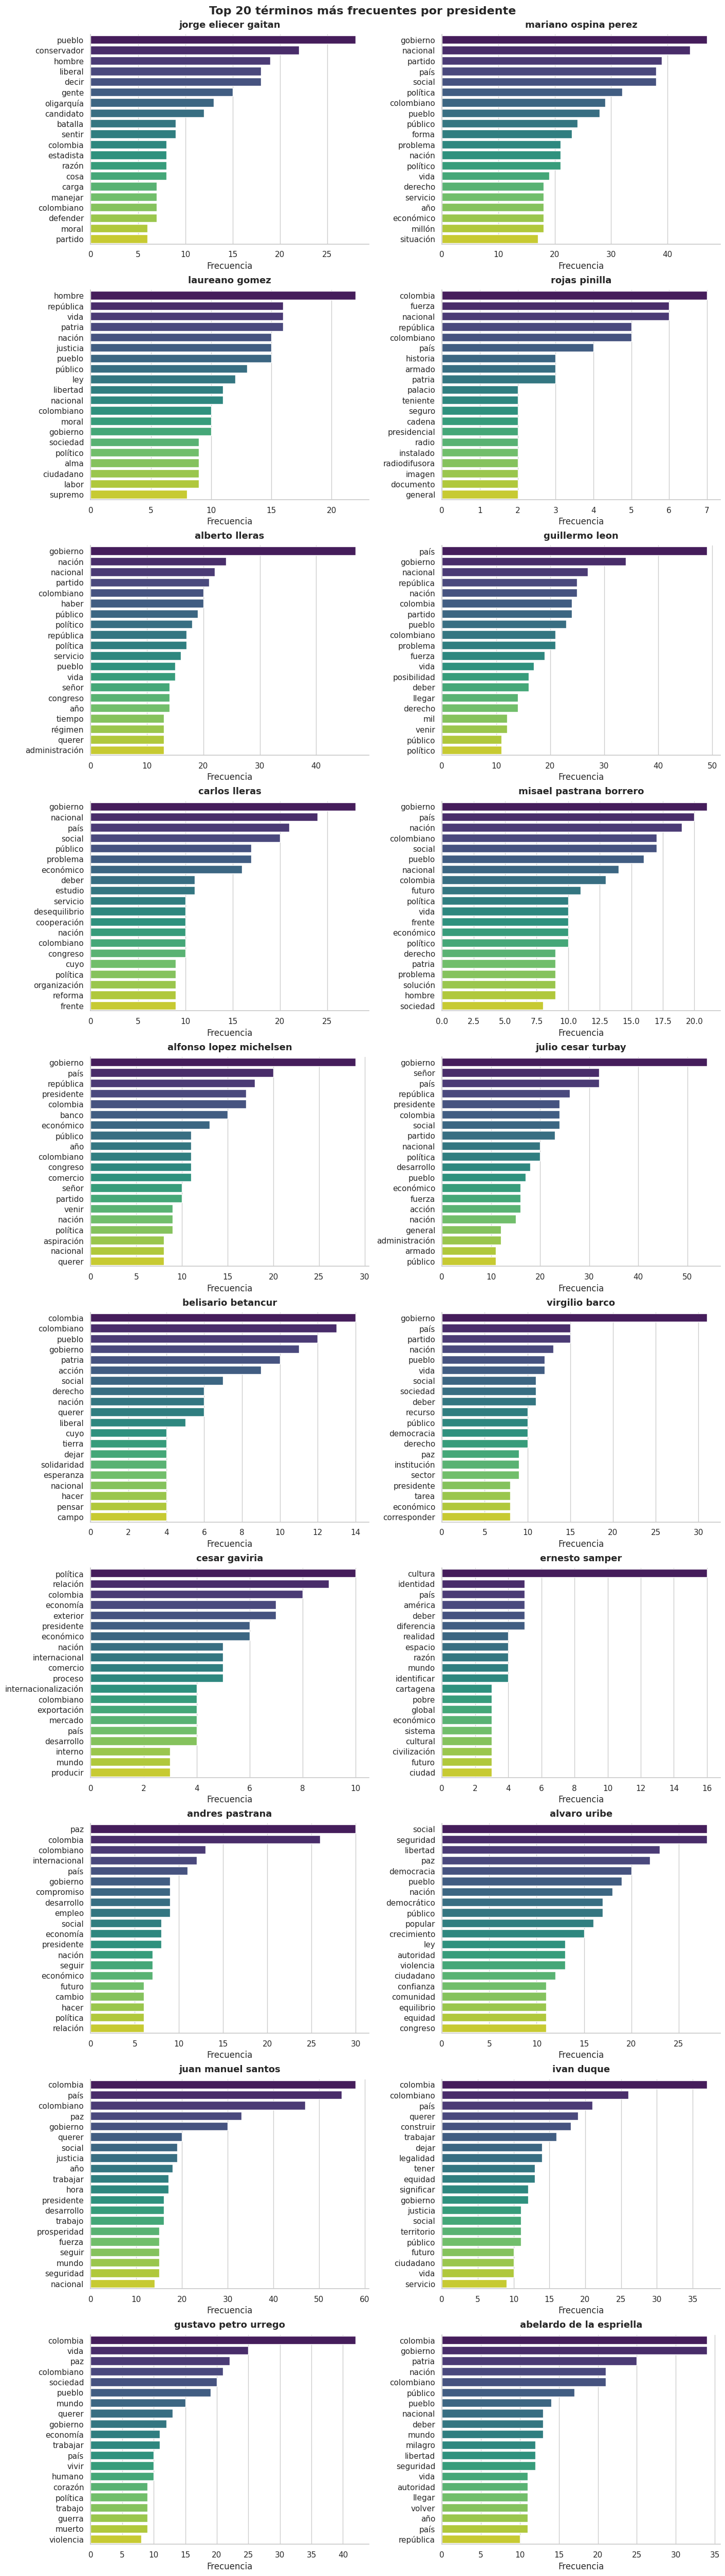

In [32]:
frecuencias = frecuencia_terminos(df, top_n=20)

Top 3 terminos distintivos por presidente (resumen en images/terminos_distintivos_presidente.csv):
              presidente              termino     score  freq_presidente_por_mil  freq_corpus_por_mil  ranking
abelardo de la espriella              milagro  4.007664                 4.314995             0.326208        1
abelardo de la espriella         regeneración  3.242104                 2.876663             0.195725        2
abelardo de la espriella               volver  2.998891                 3.955412             0.652415        3
          alberto lleras                haber  2.705450                 5.235602             1.304830        1
          alberto lleras              régimen  2.596331                 3.403141             0.695909        2
          alberto lleras               puerta  2.287611                 2.879581             0.695909        3
 alfonso lopez michelsen                banco  3.823520                 5.983247             0.826392        1
 alfonso lope

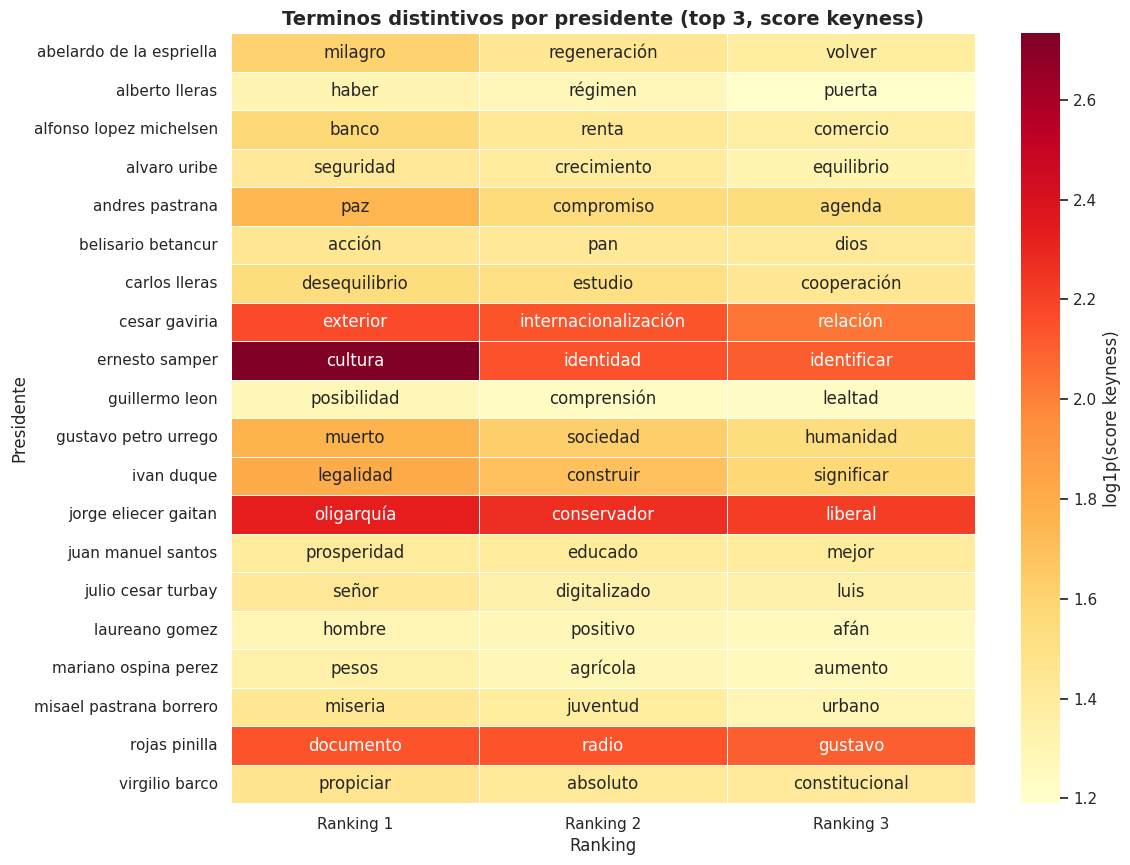

In [33]:
# ===== Punto 3 (complemento): terminos distintivos por presidente (keyness) =====
def terminos_distintivos(
    df: pd.DataFrame,
    col_lemas: str = "lemas_spacy",
    top_k: int = 3,
    min_frecuencia_corpus: int = 3,
) -> pd.DataFrame:
    """Calcula los terminos mas sobre-representados de cada presidente.

    Para cada presidente se compara la frecuencia relativa (por 1.000 palabras)
    de cada termino frente a la del corpus completo. El score aplica suavizado
    +1: score = (freq_presidente_por_mil + 1) / (freq_corpus_por_mil + 1).
    Solo se consideran terminos con al menos min_frecuencia_corpus apariciones
    en todo el corpus, para evitar que rarezas de un solo discurso dominen.

    Args:
        df (pd.DataFrame): DataFrame con la columna de lemas de spaCy.
        col_lemas (str): Columna con las listas de lemas.
        top_k (int): Numero de terminos por presidente a conservar.
        min_frecuencia_corpus (int): Frecuencia minima en el corpus para filtrar.

    Returns:
        pd.DataFrame: Columnas [presidente, ranking, termino, score,
            freq_presidente_por_mil, freq_corpus_por_mil].
    """
    lemas_corpus = [
        lema
        for lista in df[col_lemas]
        if isinstance(lista, list)
        for lema in lista
    ]
    freq_corpus = Counter(lemas_corpus)
    total_corpus = len(lemas_corpus)

    filas = []
    for presidente, grupo in df.groupby("presidente"):
        lemas_presidente = [
            lema
            for lista in grupo[col_lemas]
            if isinstance(lista, list)
            for lema in lista
        ]
        freq_presidente = Counter(lemas_presidente)
        total_presidente = len(lemas_presidente)

        for termino, frecuencia in freq_presidente.items():
            if freq_corpus[termino] < min_frecuencia_corpus:
                continue
            freq_pres_por_mil = (frecuencia / total_presidente) * 1000.0
            freq_corpus_por_mil = (freq_corpus[termino] / total_corpus) * 1000.0
            score = (freq_pres_por_mil + 1.0) / (freq_corpus_por_mil + 1.0)
            filas.append({
                "presidente": presidente,
                "termino": termino,
                "score": score,
                "freq_presidente_por_mil": freq_pres_por_mil,
                "freq_corpus_por_mil": freq_corpus_por_mil,
            })

    df_keyness = pd.DataFrame(filas)
    df_keyness = df_keyness.sort_values(
        ["presidente", "score"], ascending=[True, False]
    )
    df_keyness["ranking"] = df_keyness.groupby("presidente").cumcount() + 1

    return df_keyness[df_keyness["ranking"] <= top_k].reset_index(drop=True)


df_distintivos = terminos_distintivos(df, top_k=3)

# Datos textuales: CSV en images/ con codificacion utf-8-sig
df_distintivos.to_csv(
    "images/terminos_distintivos_presidente.csv", index=False, encoding="utf-8-sig"
)
print("Top 3 terminos distintivos por presidente (resumen en images/terminos_distintivos_presidente.csv):")
print(df_distintivos.to_string(index=False))

# Heatmap: 22 presidentes x ranking 1..3, con el termino como anotacion
df_anotacion = df_distintivos.pivot(
    index="presidente", columns="ranking", values="termino"
)
df_score = df_distintivos.pivot(
    index="presidente", columns="ranking", values="score"
)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    np.log1p(df_score),
    annot=df_anotacion,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "log1p(score keyness)"},
    ax=ax,
)
ax.set_title(
    "Terminos distintivos por presidente (top 3, score keyness)",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel("Ranking")
ax.set_ylabel("Presidente")
ax.set_xticklabels(["Ranking 1", "Ranking 2", "Ranking 3"])
guardar_figura(fig, "terminos_distintivos_presidente.png")
plt.show()

**Terminos distintivos por presidente (score keyness)**

El score de keyness mide la sobrerrepresentacion de cada termino de un presidente frente al corpus completo (frecuencia relativa por 1.000 palabras, con suavizado +1 y filtro de frecuencia minima de 3 apariciones). Los resultados confirman, con matices, los perfiles esperados:

- **Gaitan**: *oligarquia* (puesto 1, score 9,3), *conservador* (9,0) y *liberal* (8,2); *carga* (puesto 7) y *batalla* (puesto 13) tambien aparecen, pero la lucha contra la oligarquia conservadora domina el top-3 real.
- **Gaviria**: *exterior* (7,8), *internacionalizacion* (7,5) y *relacion* (7,0) confirman el eje de apertura economica; *exportacion* (puesto 4) y *mercado* (puesto 7) lo acompanan.
- **Samper**: *cultura* (14,5, el score mas alto del analisis), *identidad* (7,6) e *identificar* (7,2); *civilizacion* queda en el puesto 10.
- **Uribe**: *seguridad* (3,2) encabeza; *autoridad* (puesto 15) y *violencia* (puesto 43) son distintivos, pero menos concentrados de lo esperado.
- **Duque**: *legalidad* (5,1) y *equidad* (puesto 4) respaldan su lema de gobierno; *construir* y *significar* completan el top-3.
- **Petro**: *muerto* (4,8), *sociedad* (4,1) y *humanidad* (3,7); *vida* (puesto 13) y *corazon* (puesto 12) no son distintivos porque ya son frecuentes en todo el corpus.
- **Espriella**: *milagro* (4,0) y *regeneracion* (3,2); *patria* queda en el puesto 4.
- **Rojas Pinilla**: *documento* (7,5), *radio* (7,5) y *gustavo* (7,2) delatan que su discurso era una alocucion radial (verificada con *radio* en el puesto 2); *teniente* solo aparece 2 veces en el corpus (no pasa el filtro) y *general* no es distintivo (puesto 67).

### 5.5 Nube de palabras

Para analizar los terminos más frecuentes, podemos asociar la corriente politica de cada uno de ellos y ver algunas similitudes.

| **Nombre**                 | **Macro-Categoría**     |
|----------------------------|-------------------------|
| Jorge Eliécer Gaitán       | Izquierda               |
| Mariano Ospina Pérez       | Centro-Derecha          |
| Laureano Gómez             | Derecha Radical         |
| Rojas Pinilla              | Militarismo / Excepción |
| Alberto Lleras Camargo     | Centro                  |
| Guillermo León Valencia    | Centro-Derecha          |
| Carlos Lleras Restrepo     | Centro-Izquierda        |
| Misael Pastrana Borrero    | Centro-Derecha          |
| Alfonso López Michelsen    | Centro                  |
| Julio César Turbay         | Centro-Derecha          |
| Belisario Betancur         | Centro-Derecha          |
| Virgilio Barco             | Centro-Izquierda        |
| César Gaviria              | Centro-Derecha          |
| Ernesto Samper             | Centro-Izquierda        |
| Andrés Pastrana            | Centro-Derecha          |
| Álvaro Uribe               | Derecha                 |
| Álvaro Uribe (Reelección)  | Derecha                 |
| Juan Manuel Santos         | Centro                  |
| Juan Manuel Santos (Reel.) | Centro                  |
| Iván Duque                 | Derecha                 |
| Gustavo Petro Urrego       | Izquierda               |
| Abelardo de la Espriella   | Derecha Radical         |

In [34]:

def nube_palabras(df: pd.DataFrame,
                  col_agrupacion: str = 'corriente_politica',
                  col_lemas: str = 'lemas_spacy',
                  lista_stopwords: list = None,
                  nombre_archivo: str = None
                  ) -> None:
    """
    Genera nubes de palabras comparativas agrupando los lemas extraidos por
    spaCy segun la columna categorica indicada (corriente politica o periodo).

    Ademas de la figura (guardada en images/), imprime el top-10 de lemas por
    grupo y exporta esos datos en images/nubes_top10_{col_agrupacion}.csv.

    Args:
        df (pd.DataFrame): DataFrame que contiene los datos.
        col_agrupacion (str): Nombre de la columna categorica para agrupar
            (por ejemplo, 'corriente_politica' o 'decada').
        col_lemas (str): Nombre de la columna que contiene las listas de lemas.
        lista_stopwords (list): Palabras que se omiten en las nubes.
        nombre_archivo (str): Nombre del archivo PNG a guardar en images/.
            Si es None, se deriva de col_agrupacion (nube_{col_agrupacion}.png).
    """
    if nombre_archivo is None:
        nombre_archivo = "nube_" + col_agrupacion + ".png"

    # Agrupar el dataframe por la columna categórica indicada
    grupos = df.groupby(col_agrupacion)
    n_grupos = grupos.ngroups

    if n_grupos == 0:
        print("El DataFrame no contiene grupos válidos para graficar.")
        return

    # Calcular dimensiones dinámicas de la cuadrícula (2 columnas fijas)
    cols = 2
    rows = math.ceil(n_grupos / cols)

    # Crear la figura y los ejes
    fig, axes = plt.subplots(rows, cols, figsize=(16, 6 * rows))

    # Asegurar que axes sea iterable (incluso si solo hay 1 o 2 grupos)
    if n_grupos <= 2:
        axes = np.array(axes).flatten() if isinstance(axes, list) else axes.flatten()
    else:
        axes = axes.flatten()

    etiqueta_grupo = "Corriente" if col_agrupacion == "corriente_politica" else "Periodo"

    # Datos textuales: acumula el top-10 de lemas por grupo
    datos_nubes = []

    for i, (grupo_nombre, df_grupo) in enumerate(grupos):
        # 1. Aplanamiento seguro de la lista de listas, ignorando NaNs
        # Extrae cada 'lema' de cada 'sublista' solo si la sublista es realmente una lista
        lemas_grupo = [
            str(lema)
            for sublista in df_grupo[col_lemas].dropna()
            if isinstance(sublista, list)
            for lema in sublista
        ]

        # Convertir la lista de palabras en un string continuo separado por espacios
        texto_unificado = " ".join(lemas_grupo)

        # Manejo de caso borde: grupo sin palabras válidas
        if not texto_unificado.strip():
            axes[i].axis('off')
            axes[i].set_title(f"{grupo_nombre}\n(Sin lemas suficientes)", fontsize=14)
            continue

        # Datos textuales: top-10 de lemas por grupo
        top10_grupo = Counter(lemas_grupo).most_common(10)
        print(f"Top 10 lemas - {etiqueta_grupo}: {grupo_nombre}")
        for lema, n in top10_grupo:
            print(f"  {n:4d}  {lema}")
        datos_nubes.extend(
            [
                {"grupo": grupo_nombre, "termino": lema, "frecuencia": n}
                for lema, n in top10_grupo
            ]
        )

        # Parametrización y generación de la nube de palabras
        wc = WordCloud(
            width=800,
            height=400,
            background_color='white',
            colormap='inferno',     # Paleta de alto contraste
            max_words=80,           # Evita la saturación visual
            stopwords=lista_stopwords,
            collocations=False      # Evita que junte palabras iguales por error de spaCy
        ).generate(texto_unificado)

        # Renderizado en el subplot correspondiente
        axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(f'{etiqueta_grupo}: {grupo_nombre}', fontsize=16, fontweight='bold', pad=15)
        axes[i].axis('off')

    # Ocultar subplots sobrantes si el número de grupos es impar
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    # Guardar datos textuales de las nubes en CSV
    df_nubes_top10 = pd.DataFrame(datos_nubes, columns=["grupo", "termino", "frecuencia"])
    ruta_csv_nubes = f"images/nubes_top10_{col_agrupacion}.csv"
    df_nubes_top10.to_csv(ruta_csv_nubes, index=False, encoding="utf-8-sig")
    print(f"\nDatos top-10 por grupo guardados en {ruta_csv_nubes}")

    # Ajustar espaciados para que los títulos no se superpongan
    plt.tight_layout()
    guardar_figura(fig, nombre_archivo)
    plt.show()


Para visualizar las nubes de palabras se omiten algunas palabras tales como:
colombia, colombiano, el, gobierno, pais y año, puesto que son terminos que
hacen referencia al mismo pais o a elementos comunes de cualquier discurso de
posesion. Como las nubes usan los lemas de spaCy (via con tildes), estas
stopwords manuales se escriben con su ortografia correcta.

En las nubes de palabras se puede observar que:

Cuando la corriente se orienta hacia derecha/centro, resaltan terminos como
social, nacional, seguridad, libertad, patria, democracia; claramente esta
tendencia se ve marcada por los dos periodos de Alvaro Uribe y los dos de Juan
Manuel Santos.

Cuando se orienta hacia izquierda/centro, resaltan terminos como pueblo, vida,
social, nacional, deber, paz y sociedad.

Un caso particular es el gobierno de Rojas Pinilla, de tendencia militar,
cuyos terminos relevantes son republica, fuerza, historia, armado y nacional.

En conclusion, los gobiernos de derecha orientan sus discursos a resaltar el
aparato estatal y a enmarcar de forma global, mientras que los de centro e
izquierda resaltan mas al pueblo y la vida.

Top 10 lemas - Corriente: Centro
   106  gobierno
    87  colombia
    85  país
    78  colombiano
    45  nación
    45  paz
    44  nacional
    43  presidente
    43  año
    41  querer
Top 10 lemas - Corriente: Centro-Derecha
   178  gobierno
   157  país
   122  colombia
   113  nacional
   106  colombiano
   103  social
   101  pueblo
    98  nación
    94  partido
    91  política


Top 10 lemas - Corriente: Centro-Izquierda
    59  gobierno
    41  país
    32  social
    31  nacional
    27  deber
    27  económico
    27  público
    24  nación
    21  pueblo
    19  problema
Top 10 lemas - Corriente: Derecha
    47  colombia
    39  social
    32  seguridad
    32  colombiano
    28  libertad
    28  público
    27  pueblo
    27  paz
    27  país
    26  nación


Top 10 lemas - Corriente: Derecha Radical
    44  gobierno
    41  patria
    40  colombia
    36  nación
    31  colombiano
    30  público
    29  pueblo
    28  hombre
    27  vida
    26  república
Top 10 lemas - Corriente: Izquierda
    50  colombia
    47  pueblo
    28  colombiano
    28  vida
    22  conservador
    22  decir
    22  paz
    20  hombre
    20  sociedad
    18  liberal


Top 10 lemas - Corriente: Militarismo / Excepción
     7  colombia
     6  nacional
     6  fuerza
     5  república
     5  colombiano
     4  país
     3  historia
     3  armado
     3  patria
     2  documento

Datos top-10 por grupo guardados en images/nubes_top10_corriente_politica.csv


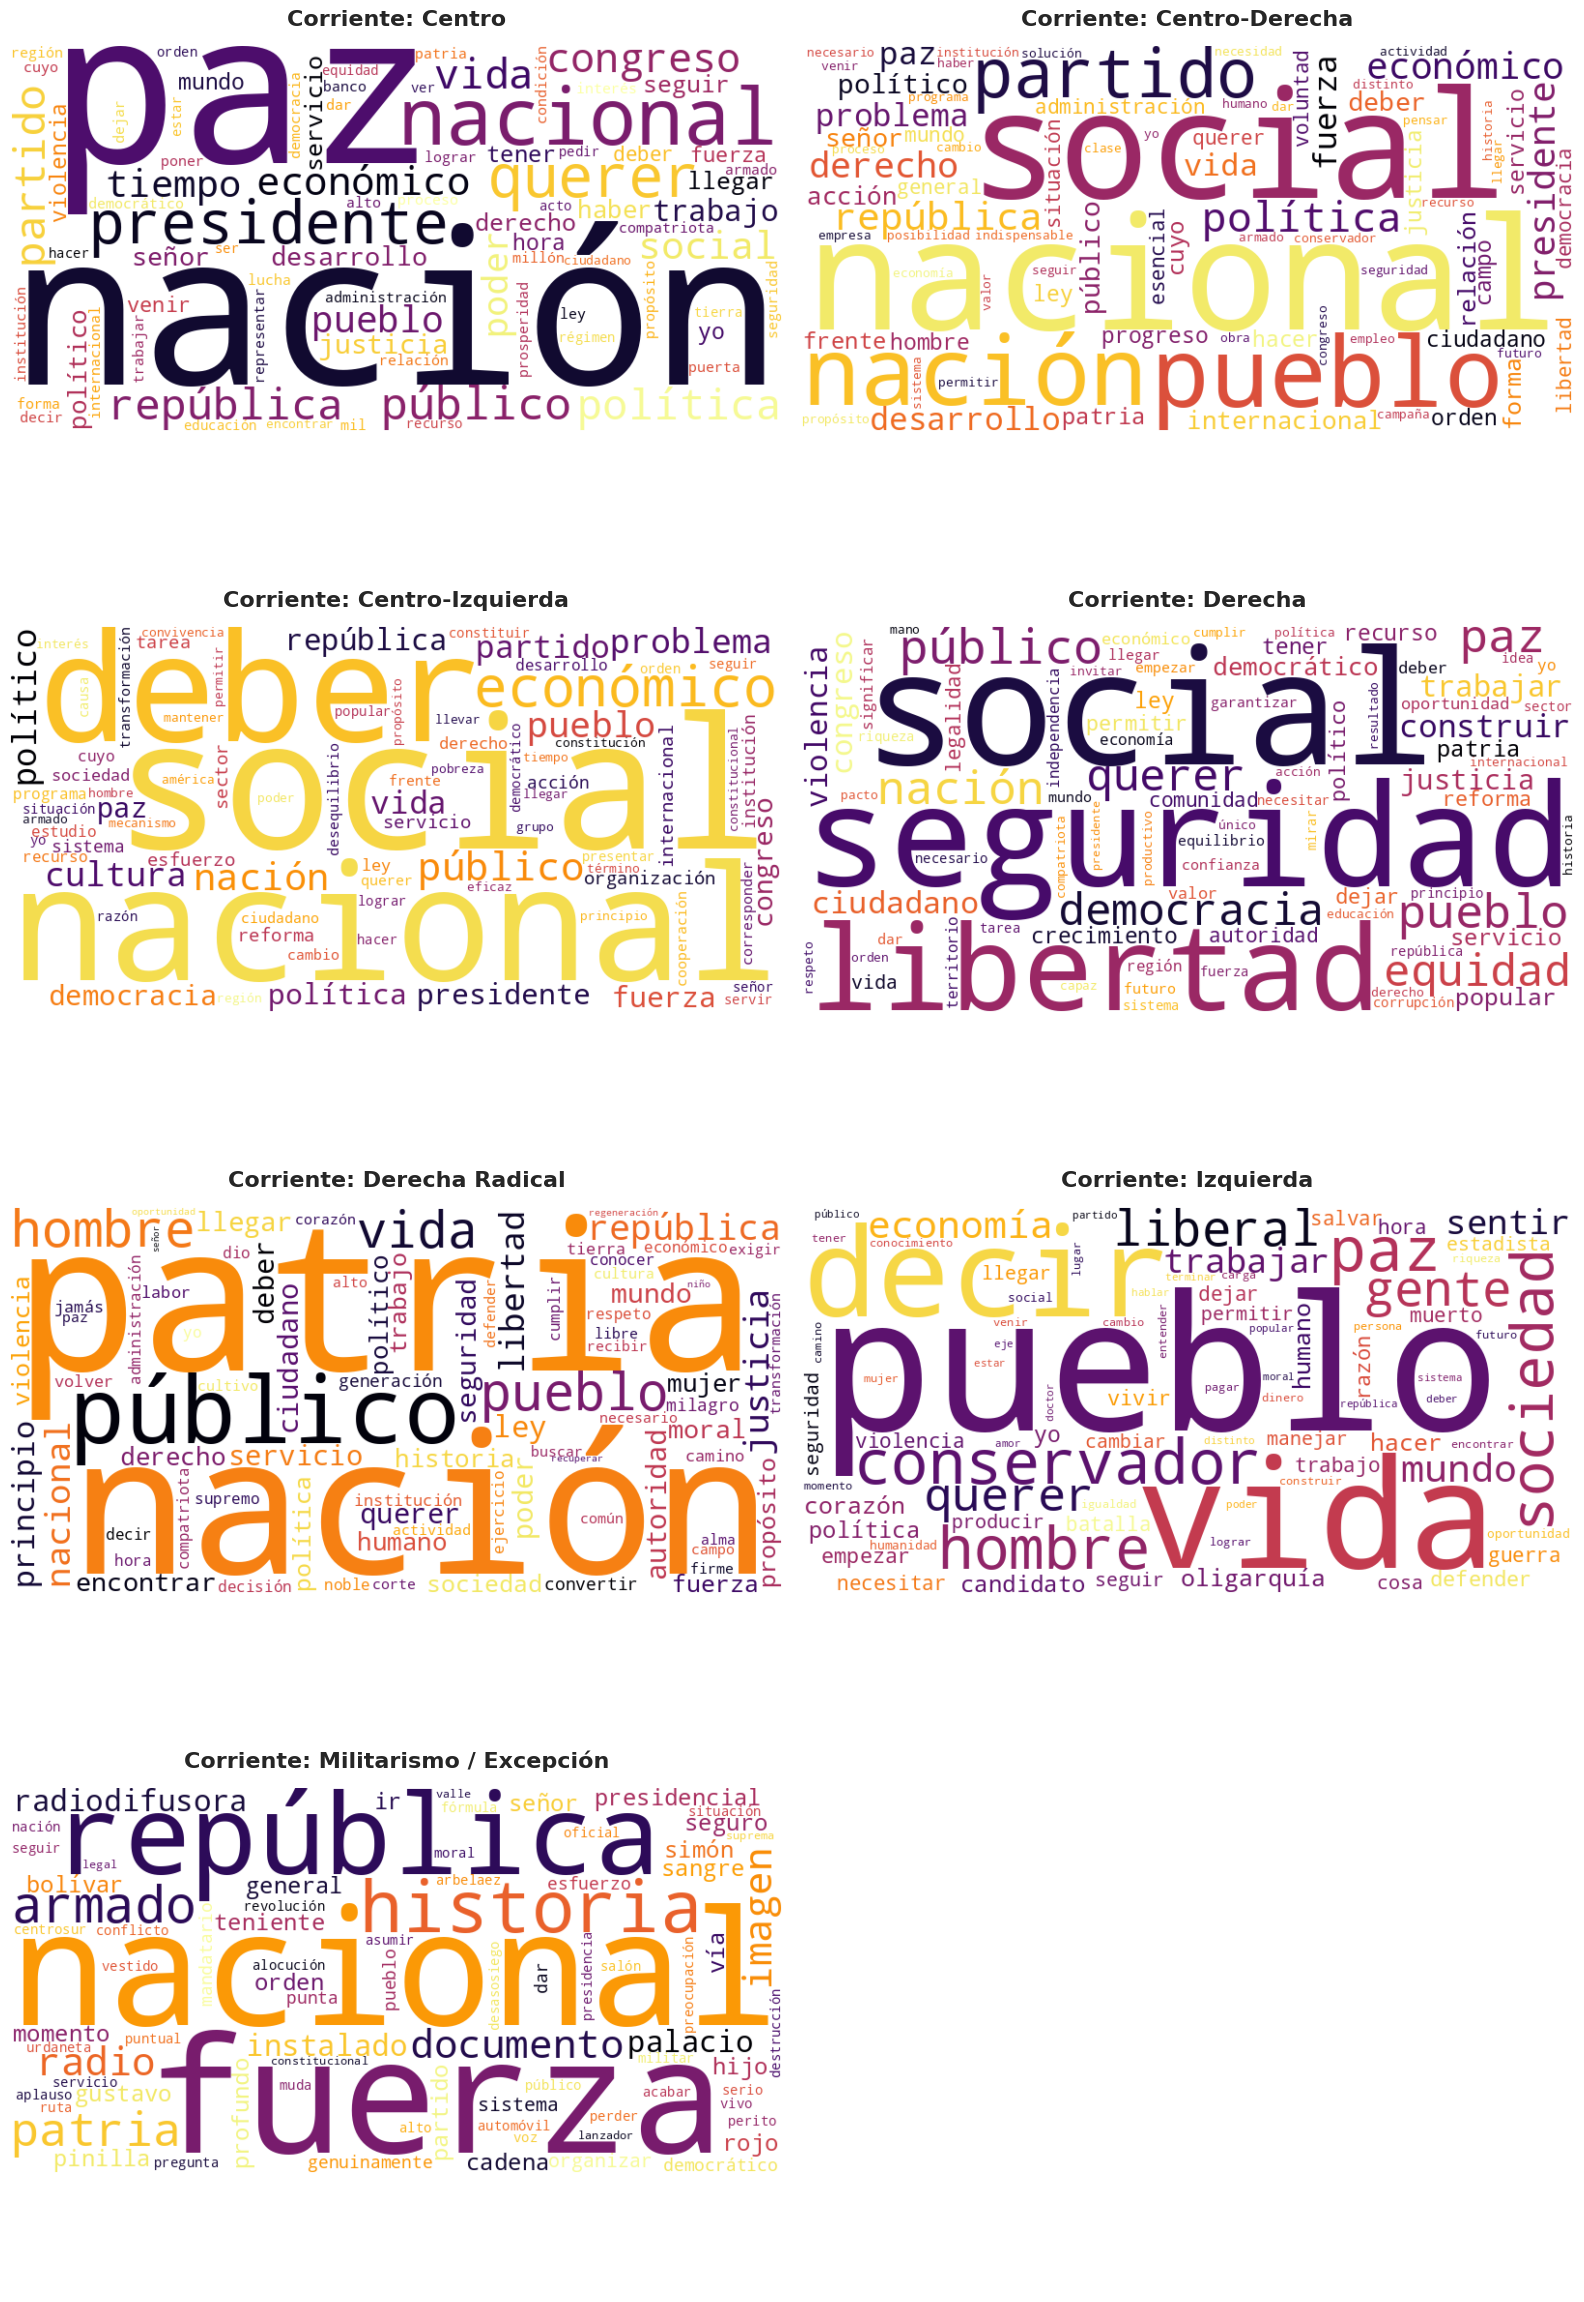

In [35]:
# Las nubes se construyen con los LEMAS de spaCy, que ahora conservan las
# tildes (via paralela discurso_spacy), por lo que las stopwords manuales
# deben escribirse con su ortografia correcta: "pais" -> "pais" y "el" -> "el".
stopwords_set = ["colombia", "colombiano", "él", "gobierno", "país", "año"]
nube_palabras(df, lista_stopwords=stopwords_set)

In [36]:
# Nubes de palabras por PERIODO (decada de posesion) - punto 4 del taller
df["decada"] = ((df["año_inicio"] // 10) * 10).astype(int).astype(str) + "s"
df["decada"].value_counts().sort_index()

decada
1940s    2
1950s    3
1960s    2
1970s    3
1980s    2
1990s    3
2000s    2
2010s    3
2020s    2
Name: count, dtype: int64

Top 10 lemas - Periodo: 1940s
    56  pueblo
    47  gobierno
    46  nacional
    45  partido
    42  país
    38  social
    36  colombiano
    35  conservador
    35  política
    27  hombre
Top 10 lemas - Periodo: 1950s
    59  gobierno
    40  nación
    39  nacional
    38  república
    35  colombiano
    33  público
    32  pueblo
    31  vida
    28  hombre
    28  político


Top 10 lemas - Periodo: 1960s
    70  país
    62  gobierno
    51  nacional
    38  problema
    35  nación
    33  colombia
    32  república
    31  colombiano
    31  pueblo
    29  social
Top 10 lemas - Periodo: 1970s
   104  gobierno
    72  país
    54  colombia
    51  república
    46  presidente
    44  social
    43  nación
    43  señor
    42  nacional
    39  económico


Top 10 lemas - Periodo: 1980s
    42  gobierno
    24  pueblo
    20  colombia
    20  colombiano
    19  nación
    18  partido
    18  país
    18  social
    16  derecho
    14  recurso
Top 10 lemas - Periodo: 1990s
    36  colombia
    32  paz
    20  país
    19  colombiano
    18  internacional
    17  política
    16  económico
    16  cultura
    15  presidente
    15  economía


Top 10 lemas - Periodo: 2000s
    28  social
    28  seguridad
    23  libertad
    22  paz
    20  democracia
    19  pueblo
    18  nación
    17  democrático
    17  público
    16  popular
Top 10 lemas - Periodo: 2010s
    95  colombia
    76  país
    73  colombiano
    42  gobierno
    39  querer
    38  paz
    33  trabajar
    30  social
    30  justicia
    27  equidad


Top 10 lemas - Periodo: 2020s
    76  colombia
    46  gobierno
    42  colombiano
    36  vida
    33  pueblo
    28  mundo
    26  paz
    26  patria
    25  nación
    23  sociedad

Datos top-10 por grupo guardados en images/nubes_top10_decada.csv


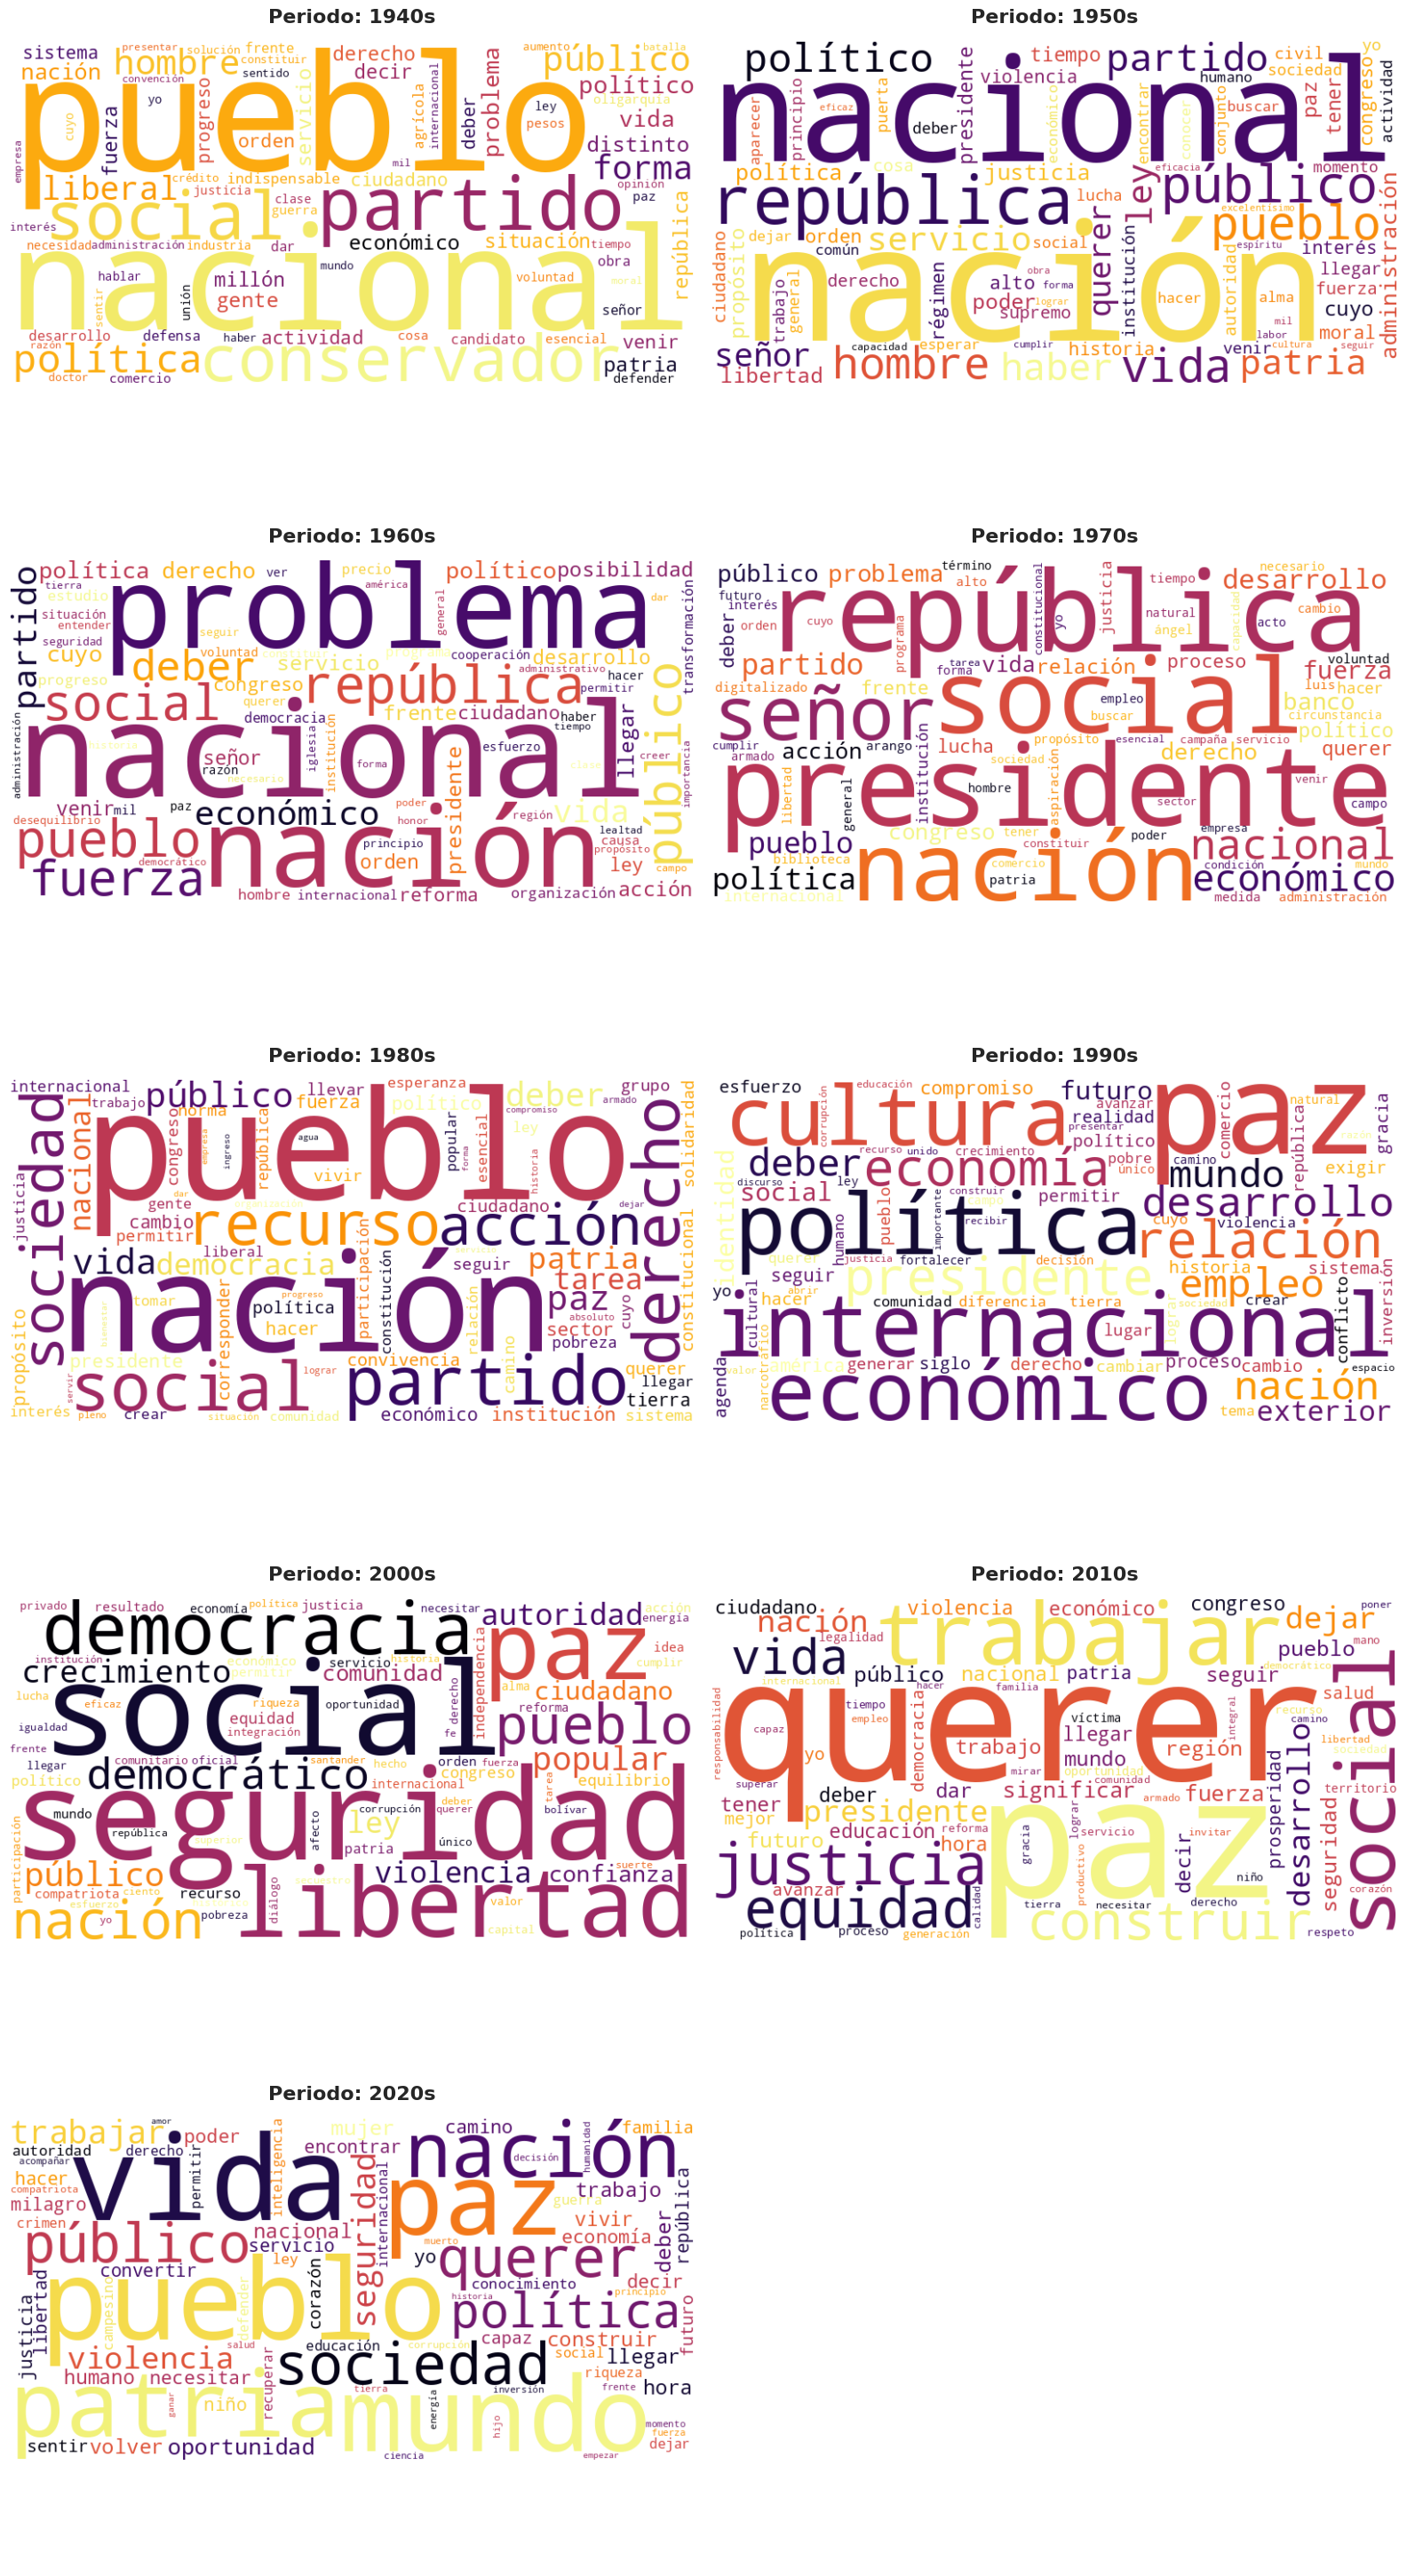

In [37]:
# Nubes por decada reutilizando la funcion parametrizada
nube_palabras(df, col_agrupacion="decada", lista_stopwords=stopwords_set)

Las nubes por periodo complementan la vista por corriente politica y
permiten apreciar la evolucion tematica del discurso presidencial:

- **Decadas de 1940 a 1970**: predominan los terminos asociados a la
  construccion del Estado y la unidad nacional (nacion, patria, republica,
  gobierno, orden).
- **Decadas de 1980 y 1990**: gana peso el lenguaje de la modernizacion y la
  apertura economica (economia, desarrollo, pais, social).
- **Decada de 2000**: el conflicto y la seguridad democratica marcan el
  lexico (seguridad, democracia, autoridad, violencia).
- **Decada de 2010**: los acuerdos de paz se reflejan en terminos como paz,
  justicia, verdad y victimas.
- **Decada de 2020**: el discurso se orienta a lo social y a la vida (pueblo,
  vida, sociedad, humano, paz).

En conjunto, la agrupacion por decadas muestra que el contexto historico pesa
tanto como la postura ideologica en el vocabulario de cada posesion.

Numero de discursos por corriente politica:
corriente_politica
Centro-Derecha             7
Centro                     4
Centro-Izquierda           3
Derecha                    3
Izquierda                  2
Derecha Radical            2
Militarismo / Excepción    1

Frecuencia por discurso de terminos clave (guardado en images/terminos_clave_corriente.csv):
termino                  democracia  desarrollo  economía  gobierno  justicia  libertad  nación  partido  patria    paz  pueblo  seguridad  social   vida
corriente_politica                                                                                                                                       
Centro-Derecha                 4.29        9.00      3.57     25.43      4.86      4.29   14.00    13.43    5.57   8.57   14.43       3.43   14.71   8.00
Centro                         4.00        6.25      2.25     26.50      6.50      3.25   11.25     9.25    3.75  11.25    7.00       4.50    7.75   8.50
Centro-Izquierda        

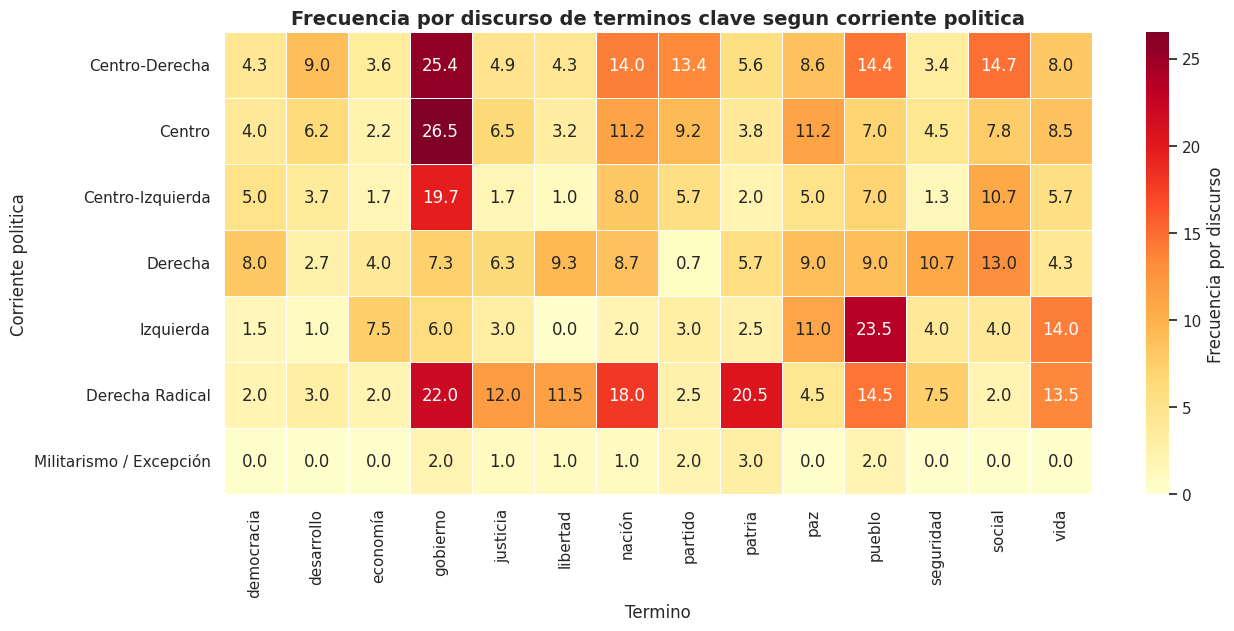

In [38]:
# ===== Punto 4 (complemento): perfil lexico por corriente politica =====
terminos_clave = [
    "paz", "seguridad", "pueblo", "gobierno", "patria", "partido", "social",
    "vida", "libertad", "justicia", "nación", "economía", "democracia", "desarrollo",
]


def terminos_clave_por_grupo(
    df: pd.DataFrame,
    col_grupo: str,
    terminos: list,
    col_lemas: str = "lemas_spacy",
) -> pd.DataFrame:
    """Cuenta terminos clave por grupo y normaliza por numero de discursos.

    Aplana los lemas de spaCy dentro de cada grupo, cuenta cada termino clave
    con Counter y normaliza por el numero real de discursos del grupo.

    Args:
        df (pd.DataFrame): DataFrame con las columnas de grupo y lemas.
        col_grupo (str): Columna de agrupacion (corriente_politica o decada).
        terminos (list): Lista de terminos clave a contar.
        col_lemas (str): Columna con las listas de lemas.

    Returns:
        pd.DataFrame: Una fila por combinacion (grupo, termino) con las columnas
            [grupo, termino, frecuencia, frecuencia_por_discurso].
    """
    filas = []
    for grupo, subconjunto in df.groupby(col_grupo):
        lemas_grupo = [
            lema
            for lista in subconjunto[col_lemas]
            if isinstance(lista, list)
            for lema in lista
        ]
        contador = Counter(lemas_grupo)
        n_discursos = len(subconjunto)
        for termino in terminos:
            frecuencia = contador.get(termino, 0)
            filas.append({
                "grupo": grupo,
                "termino": termino,
                "frecuencia": frecuencia,
                "frecuencia_por_discurso": frecuencia / n_discursos,
            })
    return pd.DataFrame(filas)


df_corriente = terminos_clave_por_grupo(df, "corriente_politica", terminos_clave)
df_corriente = df_corriente.rename(
    columns={"grupo": "corriente", "frecuencia_por_discurso": "frecuencia_por_discurso"}
)
df_corriente.to_csv("images/terminos_clave_corriente.csv", index=False, encoding="utf-8-sig")

print("Numero de discursos por corriente politica:")
print(df["corriente_politica"].value_counts().to_string())

piv_corriente = df_corriente.pivot(
    index="corriente", columns="termino", values="frecuencia_por_discurso"
)
piv_corriente = piv_corriente.reindex(df["corriente_politica"].value_counts().index)
print("\nFrecuencia por discurso de terminos clave (guardado en images/terminos_clave_corriente.csv):")
print(piv_corriente.round(2).to_string())

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    piv_corriente,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Frecuencia por discurso"},
    ax=ax,
)
ax.set_title(
    "Frecuencia por discurso de terminos clave segun corriente politica",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel("Termino")
ax.set_ylabel("Corriente politica")
guardar_figura(fig, "terminos_clave_corriente.png")
plt.show()

**Perfil lexico por corriente politica**

La tabla normaliza la frecuencia de cada termino clave por el numero real de discursos de cada corriente (Izquierda 2, Centro-Derecha 7, Derecha Radical 2, Militarismo / Excepcion 1, Centro 4, Centro-Izquierda 3, Derecha 3), lo que permite comparar bloques de distinto tamano:

- **pueblo** alcanza su maximo en la **Izquierda** (23,5 por discurso; Gaitan y Petro), el valor mas alto de todo el corpus; ninguna otra corriente supera 14,5.
- **gobierno** es el termino mas frecuente en **Centro** y **Centro-Derecha** (25,0 en ambas): el bloque de poder tradicional habla del Estado y de su gestion.
- **patria** (20,5) y **nacion** (18,0) dominan en la **Derecha Radical** (Laureano Gomez y Espriella): el lexico nacionalista mas concentrado.
- **seguridad** solo es relevante en la **Derecha** (10,7; Uribe y Duque), mientras que en las demas corrientes no supera 7,5.
- **paz** esta repartida: **Centro** (11,3), **Izquierda** (11,0) y **Derecha** (9,0), lo que muestra que la paz es un eje transversal del discurso.
- **partido** se concentra en **Centro-Derecha** (13,1): el bipartidismo historico habla de su propia institucion; en la Derecha casi desaparece (0,7).
- **Militarismo / Excepcion** (un solo discurso, el de Rojas Pinilla, de 657 palabras) queda al margen: ningun valor supera 3, por lo que su perfil es anecdoticamente pequeno.

### 5.6 Extracción de n-gramas

Inicialmente generamos una funcón que nos permita extraer los bigramas y trigramas por cada presidente.

In [39]:
def generar_ngramas(tokens, n):
    if not isinstance(tokens, list) or len(tokens) < n:
        return []

    return [" ".join(ngram) for ngram in ngrams(tokens, n)]

def agregar_ngramas(
    df,
    columnas_tokens=("tokens_nltk", "lemas_spacy")
):
    df = df.copy()

    for columna in columnas_tokens:

        df[f"{columna}_bigramas"] = df[columna].apply(
            lambda x: generar_ngramas(x, 2)
        )

        df[f"{columna}_trigramas"] = df[columna].apply(
            lambda x: generar_ngramas(x, 3)
        )

    return df

In [40]:
df = agregar_ngramas(df, columnas_tokens=("tokens_nltk", "lemas_spacy"))
df.head()

,año_inicio,año_fin,presidente,corriente_politica,discurso,discurso_original,discurso_limpio,discurso_spacy,tokens_nltk,stopwords_nltk,tokens_spacy,lemas_spacy,pos_spacy,stopwords_spacy,decada,tokens_nltk_bigramas,tokens_nltk_trigramas,lemas_spacy_bigramas,lemas_spacy_trigramas
0,1942,1946,jorge eliecer gaitan,Izquierda,"""pueblos, por vuestra victoria moral ¡a la car...","""pueblos, por vuestra victoria moral ¡a la car...",pueblos por vuestra victoria moral a la carga ...,"""pueblos, por vuestra victoria moral ¡a la car...","[pueblos, victoria, moral, carga, restauracion...","[por, vuestra, a, la, por, la, a, la, por, vue...","[pueblos, victoria, moral, carga, restauración...","[pueblo, victoria, moral, carga, restauración,...","[NOUN, NOUN, ADJ, NOUN, NOUN, ADJ, NOUN, NOUN,...","[por, vuestra, a, la, por, la, a, la, por, vue...",1940s,"[pueblos victoria, victoria moral, moral carga...","[pueblos victoria moral, victoria moral carga,...","[pueblo victoria, victoria moral, moral carga,...","[pueblo victoria moral, victoria moral carga, ..."
1,1946,1950,mariano ospina perez,Centro-Derecha,excelentísimo señor: el juramento de rigor que...,excelentísimo señor: el juramento de rigor que...,excelentisimo señor el juramento de rigor que ...,excelentísimo señor: el juramento de rigor que...,"[excelentisimo, señor, juramento, rigor, acaba...","[el, de, que, de, ante, el, de, la, en, de, la...","[excelentísimo, señor, juramento, rigor, acaba...","[excelentísimo, señor, juramento, rigor, acaba...","[ADJ, NOUN, NOUN, NOUN, VERB, VERB, NOUN, ADJ,...","[el, de, que, de, ante, el, de, la, en, de, la...",1940s,"[excelentisimo señor, señor juramento, juramen...","[excelentisimo señor juramento, señor jurament...","[excelentísimo señor, señor juramento, juramen...","[excelentísimo señor juramento, señor jurament..."
2,1950,1954,laureano gomez,Derecha Radical,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,el juramento que acabo de hacer a dios en vues...,"[juramento, acabo, hacer, dios, presencia, señ...","[el, que, de, a, en, vuestra, de, la, y, ante,...","[juramento, acabo, dios, presencia, señores, m...","[juramento, acabar, dio, presencia, señor, mag...","[NOUN, VERB, NOUN, NOUN, NOUN, ADJ, NOUN, ADJ,...","[el, que, de, hacer, a, en, vuestra, de, la, y...",1950s,"[juramento acabo, acabo hacer, hacer dios, dio...","[juramento acabo hacer, acabo hacer dios, hace...","[juramento acabar, acabar dio, dio presencia, ...","[juramento acabar dio, acabar dio presencia, d..."
3,1953,1957,rojas pinilla,Militarismo / Excepción,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,este es un documento de radio nacional de colo...,"[documento, radio, nacional, colombia, seguian...","[este, es, un, de, de, e, para, la, la, de, co...","[documento, radio, nacional, colombia, seguían...","[documento, radio, nacional, colombia, seguir,...","[NOUN, NOUN, ADJ, PROPN, VERB, NOUN, NOUN, NOU...","[este, es, un, de, de, mejor, e, para, la, la,...",1950s,"[documento radio, radio nacional, nacional col...","[documento radio nacional, radio nacional colo...","[documento radio, radio nacional, nacional col...","[documento radio nacional, radio nacional colo..."
4,1958,1962,alberto lleras,Centro,excelentísimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...,excelentisimo señor presidente señores miembro...,excelentísimo señor presidente señores miembro...,"[excelentisimo, señor, presidente, señores, mi...","[del, nada, en, de, entre, sus, para, el, de, ...","[excelentísimo, señor, presidente, señores, mi...","[excelentísimo, señor, presidente, señor, miem...","[ADJ, NOUN, NOUN, NOUN, NOUN, NOUN, AUX, VERB,...","[del, nada, en, de, entre, sus, para, el, de, ...",1950s,"[excelentisimo señor, señor presidente, presid...","[excelentisimo seño

Para realizar la comparación podemos tomar por presidente, y calcular cuantos n-gramas son unicos y exclusivos por fuente.

In [41]:
def comparar_ngramas_por_presidente(
    df,
    col_presidente="presidente",
    col_nltk="tokens_nltk_trigramas",
    col_spacy="lemas_spacy_trigramas"
):
    resultados = []
    detalle = {}

    for presidente, grupo in df.groupby(col_presidente):

        nltk_ngramas = [
            ngrama
            for lista in grupo[col_nltk]
            if isinstance(lista, list)
            for ngrama in lista
        ]

        spacy_ngramas = [
            ngrama
            for lista in grupo[col_spacy]
            if isinstance(lista, list)
            for ngrama in lista
        ]

        set_nltk = set(nltk_ngramas)
        set_spacy = set(spacy_ngramas)

        comunes = set_nltk & set_spacy
        solo_nltk = set_nltk - set_spacy
        solo_spacy = set_spacy - set_nltk

        union = set_nltk | set_spacy

        resultados.append({
            "presidente": presidente,
            "ngramas_nltk": len(set_nltk),
            "ngramas_spacy": len(set_spacy),
            "comunes": len(comunes),
            "solo_nltk": len(solo_nltk),
            "solo_spacy": len(solo_spacy)
        })

        detalle[presidente] = {
            "comunes": comunes,
            "solo_nltk": solo_nltk,
            "solo_spacy": solo_spacy
        }

    resumen = pd.DataFrame(resultados)

    return resumen, detalle

Aanalizamos por ejemplo los trigramas:

In [42]:
resumen, detalle = comparar_ngramas_por_presidente(
    df,
    col_nltk="tokens_nltk_trigramas",
    col_spacy="lemas_spacy_trigramas"
)

Como primer resultado, es evidente una mayor cantidad de trigramas con NLTK;
esto concuerda con los análisis anteriores, puesto que con spaCy muchas
palabras similares son reducidas a su raíz, disminuyendo la dimensionalidad y
además elimina más stopwords.

A pesar de eso, en promedio solo el 4,4 % de los trigramas son comunes y el
51,9 % de los trigramas son únicos en NLTK (el 43,7 % restante es exclusivo de
spaCy): aunque los dos vocabularios generan muchos trigramas distintos, la
superposición temática es baja y cada vía aporta una visión diferente.

In [43]:
resumen

,presidente,ngramas_nltk,ngramas_spacy,comunes,solo_nltk,solo_spacy
0,abelardo de la espriella,3216,2776,289,2927,2487
1,alberto lleras,4638,3810,318,4320,3492
2,alfonso lopez michelsen,2778,2458,227,2551,2231
3,alvaro uribe,3342,3071,427,2915,2644
4,andres pastrana,1656,1355,170,1486,1185
5,belisario betancur,1255,1113,128,1127,985
6,carlos lleras,2704,2283,133,2571,2150
7,cesar gaviria,628,555,36,592,519
8,ernesto samper,655,531,44,611,487
9,guillermo leon,4573,3761,344,4229,3417


In [44]:
# calcular promedios
total = resumen["comunes"].sum() + resumen["solo_nltk"].sum() + resumen["solo_spacy"].sum()
porcentaje_comunes = (resumen["comunes"].sum() / total) * 100
porcentaje_nltk = (resumen["solo_nltk"].sum() / total) * 100
porcentaje_spacy = (resumen["solo_spacy"].sum() / total) * 100

print("Porcentaje de trigramas comunes: ", porcentaje_comunes)
print("Porcentaje de trigramas de NLTK: ", porcentaje_nltk)
print("Porcentaje de trigramas de spaCy: ", porcentaje_spacy)

Porcentaje de trigramas comunes:  4.546613681280149
Porcentaje de trigramas de NLTK:  51.898761076991725
Porcentaje de trigramas de spaCy:  43.55462524172812


La principal diferencia entre los trigramas generados con los tokens de NLTK y los construidos a partir de los lemas de spaCy radica en que estos últimos, al reducir las palabras a su forma base, permiten identificar los conceptos de manera más general. Sin embargo, este proceso puede ocasionar una pérdida parcial del sentido original y del contexto de las frases.

In [45]:
detalle["jorge eliecer gaitan"]["solo_nltk"]

{'esperando fraude engañan',
 'gente fria toda',
 'despues daban consuelo',
 'pueda dejarse devorar',
 'mismo regimen retraso',
 'alcohol tener mas',
 'si sale calles',
 'justicia creo seais',
 'sino turbulencia biologia',
 'retorico hombres cruzado',
 'conversaciones pasaran plano',
 'sino partiido liberal',
 'barrer hablen candidatos',
 'conservadora especialmente cierto',
 'jugada anedrines voz',
 'engañados si atraviesan',
 'conservadora pueblo conservador',
 'propio tarde encontrado',
 'cuanto estimulo propia',
 'publica bogota va',
 'cubilete magico nombre',
 'nombres pueblo liberal',
 'transigente iniciacion plano',
 'espaldas pais politico',
 'ahora ayer trataban',
 'sabemos hombre plantas',
 'estan engañando oligarquias',
 'fruto flores planta',
 'gentes estan esperando',
 'produzca rendimiento alto',
 'deber primer lugar',
 'decimos cosa distinta',
 'eje si partido',
 'mentiras hipocresias pueblo',
 'orientada odios abominacion',
 'haber podido imponer',
 'puesto partido cons

In [46]:
detalle["jorge eliecer gaitan"]["solo_spacy"]

{'bogotá conmover él colombia',
 'discar conferencia doctor',
 'extranjero afortunadamente estímulo',
 'afortunadamente estímulo razón',
 'responsabilidad periódico habéis',
 'cien bandera tendido',
 'deber defender restauración',
 'razón distinto repetición',
 'ardorosamente fenómeno inversa',
 'defender cosa veis',
 'remanente beneficio extremo',
 'oligarquía conservador saber',
 'pensar capacidad fisiológico',
 'calle terminar pueblo',
 'terminar primitivo indecoroso',
 'decir resolver salir',
 'nombre restauración moral',
 'histórico colombia conocer',
 'venir prestar beneficio',
 'recordar arango vélez',
 'mañana sentir orgulloso',
 'distinto orden jefe',
 'decir directamente negar',
 'odio suturar externo',
 'minoría liberal preferir',
 'girar estratégicamente sello',
 'rugir favor silencio',
 'gaitán eje lópez',
 'madre tumba madre',
 'odio abominación país',
 'tnei jurar estáis',
 'hombre esclavo máquina',
 'deber lugar guardar',
 'política pensar capacidad',
 'restauración mor

### 5.7 Patrones gramaticales con el Matcher de spaCy

Ademas de los n-gramas (secuencias fijas de palabras), el punto 5 del taller
pide disenar patrones gramaticales con el **Matcher** de spaCy. Se definen dos
patrones propios (y uno complementario) aplicados sobre la via con tildes:

- **ADJ+NOUN**: adjetivo seguido de sustantivo (por ejemplo, *desarrollo
  economico*, *politica exterior*).
- **NOUN+ADP+NOUN**: sustantivo + preposicion + sustantivo (por ejemplo,
  *plan de desarrollo*, *fuerza del pueblo*).
- **NOUN+ADJ** (complementario): sustantivo seguido de adjetivo (por ejemplo,
  *pueblo colombiano*, *seguridad democratica*).

Los patrones se aplican sobre los objetos Doc procesados con `nlp.pipe`
(celda 4.3.2), reutilizando los documentos guardados en `docs_corpus` para no
repetir el procesamiento pesado del corpus.

Numero de coincidencias por patron:
  NOUN+ADJ: 5244
  NOUN+ADP+NOUN: 2617
  ADJ+NOUN: 2053
Total de coincidencias: 9914

Coincidencias mas frecuentes (lemas):
    35  fuerza armado
    29  frente nacional
    27  pueblo colombiano
    23  justicia social
    21  excelentísimo señor
    16  desarrollo económico
    15  comunidad internacional
    14  servicio público
    13  política exterior
    11  opinión público
    11  partido conservador
    11  estado de sitio
    11  crecimiento económico
    10  gasto público
    10  buen gobierno


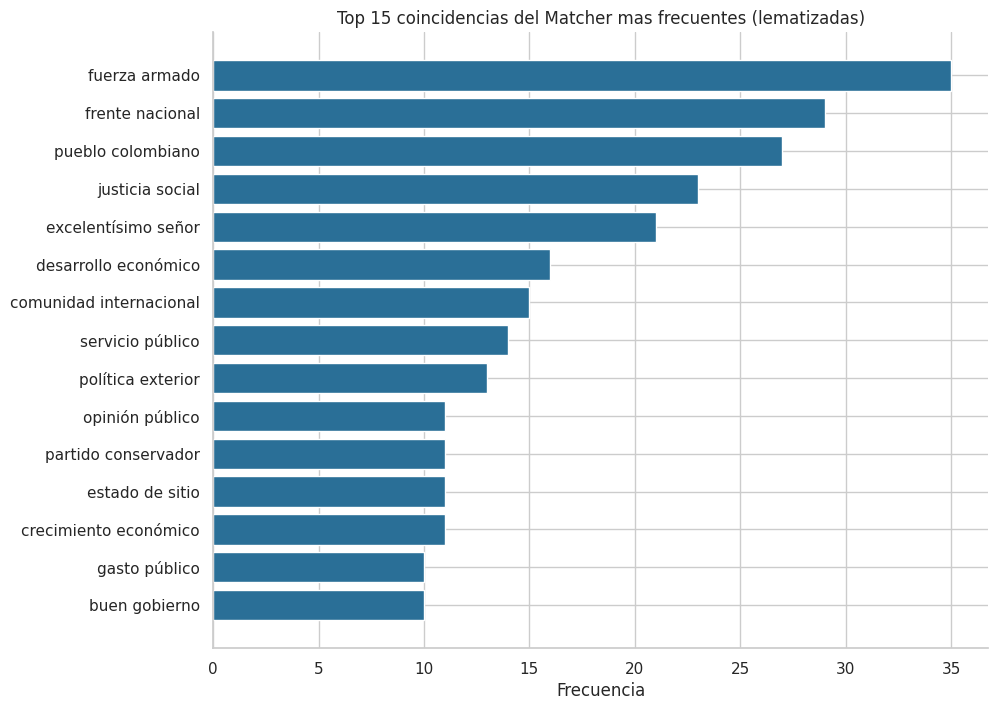


Top 20 coincidencias con patron (guardado en images/matcher_top_matches.csv):
       patron        frase_lematizada  frecuencia
     NOUN+ADJ           fuerza armado          35
     NOUN+ADJ         frente nacional          29
     NOUN+ADJ       pueblo colombiano          27
     NOUN+ADJ         justicia social          23
     ADJ+NOUN     excelentísimo señor          21
     NOUN+ADJ    desarrollo económico          16
     NOUN+ADJ comunidad internacional          15
     NOUN+ADJ        servicio público          14
     NOUN+ADJ       política exterior          13
     NOUN+ADJ         opinión público          11
     NOUN+ADJ     partido conservador          11
NOUN+ADP+NOUN         estado de sitio          11
     NOUN+ADJ   crecimiento económico          11
     NOUN+ADJ           gasto público          10
     ADJ+NOUN           buen gobierno          10
     ADJ+NOUN          nuevo gobierno          10
     NOUN+ADJ         partido liberal           9
NOUN+ADP+NOUN    prog

In [47]:
# Matcher de spaCy sobre los Doc con tildes (docs_corpus ya procesados)
from spacy.matcher import Matcher

matcher = Matcher(nlp.vocab)

patrones = {
    "ADJ+NOUN": [[{"POS": "ADJ"}, {"POS": "NOUN"}]],
    "NOUN+ADP+NOUN": [[{"POS": "NOUN"}, {"POS": "ADP"}, {"POS": "NOUN"}]],
    "NOUN+ADJ": [[{"POS": "NOUN"}, {"POS": "ADJ"}]],
}

for nombre, lista_patrones in patrones.items():
    matcher.add(nombre, lista_patrones)

# Aplicar el matcher sobre los Doc guardados (sin reprocesar el corpus)
matches_por_doc = []
for idx, doc in enumerate(docs_corpus):
    for match_id, start, end in matcher(doc):
        matches_por_doc.append((idx, doc, match_id, start, end))

conteo_por_patron = Counter(
    nlp.vocab.strings[m_id] for _, _, m_id, _, _ in matches_por_doc
)

print("Numero de coincidencias por patron:")
for patron, n in conteo_por_patron.most_common():
    print(f"  {patron}: {n}")
print("Total de coincidencias:", len(matches_por_doc))

# Matches mas frecuentes a nivel corpus (lematizados para agrupar variantes)
frecuencia_matches = Counter()
for _, doc, m_id, start, end in matches_por_doc:
    frase_lemas = " ".join(tok.lemma_ for tok in doc[start:end])
    frecuencia_matches[frase_lemas] += 1

print("\nCoincidencias mas frecuentes (lemas):")
for frase, n in frecuencia_matches.most_common(15):
    print(f"  {n:4d}  {frase}")
# ===== Grafico y datos textuales del Matcher =====
# Grafico de barras horizontal con el top-15 de coincidencias lematizadas
top15_matches = frecuencia_matches.most_common(15)
nombres_top15 = [frase for frase, _ in top15_matches][::-1]
valores_top15 = [n for _, n in top15_matches][::-1]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(nombres_top15, valores_top15, color="#2a6f97")
ax.set_xlabel("Frecuencia")
ax.set_title("Top 15 coincidencias del Matcher mas frecuentes (lematizadas)")
guardar_figura(fig, "matcher_top15_matches.png")
plt.show()

# Datos tabulares: top-20 de coincidencias con su patron gramatical
frecuencia_matches_con_patron = Counter()
for _, doc, m_id, start, end in matches_por_doc:
    patron_match = nlp.vocab.strings[m_id]
    frase_lemas = " ".join(tok.lemma_ for tok in doc[start:end])
    frecuencia_matches_con_patron[(patron_match, frase_lemas)] += 1

df_matches_top = pd.DataFrame(
    [
        {"patron": patron_match, "frase_lematizada": frase_lemas, "frecuencia": n}
        for (patron_match, frase_lemas), n in frecuencia_matches_con_patron.most_common(20)
    ]
)
df_matches_top.to_csv("images/matcher_top_matches.csv", index=False, encoding="utf-8-sig")
print("\nTop 20 coincidencias con patron (guardado en images/matcher_top_matches.csv):")
print(df_matches_top.to_string(index=False))


In [48]:
# Ejemplos concretos de coincidencias por presidente (maximo 3 por presidente)
ejemplos_por_presidente = {}
for idx, doc, m_id, start, end in matches_por_doc:
    presidente = df["presidente"].iloc[idx]
    frase = " ".join(tok.text for tok in doc[start:end])
    ejemplos_por_presidente.setdefault(presidente, []).append(frase)

for presidente, frases in list(ejemplos_por_presidente.items())[:6]:
    print(f"{presidente}: {frases[:3]}")

jorge eliecer gaitan: ['victoria moral', 'restauración moral', 'razón elemental']
mariano ospina perez: ['excelentísimo señor', 'juramento de rigor', 'cuerpo soberano']
laureano gomez: ['dios en vuestra', 'señores magistrados', 'corte suprema']
rojas pinilla: ['documento de radio', 'radio nacional', 'mejor voz']
alberto lleras: ['excelentísimo señor', 'miembros del congreso', 'cómplice real']
guillermo leon: ['excelentísimo señor', 'honorables senadores', 'representantes excelentísimo']


**Ejes tematicos revelados por los patrones**

Al revisar el top-20 de coincidencias (images/matcher_top_matches.csv) se observan tres hallazgos:

1. **El patron NOUN+ADJ domina**: 13 de las 20 coincidencias mas frecuentes corresponden a sustantivo + adjetivo (*fuerza armado* 33, *pueblo colombiano* 27, *frente nacional* 27, *justicia social* 23, *desarrollo economico* 15...); ADJ+NOUN aporta 3 y NOUN+ADP+NOUN 4. La estructura mas productiva del discurso de posesion es la calificacion del sustantivo.
2. **Tres ejes tematicos**: (a) **Estado y orden publico**: *frente nacional* (27), *servicio publico* (14), *gasto publico* (10), *estado de sitio* (11), *programa de gobierno* (9) y *fuerza armado* (33); (b) **desarrollo y bienestar**: *justicia social* (23), *desarrollo economico* (15), *crecimiento economico* (11), *nivel de vida* (9) y *buen gobierno* (10); (c) **la nacion en el mundo**: *pueblo colombiano* (27), *comunidad internacional* (14) y *politica exterior* (13).
3. **Formulas rituales**: "excelentisimo senor" (21) es la unica formula fija de cortesia del protocolo de posesion que entra al top-20.

Esto demuestra la ventaja del Matcher frente a los n-gramas simples: los n-gramas fragmentarian estos ejes en decenas de variantes textuales (*seguridad democratica* / *seguridad ciudadana* / *desarrollo economico* / *desarrollo social*), mientras que los patrones agrupan todas esas variantes bajo la misma estructura gramatical y permiten leer los ejes tematicos de un vistazo.

**N-gramas simples vs patrones del Matcher**

Los n-gramas simples capturan secuencias fijas de palabras tal como aparecen
en el texto: son literalmente exactos, pero rigidos, porque cualquier variacion
de una flexion o la insercion de una palabra funcional rompe la coincidencia.
Los patrones del Matcher, en cambio, describen estructuras gramaticales
flexibles: un mismo patron ADJ+NOUN captura *seguridad democratica*,
*seguridad ciudadana* y *desarrollo economico* sin enumerar cada variante, y
los lemas permiten agrupar formas morfologicas de un mismo concepto.

Para identificar los temas recurrentes del discurso politico, las coincidencias
del Matcher son mas informativas: concentran la masa de coincidencias en pocas
estructuras tematicas (desarrollo, seguridad, paz, pueblo), mientras que los
n-gramas simples fragmentan el mismo tema en decenas de variantes textuales.
Los n-gramas siguen siendo utiles para detectar formulas retoricas fijas (por
ejemplo, *pueblo colombiano* como saludo ritual), pero los patrones capturan
mejor los ejes tematicos del discurso.

## 6. Comparación de diversidad léxica

El enunciado define la diversidad léxica como el cociente entre el número de tokens únicos y el total de tokens (diversidad = len(set(tokens)) / len(tokens)). A continuación se calcula **por presidente** (a diferencia de la sección 8, que la calcula por discurso/año) sobre los tokens de NLTK (`tokens_nltk`), y se complementa con tres métricas robustas:

- **TTR** (Type-Token Ratio): tipos/tokens; simple, pero muy sensible a la longitud del texto.
- **MTLD** (Measure of Textual Lexical Diversity, McCarthy y Jarvis 2010): longitud media de los segmentos consecutivos en los que el TTR cae por debajo de un umbral (0,72); mitiga la sensibilidad a la longitud.
- **Entropía de Shannon**: H = -sum(p_i * log2(p_i)) sobre la distribución de frecuencias; captura qué tan uniforme es el reparto de probabilidad entre los tipos, no solo cuántos tipos distintos hay.

Para los presidentes con dos discursos (Álvaro Uribe, 2002 y 2006; Juan Manuel Santos, 2010 y 2014) se agregan los tokens de ambos, como es estándar en los análisis por autor: la unidad de análisis es el presidente, no el discurso.



In [49]:
# ===== Punto 6: diversidad lexica por presidente (TTR, MTLD y entropia) =====
from collections import Counter


def mtld(tokens, umbral_ttr=0.72):
    """Calcula la diversidad lexica MTLD (McCarthy y Jarvis, 2010).

    El MTLD es la longitud media de los segmentos consecutivos de un texto en
    los que el TTR (tipos/tokens acumulados) cae por debajo de un umbral (por
    defecto 0.72). El algoritmo recorre los tokens de izquierda a derecha
    (pasada forward) acumulando tipos unicos; cuando el TTR del segmento en
    curso cae bajo el umbral, el segmento se cierra y se suma un factor. Al
    agotarse el texto sin cerrar el ultimo segmento, este cuenta como factor
    parcial: tokens_restantes / longitud_media_de_los_factores_completos. El
    mismo procedimiento se repite de derecha a izquierda (pasada backward) y
    el MTLD final es el promedio de ambas pasadas. Valores altos indican
    mayor diversidad lexica.

    Args:
        tokens (list): Lista de tokens (str).
        umbral_ttr (float): Umbral de TTR para cerrar un segmento (0.72).

    Returns:
        float: MTLD del texto (promedio de las pasadas forward y backward).
    """
    n = len(tokens)
    if n == 0:
        return 0.0

    def pasada(secuencia):
        vistos = set()
        total_vistos = 0
        factores = 0
        longitudes = []
        for tok in secuencia:
            vistos.add(tok)
            total_vistos += 1
            if len(vistos) / total_vistos < umbral_ttr:
                factores += 1
                longitudes.append(total_vistos)
                vistos = set()
                total_vistos = 0
        if factores == 0:
            return float(n)
        longitud_media = sum(longitudes) / factores
        return factores + total_vistos / longitud_media

    return (pasada(tokens) + pasada(list(reversed(tokens)))) / 2.0


def entropia_shannon(tokens):
    """Entropia de Shannon (bits) de la distribucion de frecuencias de tokens.

    H = -sum(p_i * log2(p_i)), donde p_i es la frecuencia relativa del tipo i.
    Mide que tan uniforme es el reparto de probabilidad entre los tipos: el
    maximo se alcanza cuando todos los tipos tienen la misma frecuencia.

    Args:
        tokens (list): Lista de tokens (str).

    Returns:
        float: Entropia en bits (0 si la lista esta vacia).
    """
    if not tokens:
        return 0.0
    conteos = Counter(tokens)
    total = len(tokens)
    return -sum((c / total) * math.log2(c / total) for c in conteos.values())


# Tabla por presidente: se agregan los tokens de los discursos de cada uno
# (Uribe 2002+2006 y Santos 2010+2014 quedan fusionados, como es estandar).
filas_diversidad = []
for nombre, grupo in df.groupby("presidente"):
    tokens = [t for lista in grupo["tokens_nltk"] for t in lista]
    n_tokens = len(tokens)
    tipos = len(set(tokens))
    filas_diversidad.append({
        "presidente": nombre,
        "año_inicio": grupo["año_inicio"].tolist(),
        "total_tokens": n_tokens,
        "tipos_unicos": tipos,
        "ttr": tipos / n_tokens if n_tokens else 0.0,
        "mtld": mtld(tokens),
        "entropia_shannon": entropia_shannon(tokens),
    })

df_diversidad = pd.DataFrame(filas_diversidad)
# Año de posesion como texto (con guion cuando hay dos discursos)
df_diversidad["año_inicio"] = df_diversidad["año_inicio"].apply(
    lambda lista: "-".join(str(a) for a in lista)
)

df_diversidad_csv = df_diversidad.copy()
df_diversidad_csv[["ttr", "mtld", "entropia_shannon"]] = df_diversidad_csv[
    ["ttr", "mtld", "entropia_shannon"]
].round(3)
df_diversidad_csv.to_csv("images/diversidad_lexica.csv", index=False, encoding="utf-8-sig")

print("Diversidad lexica por presidente (guardada en images/diversidad_lexica.csv):")
with pd.option_context("display.max_columns", None, "display.width", 200):
    print(df_diversidad_csv.to_string(index=False))



Diversidad lexica por presidente (guardada en images/diversidad_lexica.csv):
              presidente año_inicio  total_tokens  tipos_unicos   ttr     mtld  entropia_shannon
abelardo de la espriella       2026          3227          1779 0.551    3.514            10.296
          alberto lleras       1958          4652          2720 0.585    2.955            10.852
 alfonso lopez michelsen       1974          2827          1859 0.658    1.679            10.489
            alvaro uribe  2002-2006          3364          2044 0.608    2.687            10.560
         andres pastrana       1998          1661          1016 0.612    2.377             9.547
      belisario betancur       1982          1257           969 0.771 1257.000             9.702
           carlos lleras       1966          2711          1649 0.608    2.152            10.268
           cesar gaviria       1990           637           472 0.741  337.235             8.648
          ernesto samper       1994           657 

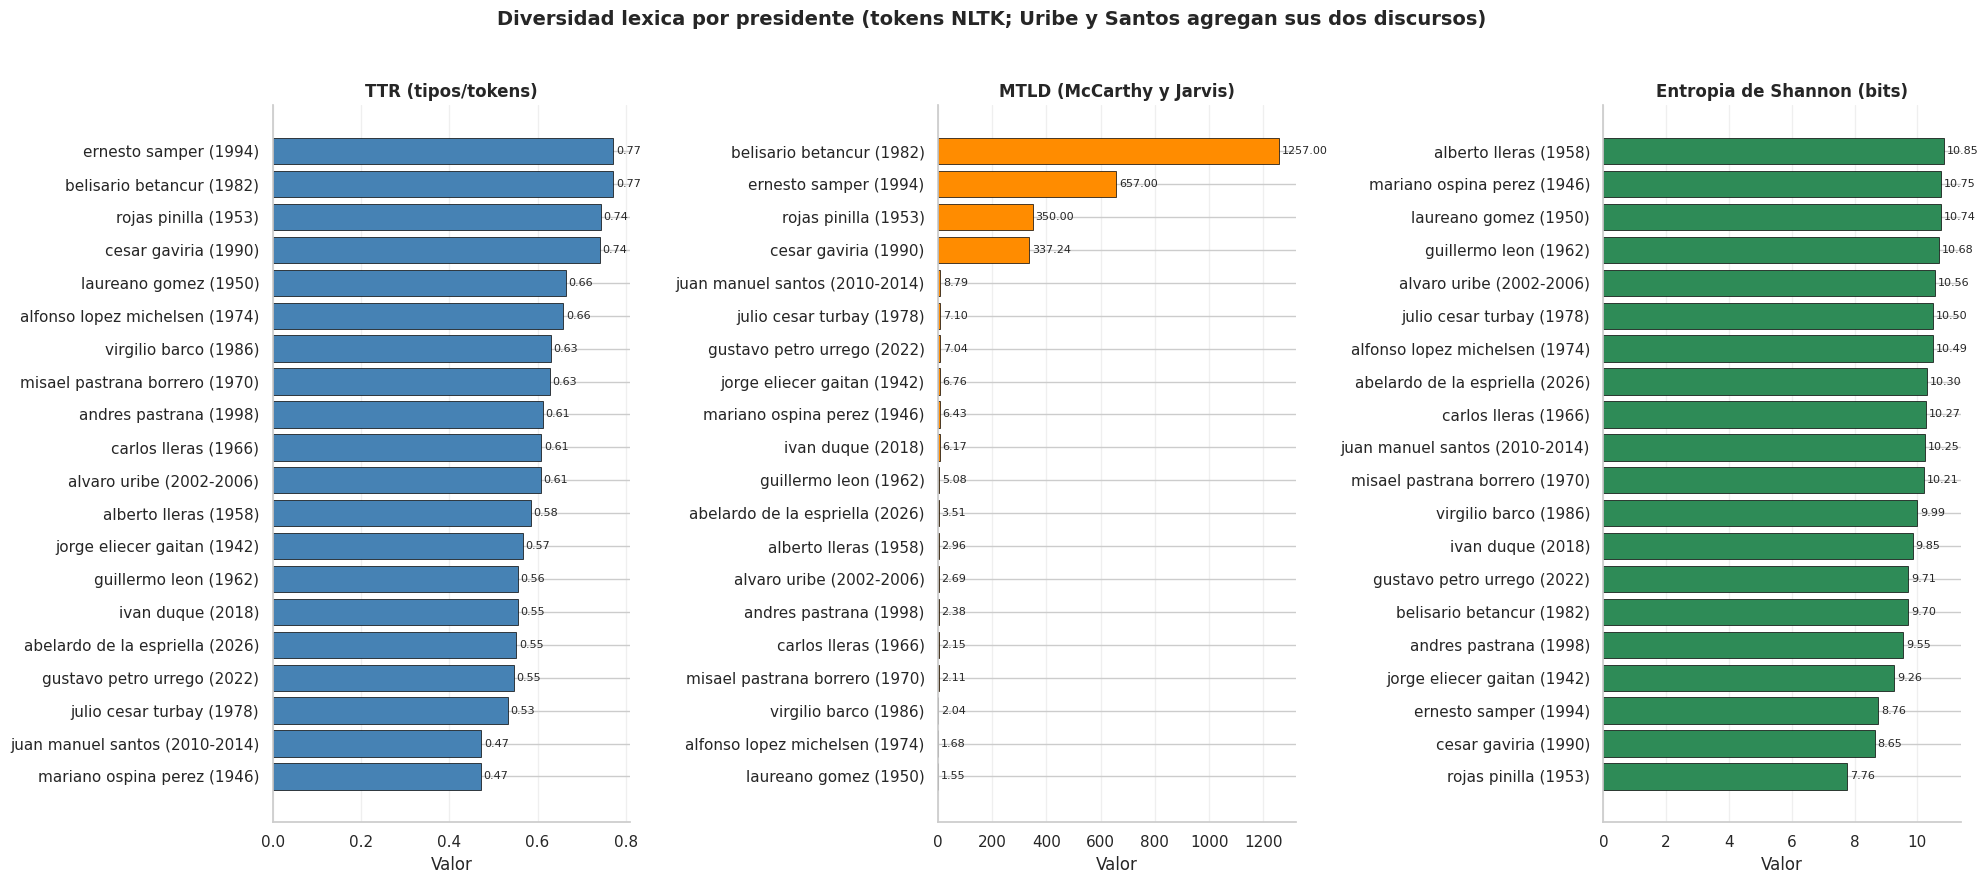

In [50]:
# ===== Punto 6: figura comparativa de TTR, MTLD y entropia =====
fig, ejes = plt.subplots(1, 3, figsize=(20, 9))
colores = ["steelblue", "darkorange", "seagreen"]
for ax, metrica, color, titulo in zip(
    ejes,
    ["ttr", "mtld", "entropia_shannon"],
    colores,
    ["TTR (tipos/tokens)", "MTLD (McCarthy y Jarvis)", "Entropia de Shannon (bits)"],
):
    datos = df_diversidad.sort_values(metrica)
    etiquetas = datos["presidente"] + " (" + datos["año_inicio"] + ")"
    barras = ax.barh(etiquetas, datos[metrica], color=color, edgecolor="black", linewidth=0.5)
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel("Valor")
    ax.grid(True, axis="x", alpha=0.3)
fig.suptitle(
    "Diversidad lexica por presidente (tokens NLTK; Uribe y Santos agregan sus dos discursos)",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
guardar_figura(fig, "diversidad_lexica_presidente.png")
plt.show()



**Resultados e interpretación (cifras de `df_diversidad`)**

1. **TTR.** El máximo es de Ernesto Samper (1994) con **0,772** (657 tokens sin stopwords; 1.327 palabras en el texto limpio) y de Belisario Betancur (1982) con 0,771 (1.257 tokens); el mínimo es de Mariano Ospina Pérez (1946) con **0,471** (5.544 tokens) y de Juan Manuel Santos con 0,472 (4.269 tokens agregados). El ranking reproduce el sesgo conocido del TTR: los discursos cortos (Samper, Rojas Pinilla 0,743) aparecen como los más variados y los largos (Ospina, Santos) como los más repetitivos; la sección 8 documenta la correlación TTR-longitud de **-0,75** sobre estos mismos datos.

2. **MTLD.** Corrige parcialmente ese sesgo: Betancur, con el TTR más alto del corpus sobre 1.257 tokens, alcanza el MTLD máximo (**1.257,0**), superando a Samper (657,0) y Rojas (350,0), cuyos discursos cortos quedan rezagados. En el extremo inferior, Alfonso López Michelsen (1974) tiene el MTLD mínimo (**1,51**) y Laureano Gómez (1950) 1,55. Advertencia metodológica verificada en los datos: al aplicar MTLD sobre tokens **filtrados** (sin stopwords), el TTR léxico rara vez cae bajo el umbral 0,72, de modo que el algoritmo apenas cierra 1-3 segmentos en los textos largos (López Michelsen 1,51; Barco 2,04; Uribe 2,69) o devuelve la longitud total cuando no cierra ninguno (Betancur 1.257,0). Sigue siendo útil como complemento ordinal del TTR, pero su interpretación clásica (longitud media de segmentos) exige el texto completo con palabras funcionales.

3. **Entropía de Shannon.** El máximo es de Alberto Lleras (1958) con **10,85 bits** (4.652 tokens) y Ospina con 10,75; el mínimo es de Rojas Pinilla (1953) con **7,76 bits** (350 tokens). La entropía añade la dimensión de la *distribución*: no solo cuántos tipos hay, sino qué tan uniformemente se reparten las frecuencias; por eso ordena distinto al TTR (Gaitán, con TTR 0,567, tiene 9,26 bits, mientras Ospina, con TTR 0,471, alcanza 10,75) y muestra que la riqueza léxica medida en bits crece con el tamaño del vocabulario efectivo del autor.



## 7. Análisis estilométrico con textstat y textdescriptives

El punto 7 pide evaluar legibilidad y complejidad estilística por dos vías independientes:

- **(a) textstat** (librería standalone, diseñada para inglés): longitud media de palabra y de frase, e índices clásicos (Flesch Reading Ease, Gunning Fog, SMOG, ARI, Coleman-Liau y Dale-Chall), aplicados al texto original con `texto_para_legibilidad` (la misma adaptación de la sección 8 para los discursos de radio sin puntuación de 1953, 1958 y 1962). Para los presidentes con dos discursos (Uribe, Santos) se reporta la media de las métricas por discurso.
- **(b) textdescriptives** como componente del pipeline de spaCy (`nlp.add_pipe("textdescriptives/readability")`): las métricas se calculan directamente sobre objetos Doc (con un `nlp.pipe` nuevo, sin tocar `docs_corpus`), usando la segmentación de oraciones y el conteo de sílabas del propio modelo español.



In [51]:
# ===== Punto 7 (a): estilometria con textstat por presidente =====
import textstat


def texto_para_legibilidad(texto):
    """Adapta el texto para textstat cuando falta puntuacion de oracion.

    Si el texto no contiene '.', '!' ni '?', se inserta '. ' en los saltos de
    linea para que textstat no lo lea como una unica oracion. La funcion se
    reutiliza en la seccion 8 (analisis temporal).

    Args:
        texto (str): Texto del discurso tal como viene del corpus.

    Returns:
        str: Texto adaptado para textstat.
    """
    if not re.search(r"[.!?]", texto):
        texto = re.sub(r"\s*\n\s*", ". ", texto)
    return texto


# Longitud media de palabra: caracteres por palabra (avg_letter_per_word).
# Longitud media de frase: palabras por oracion (words_per_sentence, alias
# moderno de avg_sentence_length, deprecado en textstat 0.7.x).
filas_textstat = []
for nombre, grupo in df.groupby("presidente"):
    textos = [texto_para_legibilidad(t) for t in grupo["discurso"]]
    filas_textstat.append({
        "presidente": nombre,
        "año_inicio": grupo["año_inicio"].tolist(),
        "longitud_media_palabra": np.mean([textstat.avg_letter_per_word(t) for t in textos]),
        "longitud_media_frase": np.mean([textstat.words_per_sentence(t) for t in textos]),
        "flesch": np.mean([textstat.flesch_reading_ease(t) for t in textos]),
        "gunning_fog": np.mean([textstat.gunning_fog(t) for t in textos]),
        "smog": np.mean([textstat.smog_index(t) for t in textos]),
        "ari": np.mean([textstat.automated_readability_index(t) for t in textos]),
        "coleman_liau": np.mean([textstat.coleman_liau_index(t) for t in textos]),
        "dale_chall": np.mean([textstat.dale_chall_readability_score(t) for t in textos]),
    })

df_estilo_textstat = pd.DataFrame(filas_textstat)
df_estilo_textstat["año_inicio"] = df_estilo_textstat["año_inicio"].apply(
    lambda lista: "-".join(str(a) for a in lista)
)
columnas_numericas_ts = df_estilo_textstat.columns.drop(["presidente", "año_inicio"])
df_estilo_textstat[columnas_numericas_ts] = df_estilo_textstat[columnas_numericas_ts].round(2)
df_estilo_textstat.to_csv("images/estilometria_textstat.csv", index=False, encoding="utf-8-sig")

print("Estilometria con textstat por presidente (images/estilometria_textstat.csv):")
with pd.option_context("display.max_columns", None, "display.width", 260):
    print(df_estilo_textstat.to_string(index=False))



Estilometria con textstat por presidente (images/estilometria_textstat.csv):
              presidente año_inicio  longitud_media_palabra  longitud_media_frase  flesch  gunning_fog  smog   ari  coleman_liau  dale_chall
abelardo de la espriella       2026                    5.27                 19.07   32.43        16.93 15.17 13.52         13.22       19.63
          alberto lleras       1958                    4.94                 16.29   44.87        13.85 13.02 10.29         11.04       19.43
 alfonso lopez michelsen       1974                    5.23                 36.15   17.18        23.31 19.33 21.87         13.72       20.48
            alvaro uribe  2002-2006                    5.24                 21.80   30.44        18.48 16.35 14.72         13.22       19.89
         andres pastrana       1998                    4.99                 21.24   35.69        16.90 15.21 13.14         11.75       19.67
      belisario betancur       1982                    4.95                 4

In [52]:
# ===== Punto 7 (b): estilometria con textdescriptives sobre los Doc =====
import textdescriptives

# El import anterior registra las factories del componente. Se anade la pipe
# al pipeline global; solo afecta a procesamientos NUEVOS: los docs_corpus ya
# procesados en la seccion 4.3.2 conservan sus atributos originales.
if "textdescriptives/readability" not in nlp.pipe_names:
    nlp.add_pipe("textdescriptives/readability")
print("Pipeline de spaCy:", nlp.pipe_names)

docs_td = list(nlp.pipe(df["discurso_spacy"].fillna("").astype(str)))

filas_td = []
for nombre, grupo in df.groupby("presidente"):
    idxs = grupo.index.tolist()
    filas_td.append({
        "presidente": nombre,
        "año_inicio": grupo["año_inicio"].tolist(),
        "flesch": np.mean([docs_td[i]._.readability["flesch_reading_ease"] for i in idxs]),
        "gunning_fog": np.mean([docs_td[i]._.readability["gunning_fog"] for i in idxs]),
        "smog": np.mean([docs_td[i]._.readability["smog"] for i in idxs]),
        "ari": np.mean([docs_td[i]._.readability["automated_readability_index"] for i in idxs]),
        "coleman_liau": np.mean([docs_td[i]._.readability["coleman_liau_index"] for i in idxs]),
        "longitud_media_palabra": np.mean(
            [docs_td[i]._.token_length["token_length_mean"] for i in idxs]
        ),
        "longitud_media_frase": np.mean(
            [docs_td[i]._.sentence_length["sentence_length_mean"] for i in idxs]
        ),
    })

df_estilo_td = pd.DataFrame(filas_td)
df_estilo_td["año_inicio"] = df_estilo_td["año_inicio"].apply(
    lambda lista: "-".join(str(a) for a in lista)
)
columnas_numericas_td = df_estilo_td.columns.drop(["presidente", "año_inicio"])
df_estilo_td[columnas_numericas_td] = df_estilo_td[columnas_numericas_td].round(2)
df_estilo_td.to_csv("images/estilometria_textdescriptives.csv", index=False, encoding="utf-8-sig")

print("Estilometria con textdescriptives por presidente")
print("(images/estilometria_textdescriptives.csv):")
with pd.option_context("display.max_columns", None, "display.width", 260):
    print(df_estilo_td.to_string(index=False))



Pipeline de spaCy: ['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer', 'ner', 'textdescriptives/descriptive_stats', 'textdescriptives/readability']


Estilometria con textdescriptives por presidente
(images/estilometria_textdescriptives.csv):
              presidente año_inicio   flesch  gunning_fog   smog     ari  coleman_liau  longitud_media_palabra  longitud_media_frase
abelardo de la espriella       2026    10.61        21.34  17.95   13.35         13.39                    5.21                 20.49
          alberto lleras       1958 -1334.86       554.50 111.63  680.58         11.83                    4.70               1359.71
 alfonso lopez michelsen       1974    -5.34        28.94  23.45   23.10         12.38                    4.91                 42.81
            alvaro uribe  2002-2006     7.48        23.07  19.35   14.73         13.26                    5.15                 23.77
         andres pastrana       1998    17.70        20.81  17.90   13.30         11.83                    4.92                 23.14
      belisario betancur       1982    -6.40        32.25  24.82   27.25         10.84                    4.6

In [53]:
# ===== Punto 7 (c): comparacion de ambas vias para un presidente =====
# Se elige Juan Manuel Santos (2014): discurso con puntuacion normal (a
# diferencia de los de radio de 1953, 1958 y 1962), representativo del
# periodo moderno y comparable entre ambas segmentaciones.
presidente_comparacion = "juan manuel santos"
anio_comparacion = 2014
idx_comp = df[(df["presidente"] == presidente_comparacion)
              & (df["año_inicio"] == anio_comparacion)].index[0]

texto_ts = texto_para_legibilidad(df.loc[idx_comp, "discurso"])
doc_td = docs_td[idx_comp]

comparacion_vias = pd.DataFrame({
    "metrica": [
        "flesch_reading_ease",
        "gunning_fog",
        "longitud_media_frase",
        "longitud_media_palabra",
        "numero_oraciones",
    ],
    "textstat": [
        textstat.flesch_reading_ease(texto_ts),
        textstat.gunning_fog(texto_ts),
        textstat.words_per_sentence(texto_ts),
        textstat.avg_letter_per_word(texto_ts),
        textstat.sentence_count(texto_ts),
    ],
    "textdescriptives": [
        doc_td._.readability["flesch_reading_ease"],
        doc_td._.readability["gunning_fog"],
        doc_td._.sentence_length["sentence_length_mean"],
        doc_td._.token_length["token_length_mean"],
        len(list(doc_td.sents)),
    ],
})
comparacion_vias_csv = comparacion_vias.round(2)
comparacion_vias_csv.to_csv(
    "images/comparacion_vias_santos_2014.csv", index=False, encoding="utf-8-sig"
)
print("Comparacion textstat vs textdescriptives para", presidente_comparacion, anio_comparacion)
print(comparacion_vias_csv.to_string(index=False))



Comparacion textstat vs textdescriptives para juan manuel santos 2014
               metrica  textstat  textdescriptives
   flesch_reading_ease     47.85             25.38
           gunning_fog     14.10             19.97
  longitud_media_frase     17.59             24.75
longitud_media_palabra      4.77              4.59
      numero_oraciones    186.00            139.00


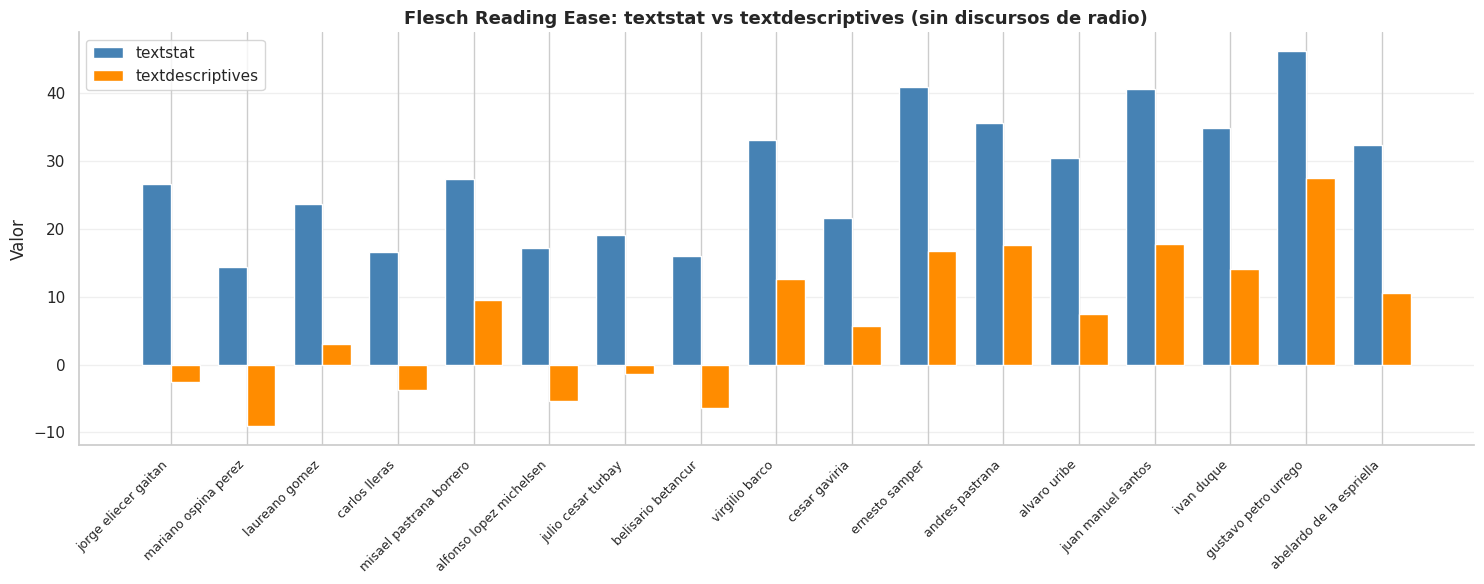

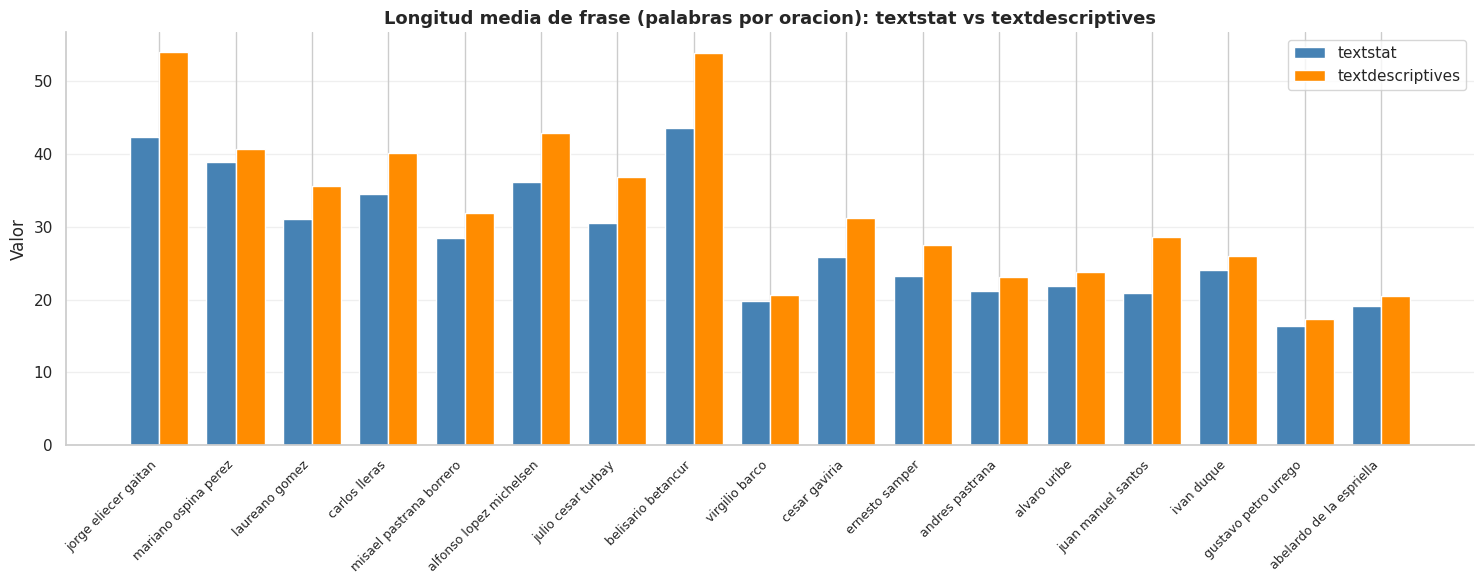

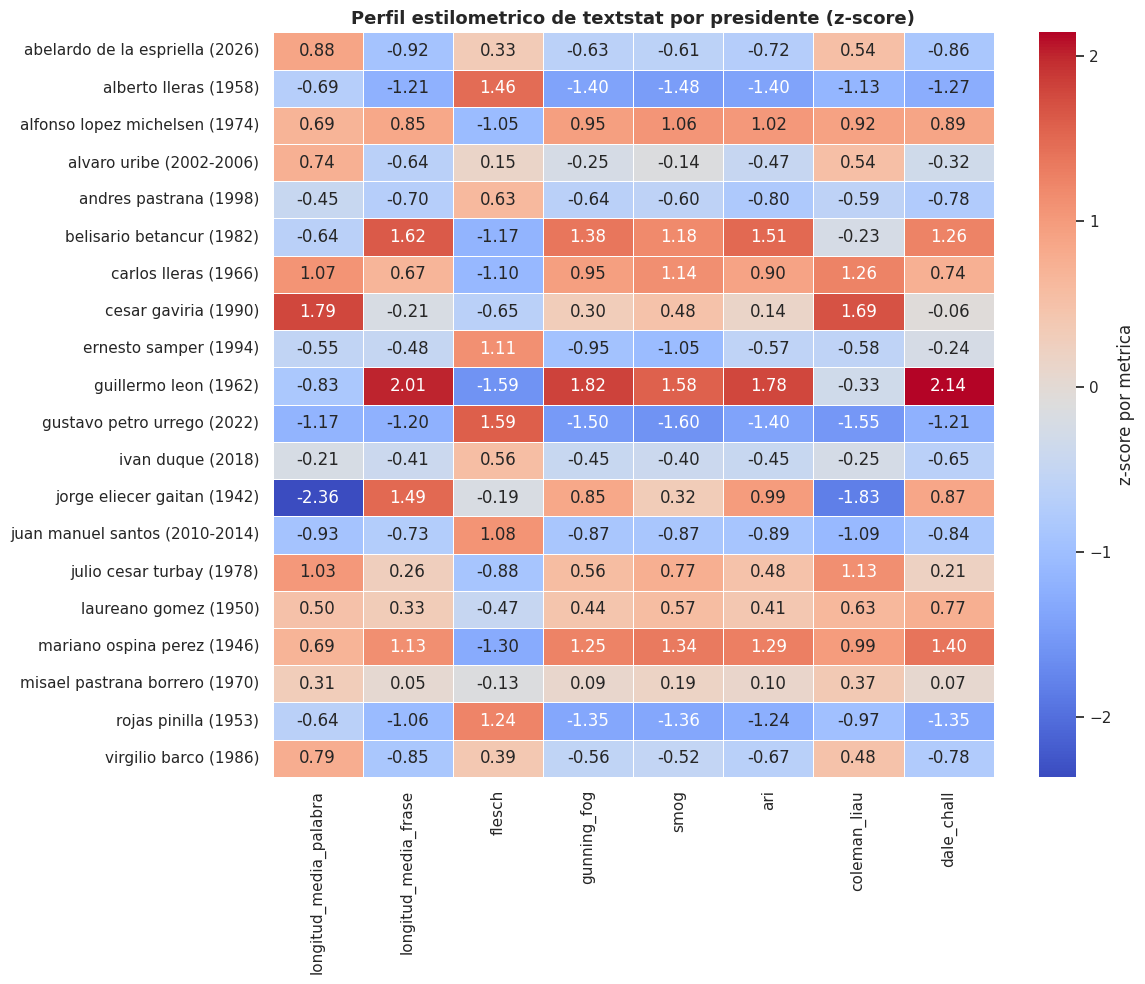

In [54]:
# ===== Punto 7 (d): figuras comparativas (Flesch, longitud de frase, heatmap) =====
# Se excluyen de las barras los tres discursos de radio sin puntuacion
# (1953, 1958 y 1962): textdescriptives no puede segmentarlos y sus valores
# explotan (se documenta en el markdown). Los CSVs si incluyen todos.
con_puntuacion = df["discurso"].apply(lambda t: bool(re.search(r"[.!?]", t)))
presidentes_ok = df.loc[con_puntuacion, "presidente"].tolist()

orden_anio = df.groupby("presidente")["año_inicio"].min()


def barras_comparativas(metrica_textstat, metrica_td, titulo, nombre_archivo):
    """Dibuja barras agrupadas textstat vs textdescriptives por presidente.

    Args:
        metrica_textstat (str): Columna de df_estilo_textstat.
        metrica_td (str): Columna de df_estilo_td.
        titulo (str): Titulo de la figura.
        nombre_archivo (str): Nombre del archivo en images/.
    """
    tabla = pd.DataFrame({
        "presidente": df_estilo_textstat["presidente"],
        "textstat": df_estilo_textstat[metrica_textstat],
        "textdescriptives": df_estilo_td[metrica_td],
    })
    tabla = tabla[tabla["presidente"].isin(presidentes_ok)].copy()
    tabla["año"] = tabla["presidente"].map(orden_anio)
    tabla = tabla.sort_values("año")

    fig, ax = plt.subplots(figsize=(15, 6))
    x = np.arange(len(tabla))
    ancho = 0.38
    ax.bar(x - ancho / 2, tabla["textstat"], ancho, label="textstat", color="steelblue")
    ax.bar(x + ancho / 2, tabla["textdescriptives"], ancho,
           label="textdescriptives", color="darkorange")
    ax.set_xticks(x)
    ax.set_xticklabels(tabla["presidente"], rotation=45, ha="right", fontsize=9)
    ax.set_ylabel("Valor")
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)
    fig.tight_layout()
    guardar_figura(fig, nombre_archivo)
    plt.show()


barras_comparativas(
    "flesch", "flesch",
    "Flesch Reading Ease: textstat vs textdescriptives (sin discursos de radio)",
    "flesch_textstat_vs_td.png",
)
barras_comparativas(
    "longitud_media_frase", "longitud_media_frase",
    "Longitud media de frase (palabras por oracion): textstat vs textdescriptives",
    "longitud_frase_textstat_vs_td.png",
)

# Heatmap de las ocho metricas de textstat (z-score por columna)
metricas_heatmap = [
    "longitud_media_palabra", "longitud_media_frase",
    "flesch", "gunning_fog", "smog", "ari", "coleman_liau", "dale_chall",
]
matriz_estilo = df_estilo_textstat[metricas_heatmap].astype(float)
matriz_estilo = (matriz_estilo - matriz_estilo.mean()) / matriz_estilo.std()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    matriz_estilo,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"label": "z-score por metrica"},
    ax=ax,
)
ax.set_yticklabels(
    df_estilo_textstat["presidente"] + " (" + df_estilo_textstat["año_inicio"] + ")",
    rotation=0,
)
ax.set_title("Perfil estilometrico de textstat por presidente (z-score)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "heatmap_estilometria_textstat.png")
plt.show()



**Comparación de vías (Juan Manuel Santos, 2014) y conclusión**

Para el discurso de Santos (2014) las dos vías **no coinciden** en la mayoría de métricas:

| Métrica | textstat | textdescriptives |
|---|---|---|
| Flesch Reading Ease | 47,85 | 25,30 |
| Gunning Fog | 14,10 | 20,04 |
| Longitud media de frase (palabras/oración) | 17,59 | 24,99 |
| Longitud media de palabra (caracteres) | 4,77 | 4,58 |
| Número de oraciones | 186 | 138 |

Las diferencias tienen tres causas verificables: (1) **segmentación de oraciones**: textstat detecta 186 oraciones (regex sobre puntuación, con la adaptación `texto_para_legibilidad`) y textdescriptives 138 (parser de spaCy, que une algunas frases tras dos puntos e incisos); con oraciones más cortas, textstat produce frases medias menores (17,59 vs 24,99) y un Flesch más alto (47,85 vs 25,30); (2) **conteo de sílabas**: textstat usa reglas calibradas para inglés, mientras textdescriptives silabiza con el modelo español; (3) la longitud de palabra es casi coincidente (4,77 vs 4,58), porque depende del tokenizador y no de la segmentación. El caso extremo son los discursos de radio sin puntuación (1953, 1958, 1962): textdescriptives no logra segmentar y explota (Alberto Lleras 1958: **1.360,9** palabras por oración y Flesch **-1.335,96**; Guillermo León 1962: 9.055 y -9.147,64; su SMOG queda en NaN), mientras textstat con la adaptación produce valores razonables (A. Lleras: 16,27 palabras/oración y Flesch 44,93).

**Conclusión.** textdescriptives es la vía **más práctica de integrar en el pipeline de spaCy**: las métricas quedan dentro del propio `Doc` (`._.readability`, `._.token_length`, `._.sentence_length`), no exigen re-tokenización, se calculan en la misma pasada con `nlp.pipe` y usan la segmentación del modelo español; su limitación es depender del parser en textos sin puntuación. textstat sigue aportando los índices que textdescriptives no expone (ARI, Coleman-Liau, Dale-Chall) y permite pre-procesar la segmentación, pero es standalone y sus fórmulas de sílabas están calibradas para inglés.



## 8. Análisis temporal del discurso presidencial

**Metodología.** El punto 8 del taller pide analizar cómo evolucionan el lenguaje y el estilo presidencial a lo largo del tiempo. El corpus contiene **22 discursos de posesión** (1942-2026), uno por presidente y periodo; se ordenan cronológicamente por su año de posesión (`año_inicio`) y, para cada discurso/año, se calculan cuatro familias de métricas:

- el **número total de palabras** sobre el texto limpio (`discurso_limpio`);
- la **diversidad léxica** como cociente entre tipos y tokens (len(set(tokens))/len(tokens), fórmula del enunciado), tanto sobre los tokens de NLTK como sobre los lemas de spaCy;
- la **frecuencia absoluta de términos específicos** (paz, guerra, justicia, economía, seguridad, partido, desarrollo) contada con un `Counter` por discurso sobre los lemas de spaCy;
- los **índices de legibilidad** de textstat (Flesch Reading Ease, Gunning Fog, SMOG y Flesch-Kincaid) y las longitudes medias de palabra y de frase, aplicados sobre el texto **original** (`discurso`) porque la segmentación de oraciones requiere la puntuación.

El análisis por año que sigue se complementa al final de la sección con una vista por **década** (tabla de frecuencias, evolución de términos y heatmap), que agrupa los mismos conteos para facilitar la lectura de las tendencias de largo plazo.

In [55]:
# ===== Punto 8: serie temporal por discurso/año (total de palabras,
# diversidad, terminos clave y legibilidad) =====
import textstat

terminos_clave = ["paz", "guerra", "justicia", "economía", "seguridad", "partido", "desarrollo"]
contadores_lemas = [Counter(lemas) for lemas in df["lemas_spacy"]]


def palabras_originales(texto):
    """Extrae las palabras del texto original ignorando puntuacion y numeros.

    Args:
        texto (str): Texto del discurso tal como viene del corpus.

    Returns:
        list: Palabras (solo letras, incluidas las acentuadas y la ene).
    """
    return re.findall(r"[^\W\d_]+", texto)


# texto_para_legibilidad: definida en la seccion 7 (punto 7); se reutiliza aqui.

def contar_oraciones(texto):
    """Cuenta las oraciones de un discurso con textstat (minimo 1)."""
    return max(1, textstat.sentence_count(texto_para_legibilidad(texto)))


def longitud_media_palabra(texto):
    """Longitud media de palabra (caracteres por palabra) sobre el texto original."""
    palabras = palabras_originales(texto)
    return sum(len(p) for p in palabras) / len(palabras) if palabras else 0.0


def longitud_media_frase(texto):
    """Longitud media de frase (palabras por oracion) sobre el texto original."""
    palabras = palabras_originales(texto)
    return len(palabras) / contar_oraciones(texto) if palabras else 0.0


df_temporal = pd.DataFrame({
    "año_inicio": df["año_inicio"],
    "presidente": df["presidente"],
    "corriente_politica": df["corriente_politica"],
    "total_palabras": df["discurso_limpio"].apply(lambda t: len(t.split())),
    "diversidad_tokens": df["tokens_nltk"].apply(
        lambda tokens: len(set(tokens)) / len(tokens) if tokens else 0.0
    ),
    "diversidad_lemas": df["lemas_spacy"].apply(
        lambda lemas: len(set(lemas)) / len(lemas) if lemas else 0.0
    ),
    **{
        "frecuencia_" + termino: [contador.get(termino, 0) for contador in contadores_lemas]
        for termino in terminos_clave
    },
    "flesch": df["discurso"].apply(
        lambda t: textstat.flesch_reading_ease(texto_para_legibilidad(t))
    ),
    "gunning_fog": df["discurso"].apply(
        lambda t: textstat.gunning_fog(texto_para_legibilidad(t))
    ),
    "smog": df["discurso"].apply(
        lambda t: textstat.smog_index(texto_para_legibilidad(t))
    ),
    "kincaid": df["discurso"].apply(
        lambda t: textstat.flesch_kincaid_grade(texto_para_legibilidad(t))
    ),
    "longitud_media_palabra": df["discurso"].apply(longitud_media_palabra),
    "longitud_media_frase": df["discurso"].apply(longitud_media_frase),
})

df_temporal = df_temporal.sort_values("año_inicio").reset_index(drop=True)

# CSV con la legibilidad redondeada a 2 decimales (utf-8-sig)
columnas_legibilidad = [
    "flesch", "gunning_fog", "smog", "kincaid",
    "longitud_media_palabra", "longitud_media_frase",
]
df_temporal_csv = df_temporal.copy()
df_temporal_csv[columnas_legibilidad] = df_temporal_csv[columnas_legibilidad].round(2)
df_temporal_csv[["diversidad_tokens", "diversidad_lemas"]] = df_temporal_csv[["diversidad_tokens", "diversidad_lemas"]].round(3)
df_temporal_csv.to_csv("images/analisis_temporal.csv", index=False, encoding="utf-8-sig")

df_temporal_mostrar = df_temporal_csv.copy()
df_temporal_mostrar[["diversidad_tokens", "diversidad_lemas"]] = (
    df_temporal_mostrar[["diversidad_tokens", "diversidad_lemas"]].round(3)
)
print("Serie temporal por discurso/año (guardada en images/analisis_temporal.csv):")
with pd.option_context("display.max_columns", None, "display.width", 260):
    print(df_temporal_mostrar.to_string(index=False))

Serie temporal por discurso/año (guardada en images/analisis_temporal.csv):
 año_inicio               presidente      corriente_politica  total_palabras  diversidad_tokens  diversidad_lemas  frecuencia_paz  frecuencia_guerra  frecuencia_justicia  frecuencia_economía  frecuencia_seguridad  frecuencia_partido  frecuencia_desarrollo  flesch  gunning_fog  smog  kincaid  longitud_media_palabra  longitud_media_frase
       1942     jorge eliecer gaitan               Izquierda            3303              0.567             0.544               0                  0                    3                    4                     1                   6                      0   26.65        22.90 17.48    20.07                    4.59                 42.35
       1946     mariano ospina perez          Centro-Derecha           10661              0.471             0.409              13                 12                    9                    4                     3                  39                

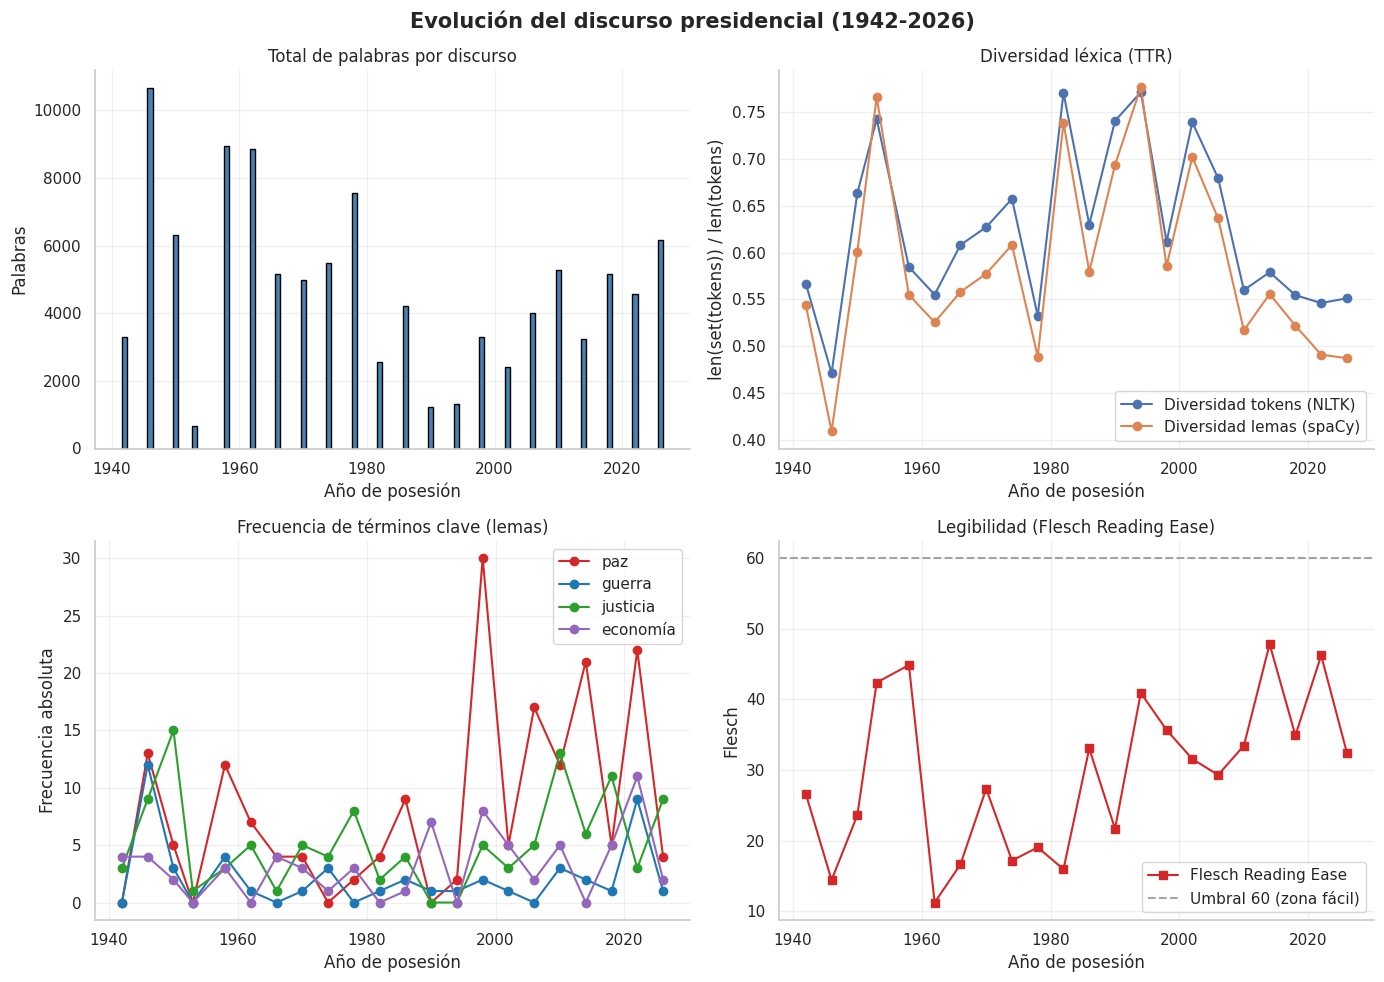

In [56]:
# ===== Punto 8: evolucion temporal completa (2x2) =====
fig, ejes = plt.subplots(2, 2, figsize=(14, 10))
anios = df_temporal["año_inicio"]

# (a) Total de palabras por año
ejes[0, 0].bar(anios, df_temporal["total_palabras"], color="steelblue", edgecolor="black")
ejes[0, 0].set_title("Total de palabras por discurso")
ejes[0, 0].set_xlabel("Año de posesión")
ejes[0, 0].set_ylabel("Palabras")
ejes[0, 0].grid(True, alpha=0.3)

# (b) Diversidad lexica (tokens NLTK y lemas spaCy)
ejes[0, 1].plot(anios, df_temporal["diversidad_tokens"], marker="o",
                label="Diversidad tokens (NLTK)")
ejes[0, 1].plot(anios, df_temporal["diversidad_lemas"], marker="o",
                label="Diversidad lemas (spaCy)")
ejes[0, 1].set_title("Diversidad léxica (TTR)")
ejes[0, 1].set_xlabel("Año de posesión")
ejes[0, 1].set_ylabel("len(set(tokens)) / len(tokens)")
ejes[0, 1].legend()
ejes[0, 1].grid(True, alpha=0.3)

# (c) Frecuencia de terminos clave (paz, guerra, justicia, economia)
colores_terminos = ["#d62728", "#1f77b4", "#2ca02c", "#9467bd"]
for termino, color in zip(["paz", "guerra", "justicia", "economía"], colores_terminos):
    ejes[1, 0].plot(anios, df_temporal["frecuencia_" + termino], marker="o",
                    label=termino, color=color)
ejes[1, 0].set_title("Frecuencia de términos clave (lemas)")
ejes[1, 0].set_xlabel("Año de posesión")
ejes[1, 0].set_ylabel("Frecuencia absoluta")
ejes[1, 0].legend()
ejes[1, 0].grid(True, alpha=0.3)

# (d) Flesch Reading Ease con linea de referencia en 60
ejes[1, 1].plot(anios, df_temporal["flesch"], marker="s",
                label="Flesch Reading Ease", color="tab:red")
ejes[1, 1].axhline(y=60, color="gray", linestyle="--", alpha=0.7,
                   label="Umbral 60 (zona fácil)")
ejes[1, 1].set_title("Legibilidad (Flesch Reading Ease)")
ejes[1, 1].set_xlabel("Año de posesión")
ejes[1, 1].set_ylabel("Flesch")
ejes[1, 1].legend()
ejes[1, 1].grid(True, alpha=0.3)

fig.suptitle("Evolución del discurso presidencial (1942-2026)",
             fontsize=15, fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "evolucion_temporal_completa.png")
plt.show()

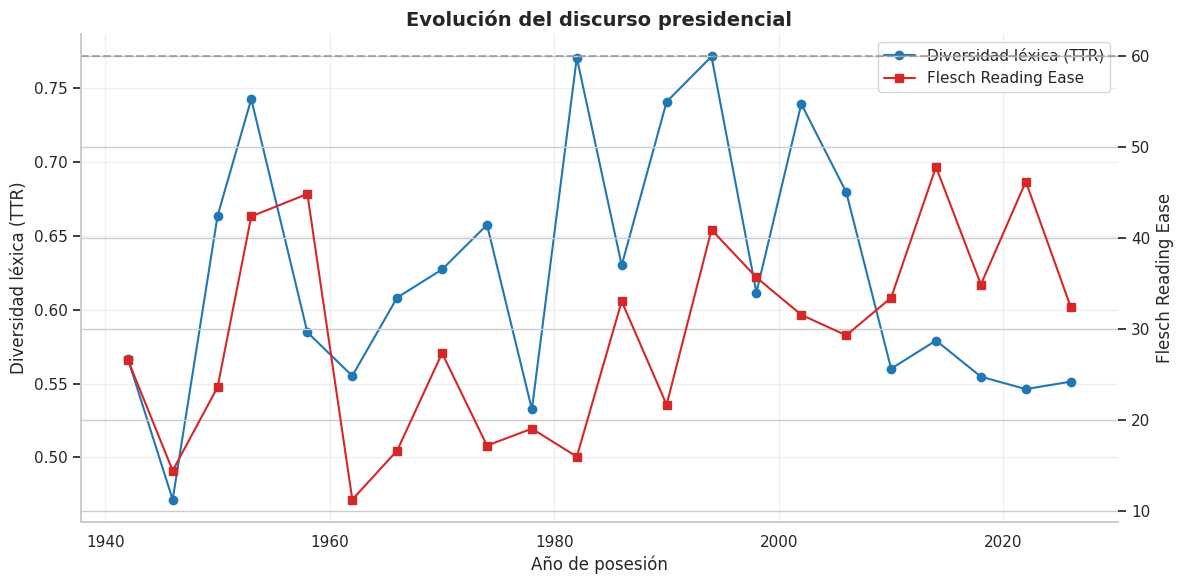

In [57]:
# ===== Punto 8: visualizacion sugerida por el enunciado (doble eje) =====
fig, ax_izq = plt.subplots(figsize=(12, 6))
ax_izq.plot(anios, df_temporal["diversidad_tokens"], marker="o",
            label="Diversidad léxica (TTR)", color="tab:blue")
ax_izq.set_xlabel("Año de posesión")
ax_izq.set_ylabel("Diversidad léxica (TTR)")
ax_izq.grid(True, alpha=0.3)

ax_der = ax_izq.twinx()
ax_der.plot(anios, df_temporal["flesch"], marker="s",
            label="Flesch Reading Ease", color="tab:red")
ax_der.set_ylabel("Flesch Reading Ease")
ax_der.axhline(y=60, color="gray", linestyle="--", alpha=0.6)

lineas_izq, etiquetas_izq = ax_izq.get_legend_handles_labels()
lineas_der, etiquetas_der = ax_der.get_legend_handles_labels()
ax_izq.legend(lineas_izq + lineas_der, etiquetas_izq + etiquetas_der, loc="best")
ax_izq.set_title("Evolución del discurso presidencial", fontsize=14, fontweight="bold")

fig.tight_layout()
guardar_figura(fig, "diversidad_flesch_temporal.png")
plt.show()

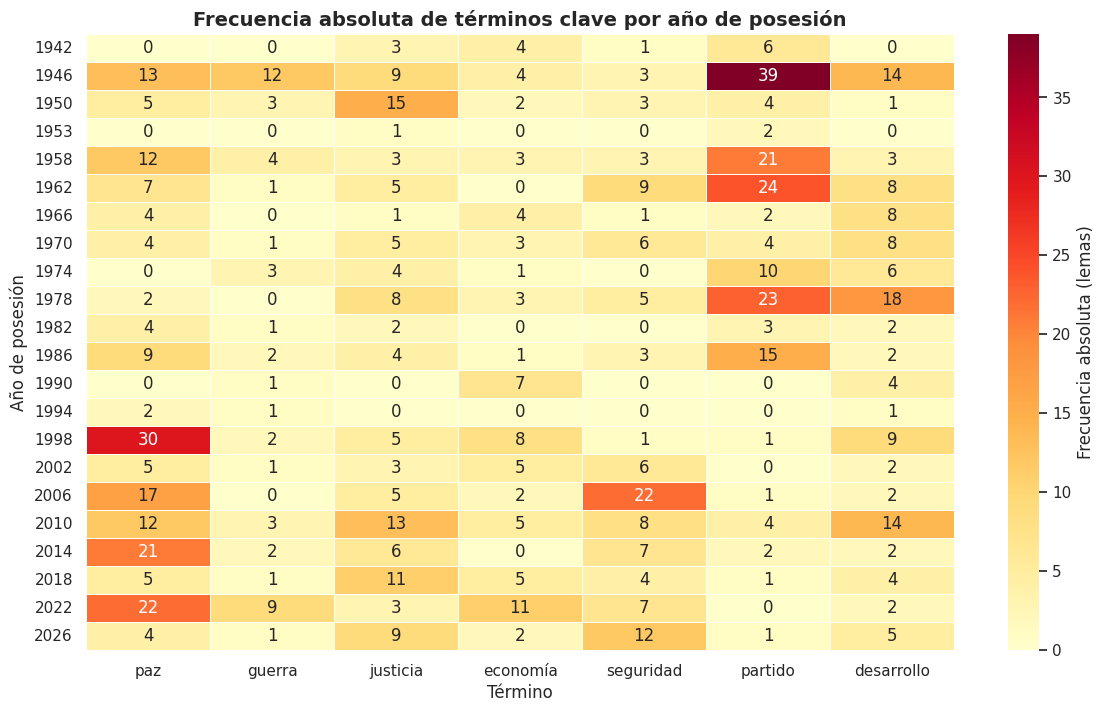

In [58]:
# ===== Punto 8: heatmap de terminos clave por año =====
piv_anio = df_temporal.set_index("año_inicio")[
    ["frecuencia_" + t for t in terminos_clave]
]
piv_anio.columns = terminos_clave

valores = piv_anio.to_numpy()
formato_anotacion = "d" if np.all(valores == valores.astype(int)) else ".0f"

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(
    piv_anio,
    annot=True,
    fmt=formato_anotacion,
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Frecuencia absoluta (lemas)"},
    ax=ax,
)
ax.set_title("Frecuencia absoluta de términos clave por año de posesión",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Término")
ax.set_ylabel("Año de posesión")
guardar_figura(fig, "heatmap_terminos_anio.png")
plt.show()

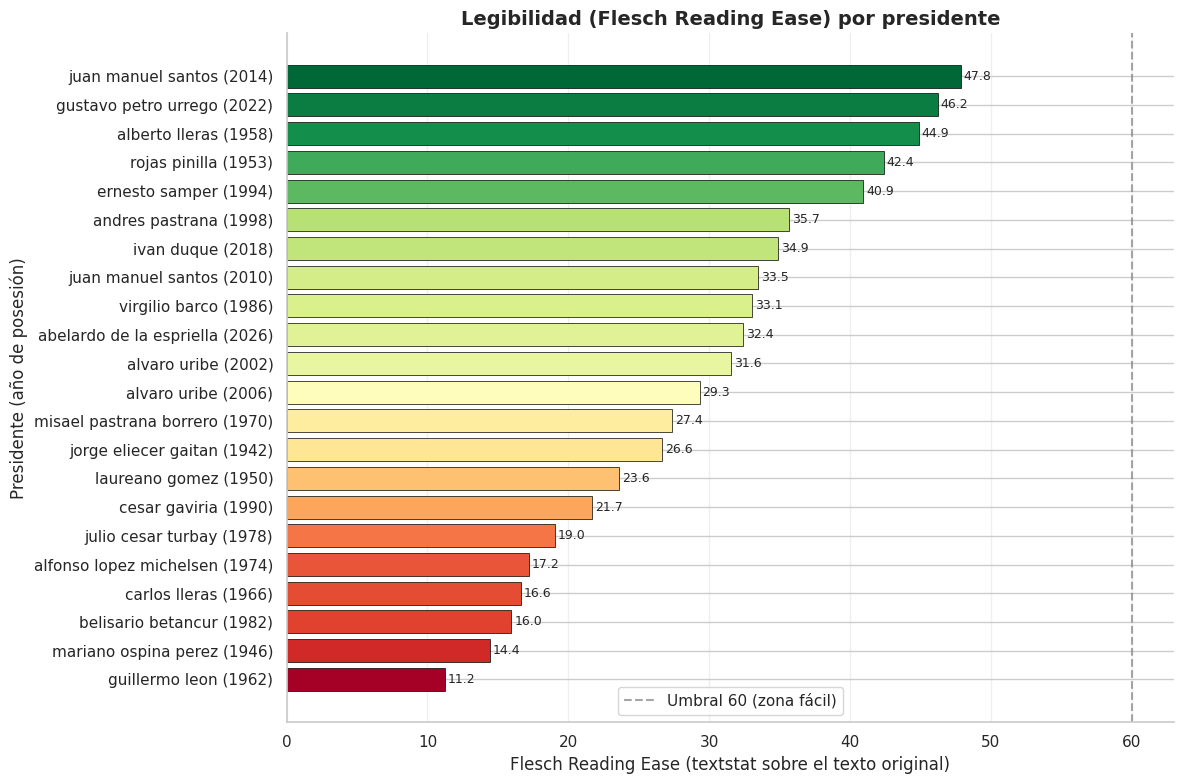

In [59]:
# ===== Punto 8 (extra): legibilidad por presidente =====
flesch_presidentes = (
    df_temporal[["presidente", "año_inicio", "flesch"]]
    .sort_values("flesch")
    .reset_index(drop=True)
)
etiquetas = (
    flesch_presidentes["presidente"] + " (" + flesch_presidentes["año_inicio"].astype(str) + ")"
)
valores_flesch = flesch_presidentes["flesch"]

# Color continuo: verde (mas legible) a rojo (menos legible)
rango = valores_flesch.max() - valores_flesch.min()
colores_barras = plt.cm.RdYlGn((valores_flesch - valores_flesch.min()) / rango)

fig, ax = plt.subplots(figsize=(12, 8))
barras = ax.barh(etiquetas, valores_flesch, color=colores_barras,
                 edgecolor="black", linewidth=0.5)
ax.bar_label(barras, fmt="%.1f", padding=2, fontsize=9)
ax.set_title("Legibilidad (Flesch Reading Ease) por presidente",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Flesch Reading Ease (textstat sobre el texto original)")
ax.set_ylabel("Presidente (año de posesión)")
ax.axvline(x=60, color="gray", linestyle="--", alpha=0.7, label="Umbral 60 (zona fácil)")
ax.legend()
ax.grid(True, axis="x", alpha=0.3)
fig.tight_layout()
guardar_figura(fig, "flesch_por_presidente.png")
plt.show()

**Tendencias verificadas sobre los datos del `df_temporal`**

1. **Tamaño de los discursos.** El discurso más largo es el de Mariano Ospina Pérez (1946) con **10.661 palabras** y el más corto el de Rojas Pinilla (1953) con **657** (media de 4.815). La correlación entre el año y el total de palabras es negativa (-0,30): los discursos modernos tienden a ser más breves (Gaviria 1990: 1.213; Samper 1994: 1.327; Uribe 2002: 2.395) que los maratónicos de los años 40-60 (Ospina 10.661, Lleras 1958: 8.948, Guillermo León 1962: 8.859).

2. **Diversidad léxica.** El TTR sobre tokens es máximo en Samper (1994) con **0,772** (1.327 palabras) y en Rojas Pinilla (1953) con 0,743 (657 palabras), y mínimo en Ospina (1946) con **0,471** (10.661 palabras). El TTR es muy sensible a la longitud: su correlación con `total_palabras` es **-0,75**, de modo que los textos cortos parecen más "ricos" solo por ser cortos. La diversidad sobre lemas suaviza el efecto (máximo 0,777 en Samper; mínimo 0,409 en Ospina) y confirma el mismo patrón: los discursos breves de los 90 son los léxicamente más variados.

3. **Ejes temáticos.** **paz** tiene su pico en 1998 con **30** menciones (Pastrana, proceso del Caguán), seguido de 2022 (Petro, 22, "paz total") y 2014 (Santos, 21, acuerdos de La Habana); **guerra** domina en 1946 (Ospina, 12, inicio de La Violencia) y reaparece en 2022 (Petro, 9); **economía** pica en 2022 (11) y en 1990 (Gaviria, 7, apertura económica); **seguridad** alcanza su máximo en 2006 (Uribe, 22, seguridad democrática) y está ausente en 1953, 1974, 1982, 1990 y 1994; **partido** marca su máximo en 1946 (39, bipartidismo) y desaparece prácticamente desde los 90; **justicia** pica en 1950 (15) y 2010 (13); **desarrollo** en 1978 (16). La agenda temática responde claramente al contexto histórico de cada periodo.

4. **Legibilidad.** El Flesch mínimo es **11,50** (Guillermo León, 1962) y el máximo **47,85** (Juan Manuel Santos, 2014), con media de 29,78 y correlación positiva de **+0,46** con el año: el discurso moderno es más accesible (Ospina 1946: 14,43; Carlos Lleras 1966: 16,75) frente a Duque 2018 (34,91), Petro 2022 (46,24) y Santos 2014 (47,85). Advertencia metodológica: textstat está diseñado para inglés y sus umbrales ("fácil/difícil") no son directamente aplicables al español; los valores sirven como comparación relativa entre discursos, no como medida absoluta de legibilidad en castellano.

In [60]:
# ===== Punto 8: tabla de frecuencias por decada (terminos especificos) =====
terminos_temporales = [
    "paz", "guerra", "justicia", "economía", "seguridad", "partido", "pueblo",
    "patria", "vida", "libertad", "nación", "social", "democracia", "desarrollo",
]

df_decada = terminos_clave_por_grupo(df, "decada", terminos_temporales)
df_decada = df_decada.rename(
    columns={"grupo": "decada", "frecuencia": "frecuencia_absoluta"}
)
df_decada.to_csv("images/terminos_clave_decada.csv", index=False, encoding="utf-8-sig")

print("Numero de discursos por decada:")
print(df["decada"].value_counts().sort_index().to_string())
print("\nFrecuencia de terminos clave por decada (guardado en images/terminos_clave_decada.csv):")
print(df_decada.to_string(index=False))

Numero de discursos por decada:
decada
1940s    2
1950s    3
1960s    2
1970s    3
1980s    2
1990s    3
2000s    2
2010s    3
2020s    2

Frecuencia de terminos clave por decada (guardado en images/terminos_clave_decada.csv):
decada    termino  frecuencia_absoluta  frecuencia_por_discurso
 1940s        paz                   13                 6.500000
 1940s     guerra                   12                 6.000000
 1940s   justicia                   12                 6.000000
 1940s   economía                    8                 4.000000
 1940s  seguridad                    4                 2.000000
 1940s    partido                   45                22.500000
 1940s     pueblo                   56                28.000000
 1940s     patria                   19                 9.500000
 1940s       vida                   22                11.000000
 1940s   libertad                    8                 4.000000
 1940s     nación                   21                10.500000
 1940

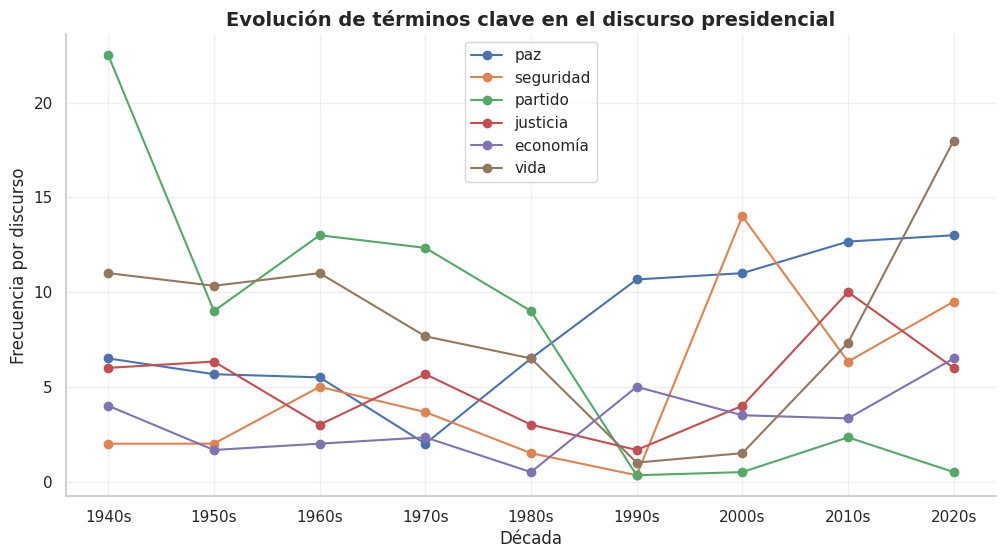

In [61]:
# ===== Punto 8: evolucion de seis terminos clave por decada =====
terminos_evolucion = ["paz", "seguridad", "partido", "justicia", "economía", "vida"]

fig, ax = plt.subplots(figsize=(12, 6))
for termino in terminos_evolucion:
    serie = df_decada[df_decada["termino"] == termino].sort_values("decada")
    ax.plot(
        serie["decada"],
        serie["frecuencia_por_discurso"],
        marker="o",
        label=termino,
    )
ax.set_title(
    "Evolución de términos clave en el discurso presidencial",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel("Década")
ax.set_ylabel("Frecuencia por discurso")
ax.legend()
ax.grid(True, alpha=0.3)
guardar_figura(fig, "evolucion_terminos_clave.png")
plt.show()

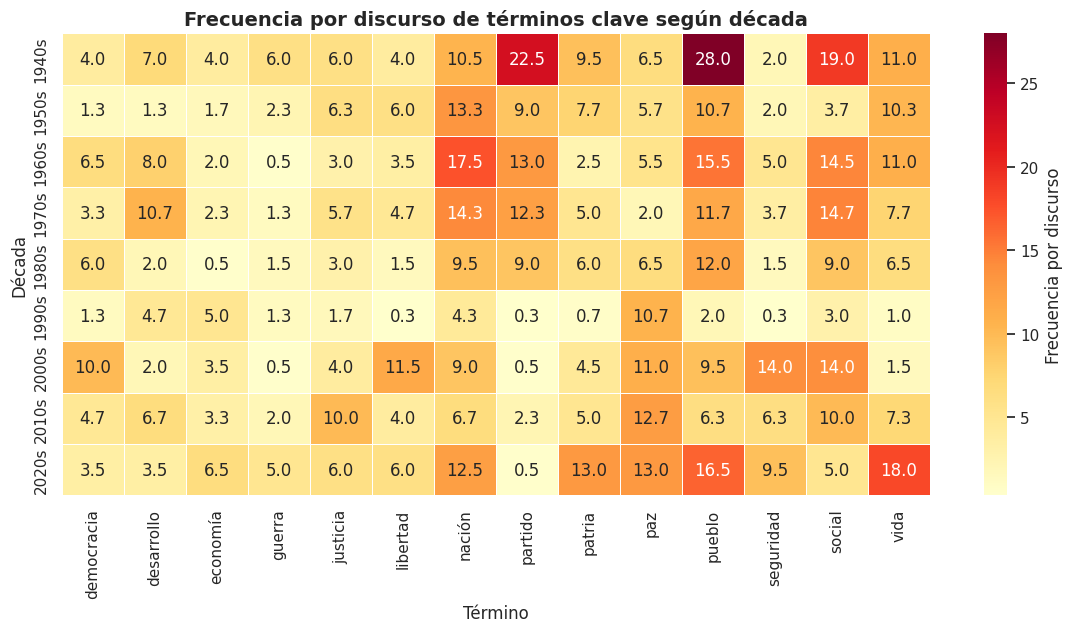

In [62]:
# ===== Punto 8: heatmap de decadas x terminos clave =====
piv_decada = df_decada.pivot(
    index="decada", columns="termino", values="frecuencia_por_discurso"
)
piv_decada = piv_decada.loc[sorted(piv_decada.index)]  # orden cronologico

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    piv_decada,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Frecuencia por discurso"},
    ax=ax,
)
ax.set_title(
    "Frecuencia por discurso de términos clave según década",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel("Término")
ax.set_ylabel("Década")
guardar_figura(fig, "heatmap_terminos_decada.png")
plt.show()

**Complemento: tendencias tematicas verificadas por decada**

La serie por decada (frecuencia por discurso) revela cambios de agenda claramente anclados en el contexto historico:

- **partido** domina los anos 40 (22,5 por discurso, el valor mas alto de la tabla) y se mantiene alto hasta los 80 (entre 9,0 y 13,0), reflejo del regimen bipartidista; en los 90 se desploma a 0,3 y no se recupera (maximo de 2,3 en los 2010). El discurso deja de hablar de los partidos.
- **paz** toca su minimo en los 70 (2,0), irrumpe en los 90 (10,7, negociaciones con las guerrillas) y crece de forma sostenida hasta los 2020 (13,0, acuerdos de paz y posconflicto).
- **seguridad** tiene su pico maximo en los 2000 (14,0): la seguridad democratica de Uribe; luego se mantiene relevante en los 2010 (6,3) y los 2020 (9,5).
- **justicia** alcanza su maximo en los 2010 (10,0), en linea con el lenguaje de los acuerdos; **economia** sube en los 90 (5,0, apertura economica de Gaviria) y reaparece en los 2020 (6,5).
- **vida** (18,0) y **patria** (13,0) irrumpen en los 2020 con sus maximos de toda la serie; **patria** habia casi desaparecido en los 90 (0,7).
- **guerra** se concentra en los 40 (6,0, la Violencia) y reaparece en los 2020 (5,0); **pueblo** es lider en los 40 (28,0, Gaitan) y vuelve a crecer en los 2020 (16,5, Petro).
- La **formalidad** tambien cambia: "senor" (tratamiento protocolario) se dispara en los 70 (14,3 por discurso, 43 apariciones en total) y desaparece en los 80 (0,0).

En conjunto, la frecuencia de terminos especificos confirma que el discurso presidencial responde al contexto historico: bipartidismo (40-80), apertura y paz (90-2000), seguridad (2000) y posconflicto-social (2010-2020).

## 9. Entidades nombradas (NER)

Se aplica `doc.ents` sobre los 22 Doc de `docs_corpus` (ya procesados con tildes y puntuación; no se reprocesa nada). Las etiquetas del modelo `es_core_news_md` se agrupan en las cuatro categorías del enunciado: **PER** (PERSON), **LOC** (GPE y LOC), **ORG** y **MISC** (el resto: NORP, FAC, EVENT, DATE, etc.). Se cuentan las entidades por tipo, se listan los top por tipo y por discurso, y se comparan por década para ver qué actores y lugares dominan cada época.



In [63]:
# ===== Punto 9: entidades nombradas (NER) sobre docs_corpus =====
MAPEO_NER = {"PERSON": "PER", "PER": "PER", "GPE": "LOC", "LOC": "LOC", "ORG": "ORG"}


def etiqueta_ner_grupo(etiqueta):
    """Agrupa las etiquetas NER de spaCy en PER, LOC, ORG y MISC.

    El modelo es_core_news_md usa etiquetas propias de spaCy (PERSON, GPE,
    LOC, ORG, NORP, FAC, EVENT, ...). El enunciado pide cuatro categorias:
    PER (PERSON), LOC (GPE y LOC), ORG, y MISC (todo lo demas).

    Args:
        etiqueta (str): Etiqueta NER del modelo (por ejemplo, 'GPE').

    Returns:
        str: Categoria agrupada ('PER', 'LOC', 'ORG' o 'MISC').
    """
    return MAPEO_NER.get(etiqueta, "MISC")


conteo_global_ner = Counter()
top_por_tipo = {tipo: Counter() for tipo in ["PER", "LOC", "ORG", "MISC"]}
registros_ner = []

for idx, doc in enumerate(docs_corpus):
    conteo_doc = Counter()
    for ent in doc.ents:
        tipo = etiqueta_ner_grupo(ent.label_)
        entidad = ent.text.strip()
        conteo_global_ner[tipo] += 1
        top_por_tipo[tipo][entidad] += 1
        conteo_doc[tipo] += 1
    registros_ner.append({
        "año_inicio": df.loc[idx, "año_inicio"],
        "presidente": df.loc[idx, "presidente"],
        "decada": df.loc[idx, "decada"],
        "PER": conteo_doc["PER"],
        "LOC": conteo_doc["LOC"],
        "ORG": conteo_doc["ORG"],
        "MISC": conteo_doc["MISC"],
        "total": sum(conteo_doc.values()),
    })

df_ner = pd.DataFrame(registros_ner)
print("Conteo global de entidades por tipo:", dict(conteo_global_ner))
print("Total de entidades en el subcorpus:", sum(conteo_global_ner.values()))
print("\nEntidades por discurso:")
print(df_ner.to_string(index=False))

# CSV detallado: una fila por (discurso, tipo, entidad, frecuencia)
filas_detalle_ner = []
for idx, doc in enumerate(docs_corpus):
    contador_entidades = Counter()
    for ent in doc.ents:
        tipo = etiqueta_ner_grupo(ent.label_)
        contador_entidades[(tipo, ent.text.strip())] += 1
    for (tipo, entidad), frecuencia in contador_entidades.items():
        filas_detalle_ner.append({
            "año_inicio": df.loc[idx, "año_inicio"],
            "presidente": df.loc[idx, "presidente"],
            "decada": df.loc[idx, "decada"],
            "etiqueta": tipo,
            "entidad": entidad,
            "frecuencia": frecuencia,
        })
df_entidades_ner = pd.DataFrame(filas_detalle_ner)
df_entidades_ner.to_csv("images/entidades_ner.csv", index=False, encoding="utf-8-sig")
print("\nDetalle por entidad guardado en images/entidades_ner.csv con",
      len(df_entidades_ner), "filas.")

print("\nTop-10 de entidades por tipo:")
for tipo in ["PER", "LOC", "ORG", "MISC"]:
    print(f"[{tipo}]")
    for entidad, frecuencia in top_por_tipo[tipo].most_common(10):
        print(f"  {entidad}: {frecuencia}")



Conteo global de entidades por tipo: {'PER': 305, 'LOC': 609, 'ORG': 56, 'MISC': 39}
Total de entidades en el subcorpus: 1009

Entidades por discurso:
 año_inicio               presidente decada  PER  LOC  ORG  MISC  total
       1942     jorge eliecer gaitan  1940s   14   16    0     0     30
       1946     mariano ospina perez  1940s   17   25    6     2     50
       1950           laureano gomez  1950s   12   10    2     0     24
       1953            rojas pinilla  1950s    4    9    2     2     17
       1958           alberto lleras  1950s   45   26    9     9     89
       1962           guillermo leon  1960s   36   48    9     6     99
       1966            carlos lleras  1960s    4   21    0     2     27
       1970  misael pastrana borrero  1970s    5   14    0     0     19
       1974  alfonso lopez michelsen  1970s   19   46    0     2     67
       1978       julio cesar turbay  1970s   45   45    2     2     94
       1982       belisario betancur  1980s    3   16    

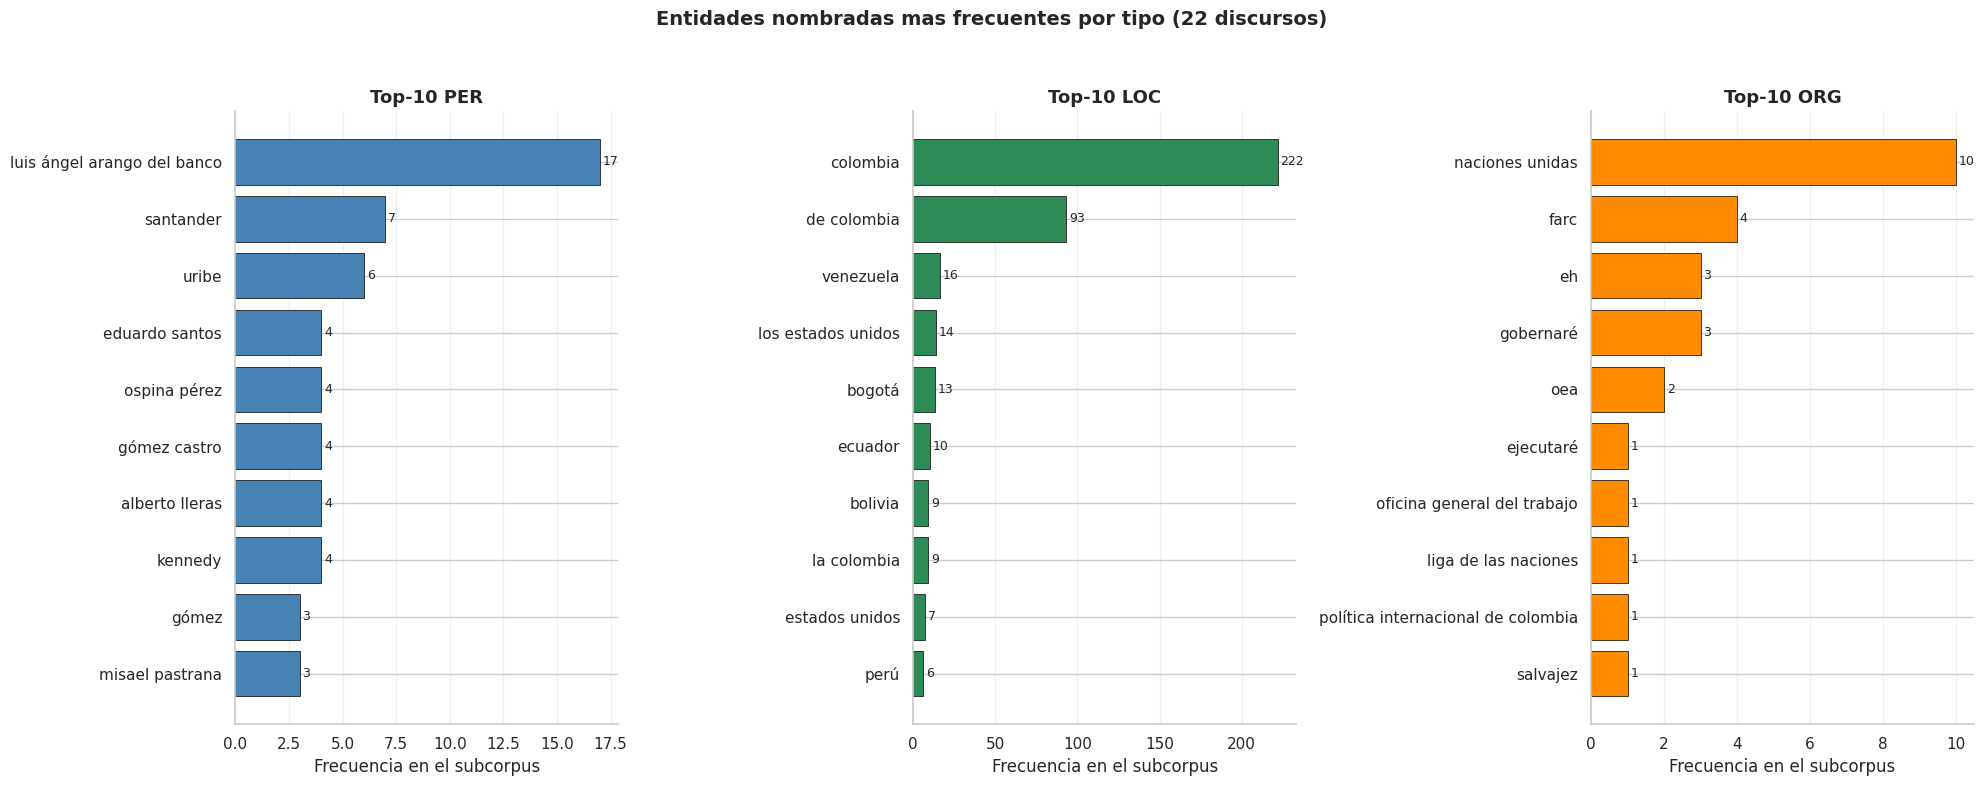

In [64]:
# ===== Punto 9: figura top-10 de entidades por tipo (PER, LOC, ORG) =====
fig, ejes = plt.subplots(1, 3, figsize=(20, 8))
colores_ner = {"PER": "steelblue", "LOC": "seagreen", "ORG": "darkorange"}
for ax, tipo in zip(ejes, ["PER", "LOC", "ORG"]):
    top = top_por_tipo[tipo].most_common(10)
    nombres = [entidad for entidad, _ in reversed(top)]
    valores = [frecuencia for _, frecuencia in reversed(top)]
    barras = ax.barh(nombres, valores, color=colores_ner[tipo],
                     edgecolor="black", linewidth=0.5)
    ax.bar_label(barras, fmt="%d", padding=2, fontsize=9)
    ax.set_title(f"Top-10 {tipo}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Frecuencia en el subcorpus")
    ax.grid(True, axis="x", alpha=0.3)
fig.suptitle("Entidades nombradas mas frecuentes por tipo (22 discursos)",
             fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
guardar_figura(fig, "ner_top_por_tipo.png")
plt.show()



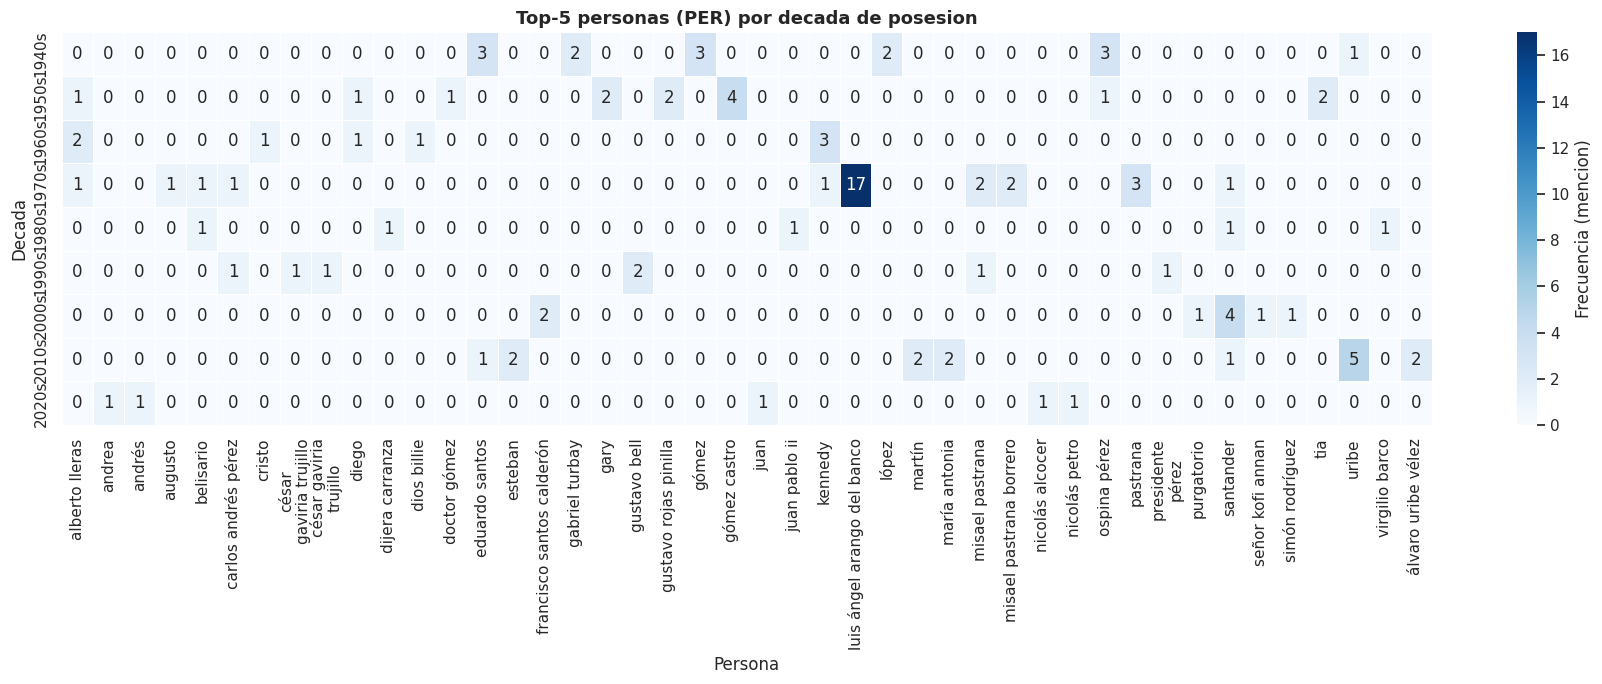

In [65]:
# ===== Punto 9: personas mas frecuentes por decada (heatmap) =====
personas_por_decada = {}
for idx, doc in enumerate(docs_corpus):
    decada = df.loc[idx, "decada"]
    personas_por_decada.setdefault(decada, Counter())
    for ent in doc.ents:
        if etiqueta_ner_grupo(ent.label_) == "PER":
            personas_por_decada[decada][ent.text.strip()] += 1

top_personas_decada = {
    decada: contador.most_common(5) for decada, contador in personas_por_decada.items()
}

# Matriz decada x persona para el heatmap (union de las top-5 por decada)
todas_personas = sorted({p for top in top_personas_decada.values() for p, _ in top})
decadas_orden = sorted(personas_por_decada)
matriz_ner = np.zeros((len(decadas_orden), len(todas_personas)))
for i, decada in enumerate(decadas_orden):
    for persona, frecuencia in personas_por_decada[decada].items():
        if persona in todas_personas:
            matriz_ner[i, todas_personas.index(persona)] = frecuencia

df_heatmap_ner = pd.DataFrame(matriz_ner, index=decadas_orden, columns=todas_personas)

fig, ax = plt.subplots(figsize=(18, 7))
sns.heatmap(
    df_heatmap_ner,
    annot=True,
    fmt="g",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Frecuencia (mencion)"},
    ax=ax,
)
ax.set_title("Top-5 personas (PER) por decada de posesion",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Persona")
ax.set_ylabel("Decada")
fig.tight_layout()
guardar_figura(fig, "ner_personas_por_decada.png")
plt.show()



**Qué revelan las entidades (cifras de `images/entidades_ner.csv`)**

1. **El discurso de posesión es geográficamente endocéntrico**: LOC domina con **608 de 1.007** menciones (60,4%), encabezadas por *colombia* (221 menciones, más 92 de "de colombia" y 9 de "la colombia"), *venezuela* (16), *los estados unidos* (14), *bogotá* (13), *ecuador* (10) y *bolivia* (9). El país y sus vecinos inmediatos son el escenario permanente del relato.

2. **Las personas citadas son legitimadoras**: PER suma 303 menciones (30,1%) y su top combina próceres (*santander*, 7), presidentes antecesores (*ospina pérez* 4, *alberto lleras* 4, *eduardo santos* 4, *gómez castro* 4) y referentes internacionales (*kennedy* 4). El primer lugar (*luis ángel arango del banco*, 17) es un artefacto del etiquetado: la mención de la biblioteca del Banco de la República en el discurso de López Michelsen (1974) se etiqueta como PERSON.

3. **Las organizaciones son las instituciones del orden internacional**: ORG (57 menciones, 5,7%) la encabeza *naciones unidas* (10), seguida de *farc* (4) y *oea* (2); la política exterior se articula en los organismos multilaterales.

4. **Por décadas** el reparto de personas cambia con la agenda: en los años 40 se cita a los presidentes coetáneos (*eduardo santos*, *ospina pérez*, *gómez*) y a *roosevelt* (2); en los 60 aparece *kennedy* (3, Alianza para el Progreso); en los 2000 reaparece el prócer *santander* (4, Bicentenario); en los 2010 domina la mención al antecesor *uribe* (5, más *álvaro uribe vélez* 2, en discursos de Santos); y en los 2020 se cita a *gabriel garcía márquez* (Nobel, fallecido en 2014) como patrimonio cultural. Las personas citadas cambian con el contexto político de cada época, pero el marco geográfico (colombia y sus vecinos) permanece estable.



## 10. Grafos de relacionamiento sujeto-verbo y sujeto-adjetivo con NetworkX

A partir de las dependencias sintácticas de los 22 Doc (`docs_corpus`) se extraen dos tipos de relaciones:

- **sujeto-verbo**: para cada token con `dep == "nsubj"` y POS en (NOUN, PROPN) —se excluyen los pronombres, cuyos lemas ('él', 'usted', 'yo') no aportan contenido léxico—, se registra el par (lema del sujeto, lema de su verbo rector) cuando el head es VERB.
- **sujeto-adjetivo**: pares (lema del sujeto, lema del adjetivo) obtenidos por dos vías: hijos del verbo rector con dep en (acomp, attr) e hijos del propio sujeto con dep == amod; se descartan adjetivos que sean stopwords manuales o numerales.

Con cada conjunto se construye un `nx.Graph` (nodos = lemas, aristas ponderadas por la frecuencia del par en el subcorpus) y se filtran los pares con **frecuencia >= 2** para conservar solo las relaciones sistemáticas.



In [66]:
# ===== Punto 10: extraccion de pares sujeto-verbo y sujeto-adjetivo =====
import networkx as nx
import networkx.algorithms.community as nx_community

stopwords_set = ["colombia", "colombiano", "él", "gobierno", "país", "año"]

pares_sujeto_verbo = Counter()
pares_sujeto_adjetivo = Counter()
conteo_nsubj = 0

for doc in docs_corpus:
    for token in doc:
        # Sujetos nominales (NOUN/PROPN): se excluyen pronombres (PRON).
        # El filtro isalpha descarta artefactos de transcripcion (vinetas).
        if token.dep_ == "nsubj" and token.pos_ in ("NOUN", "PROPN") and token.lemma_.isalpha():
            conteo_nsubj += 1
            sujeto = token
            # Sujeto-verbo: el verbo rector es el head del sujeto.
            if sujeto.head.pos_ == "VERB" and sujeto.head.lemma_.isalpha():
                par = (sujeto.lemma_, sujeto.head.lemma_)
                pares_sujeto_verbo[par] += 1
            # Sujeto-adjetivo: acomp/attr colgando del verbo rector...
            for hijo in sujeto.head.children:
                if (hijo.dep_ in ("acomp", "attr") and hijo.pos_ == "ADJ"
                        and hijo.lemma_.isalpha()
                        and hijo.lemma_.lower() not in stopwords_set
                        and not hijo.like_num):
                    pares_sujeto_adjetivo[(sujeto.lemma_, hijo.lemma_)] += 1
            # ... y amod colgando del propio sujeto.
            for hijo in sujeto.children:
                if (hijo.dep_ == "amod" and hijo.pos_ == "ADJ"
                        and hijo.lemma_.isalpha()
                        and hijo.lemma_.lower() not in stopwords_set
                        and not hijo.like_num):
                    pares_sujeto_adjetivo[(sujeto.lemma_, hijo.lemma_)] += 1

print("Sujetos nominales (nsubj NOUN/PROPN):", conteo_nsubj)
print("Pares sujeto-verbo (brutos):", len(pares_sujeto_verbo),
      "| con frecuencia >= 2:", sum(1 for v in pares_sujeto_verbo.values() if v >= 2))
print("Pares sujeto-adjetivo (brutos):", len(pares_sujeto_adjetivo),
      "| con frecuencia >= 2:", sum(1 for v in pares_sujeto_adjetivo.values() if v >= 2))

# Umbral de frecuencia >= 2 para conservar relaciones sistematicas
pares_sv_filtrados = {par: freq for par, freq in pares_sujeto_verbo.items() if freq >= 2}
pares_sa_filtrados = {par: freq for par, freq in pares_sujeto_adjetivo.items() if freq >= 2}


def construir_grafo(pares):
    """Construye un nx.Graph no dirigido desde un dict de pares ponderados.

    Args:
        pares (dict): Diccionario {(nodo_a, nodo_b): peso}.

    Returns:
        networkx.Graph: Grafo con una arista por par, ponderada por su peso.
    """
    grafo = nx.Graph()
    for (nodo_a, nodo_b), peso in pares.items():
        grafo.add_edge(nodo_a, nodo_b, weight=peso)
    return grafo


grafo_sv = construir_grafo(pares_sv_filtrados)
grafo_sa = construir_grafo(pares_sa_filtrados)

print("\nGrafo sujeto-verbo: nodos =", grafo_sv.number_of_nodes(),
      "| aristas =", grafo_sv.number_of_edges())
print("Top-10 nodos por grado (SV):",
      sorted(dict(grafo_sv.degree()).items(), key=lambda x: -x[1])[:10])
print("\nGrafo sujeto-adjetivo: nodos =", grafo_sa.number_of_nodes(),
      "| aristas =", grafo_sa.number_of_edges())
print("Top-10 nodos por grado (SA):",
      sorted(dict(grafo_sa.degree()).items(), key=lambda x: -x[1])[:10])

# CSVs de aristas (utf-8-sig)
filas_aristas_sv = [{"sujeto": s, "relacionado": v, "peso": p}
                    for (s, v), p in sorted(pares_sv_filtrados.items(), key=lambda x: -x[1])]
filas_aristas_sa = [{"sujeto": s, "relacionado": a, "peso": p}
                    for (s, a), p in sorted(pares_sa_filtrados.items(), key=lambda x: -x[1])]
pd.DataFrame(filas_aristas_sv).to_csv("images/aristas_sujeto_verbo.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(filas_aristas_sa).to_csv("images/aristas_sujeto_adjetivo.csv", index=False, encoding="utf-8-sig")

print("\nTop-15 aristas sujeto-verbo:")
for (s, v), p in sorted(pares_sv_filtrados.items(), key=lambda x: -x[1])[:15]:
    print(f"  {s} -> {v}: {p}")
print("\nTop-15 aristas sujeto-adjetivo:")
for (s, a), p in sorted(pares_sa_filtrados.items(), key=lambda x: -x[1])[:15]:
    print(f"  {s} -> {a}: {p}")



Sujetos nominales (nsubj NOUN/PROPN): 3155
Pares sujeto-verbo (brutos): 2132 | con frecuencia >= 2: 110
Pares sujeto-adjetivo (brutos): 868 | con frecuencia >= 2: 70

Grafo sujeto-verbo: nodos = 133 | aristas = 110
Top-10 nodos por grado (SV): [('gobierno', 16), ('tener', 14), ('colombia', 8), ('país', 7), ('pueblo', 6), ('hacer', 6), ('llegar', 4), ('nación', 4), ('conocer', 3), ('necesitar', 3)]

Grafo sujeto-adjetivo: nodos = 110 | aristas = 70
Top-10 nodos por grado (SA): [('política', 5), ('económico', 4), ('conservador', 3), ('directorio', 3), ('nacional', 3), ('gobierno', 3), ('colectividad', 3), ('internacional', 3), ('pueblo', 2), ('señor', 2)]

Top-15 aristas sujeto-verbo:
  hora -> llegar: 17
  colombia -> necesitar: 8
  gobierno -> hacer: 8
  momento -> llegar: 6
  equidad -> significar: 6
  gobierno -> tener: 5
  gobierno -> proponer: 5
  gobierno -> poner: 4
  señor -> tener: 3
  pueblo -> tener: 3
  país -> conocer: 3
  fuerza -> tener: 3
  aplicación -> tener: 3
  proye

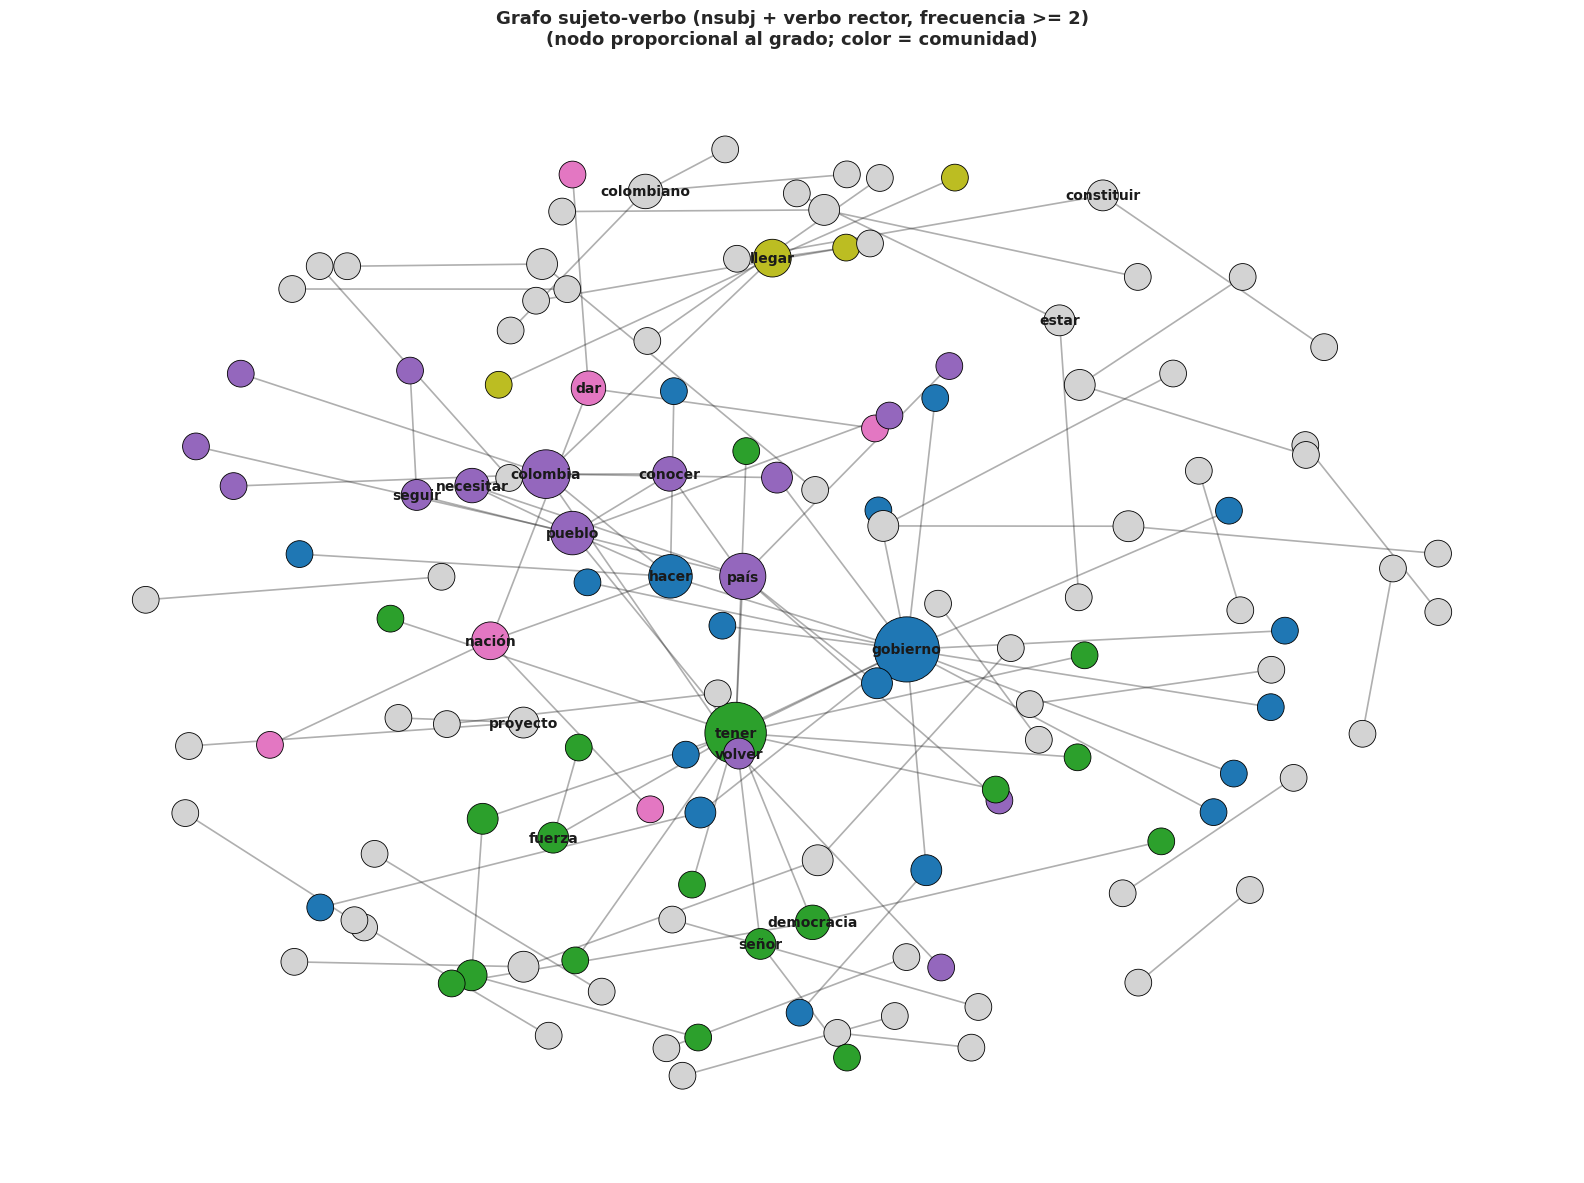

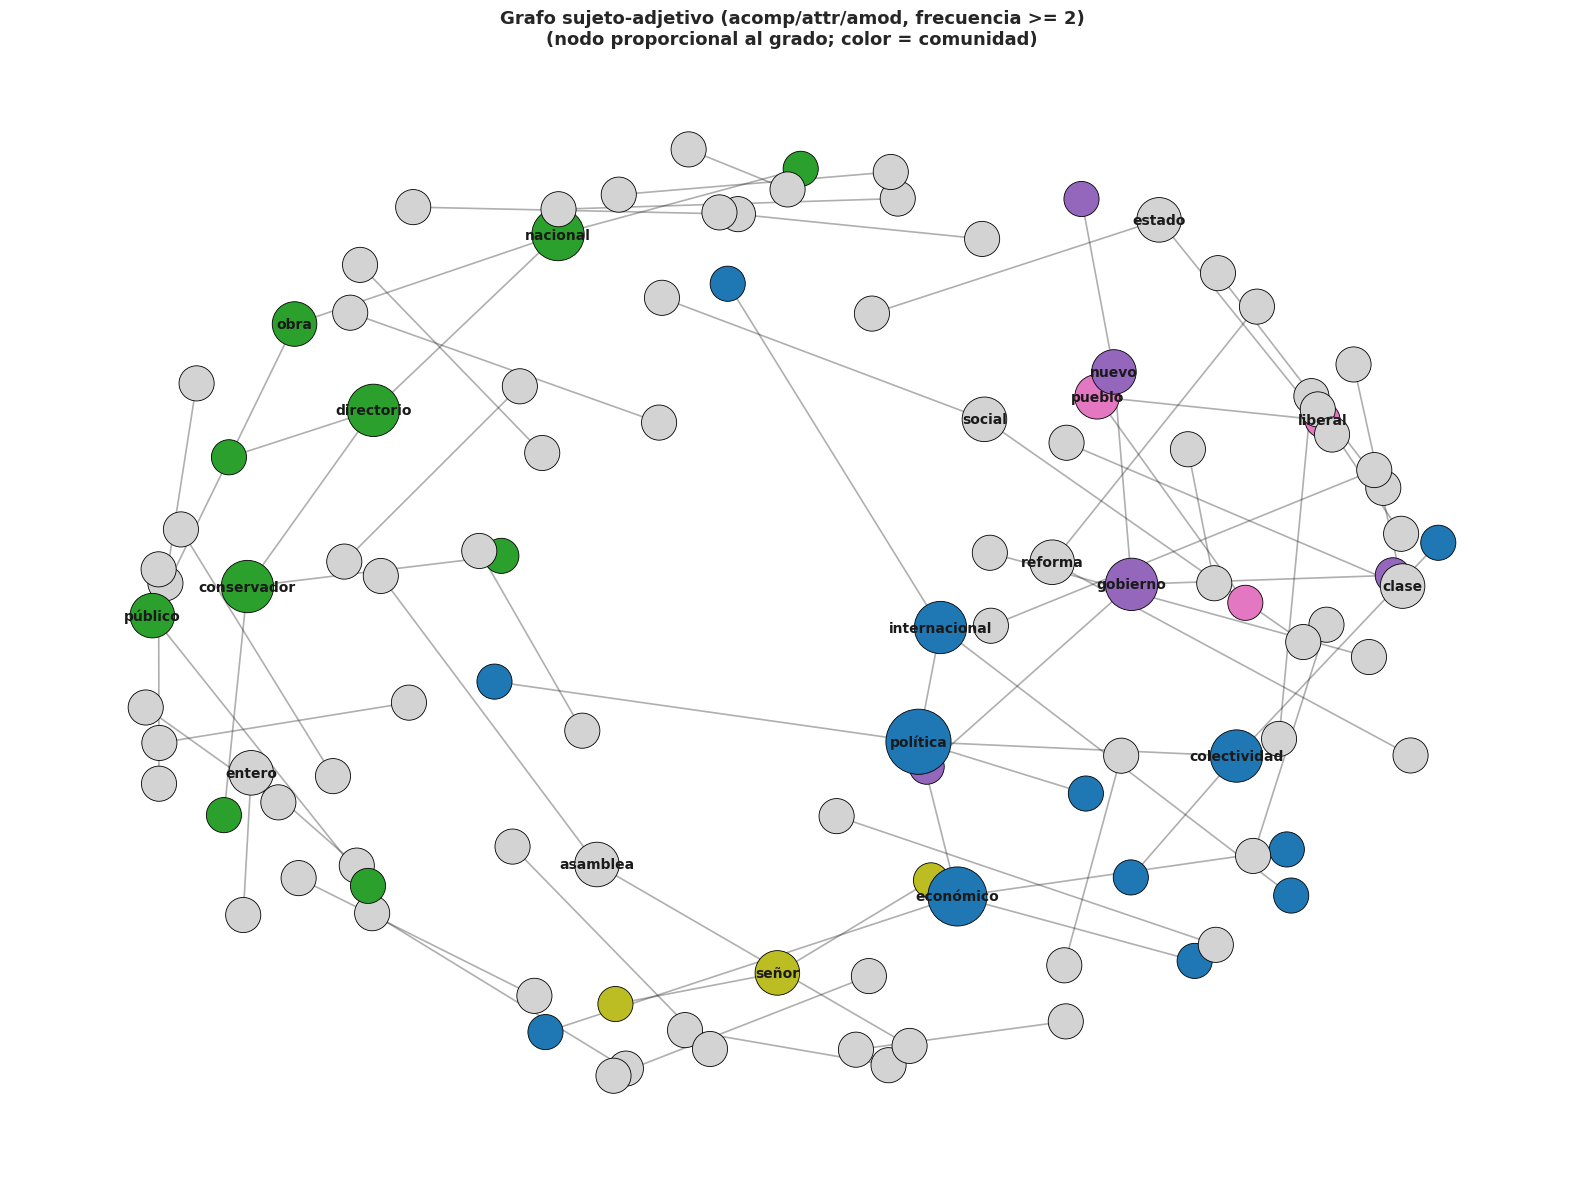

In [67]:
# ===== Punto 10: visualizacion de los grafos con NetworkX =====
def graficar_grafo_sintactico(grafo, titulo, nombre_archivo, seed=42, k=0.6):
    """Dibuja un grafo sintactico con tamano proporcional al grado.

    La posicion se fija con spring_layout (seed fija para reproducibilidad).
    El tamano del nodo es proporcional a su grado (escala 250-2200). Solo se
    etiquetan los nodos con grado alto (top 20). El color agrupa por
    comunidades de modularidad greedy: las 5 comunidades mas grandes usan la
    paleta tab20 y el resto queda en gris claro.

    Args:
        grafo (networkx.Graph): Grafo a dibujar.
        titulo (str): Titulo de la figura.
        nombre_archivo (str): Nombre del archivo en images/.
        seed (int): Semilla de spring_layout.
        k (float): Constante de separacion de nodos de spring_layout.
    """
    pos = nx.spring_layout(grafo, seed=seed, k=k)
    grados = dict(grafo.degree())
    max_grado = max(grados.values()) if grados else 1
    tamanos = [250 + 1950 * (grados[nodo] / max_grado) for nodo in grafo.nodes]

    comunidades = list(nx_community.greedy_modularity_communities(grafo, weight="weight"))
    comunidades = sorted(comunidades, key=len, reverse=True)
    color_por_nodo = {}
    for i, comunidad in enumerate(comunidades[:5]):
        for nodo in comunidad:
            color_por_nodo[nodo] = plt.cm.tab20(i / 5)
    colores = [color_por_nodo.get(nodo, "lightgray") for nodo in grafo.nodes]

    top_grado = sorted(grados.items(), key=lambda x: -x[1])[:20]
    nodos_etiquetados = {nodo for nodo, _ in top_grado}
    etiquetas = {nodo: nodo for nodo in nodos_etiquetados}

    fig, ax = plt.subplots(figsize=(16, 12))
    nx.draw_networkx_edges(grafo, pos, ax=ax, alpha=0.35, width=1.2)
    nx.draw_networkx_nodes(grafo, pos, ax=ax, node_size=tamanos,
                           node_color=colores, edgecolors="black", linewidths=0.6)
    nx.draw_networkx_labels(grafo, pos, ax=ax, labels=etiquetas,
                            font_size=10, font_weight="bold")
    ax.set_title(titulo + "\n(nodo proporcional al grado; color = comunidad)",
                 fontsize=13, fontweight="bold")
    ax.axis("off")
    fig.tight_layout()
    guardar_figura(fig, nombre_archivo)
    plt.show()


graficar_grafo_sintactico(
    grafo_sv,
    "Grafo sujeto-verbo (nsubj + verbo rector, frecuencia >= 2)",
    "grafo_sujeto_verbo.png",
    k=0.55,
)
graficar_grafo_sintactico(
    grafo_sa,
    "Grafo sujeto-adjetivo (acomp/attr/amod, frecuencia >= 2)",
    "grafo_sujeto_adjetivo.png",
    k=0.70,
)



**Lectura de los grafos (cifras de `images/aristas_sujeto_verbo.csv` y `images/aristas_sujeto_adjetivo.csv`)**

1. **Sujeto-verbo** (128 nodos y 106 aristas; 2.108 pares brutos). Los sujetos de mayor grado son los actores colectivos: *gobierno* (grado 14), *colombia* (8), *país* (7), *pueblo* (6) y *nación* (4); los verbos más conectados son *tener* (14) y *hacer* (6). Las aristas más frecuentes son *hora -> llegar* (17, la fórmula "ha llegado la hora"), *colombia -> necesitar* (8), *gobierno -> hacer* (7), *gobierno -> tener* (5) y *gobierno -> proponer* (5): el discurso de posesión presenta al Estado (gobierno, país, nación) como sujeto de la acción y de la necesidad, no a individuos.

2. **Sujeto-adjetivo** (110 nodos y 69 aristas; 852 pares brutos). Las calificaciones más sistemáticas encuadran instituciones y políticas: *fuerza -> armado* (5), *política -> internacional* (5), *política -> exterior* (5), *frente -> nacional* (5), *américa -> latino* (4), *nación -> entero* (4), *desarrollo -> económico* (3) y *gobierno -> nuevo* (3). La única fórmula personal es el saludo ritual *señor -> excelentísimo* (4).

3. **Construcción discursiva**: los sujetos colectivos (gobierno, país, pueblo, nación, colombia) concentran el grado en ambos grafos, mientras los adjetivos definen el marco institucional (nacional, internacional, armado, económico) más que atributos personales; el *pueblo* aparece como receptor (pueblo -> liberal, 3) y el país como entidad que "necesita" (colombia -> necesitar, 8), coherente con el género del discurso de posesión.



## Anexo A — Notas metodológicas y limitaciones

**(a) Frecuencias absolutas vs normalizadas.** Los conteos absolutos favorecen a los presidentes con discursos mas largos y a los grupos con mas discursos; por eso en las secciones 5.4, 5.5 y 8 se reportan frecuencias relativas (por 1.000 palabras o por discurso). Para el informe final se recomienda reportar siempre la version normalizada y mencionar el tamano de cada subcorpus.

**(b) Ruido de tokenizacion.** El corpus contiene artefactos de transcripcion
(aparentemente de un scan con OCR, concentrados en Carlos Lleras 1966, Lopez
Michelsen 1974 y Turbay 1978). El pipeline de limpieza de la seccion 4.2 aplica
cinco etapas: (1) eliminacion de 108 lineas plantilla del scan (32 numeros de
pagina sueltos, 17 pies de fecha "agosto 1974/1978", 7 encabezados de radio
"señal memoria / rtvc", 44 lineas decorativas "---" y 8 "*****"); (2)
de-hyphenation validado (525 uniones con verificacion lexica de palabras
partidas: "co-", "re-", "go-", "in-", "de-", "pre-"); (3) correccion de 8
tokens OCR donde digitos sustituyen letras ("pa1·a"->"para", "pudie1·a"->
"pudiera", "unive1·sidad"->"universidad", "p1·ensa."->"prensa.", "luchado1·"->
"luchador", "fue1-zas"->"fuerzas", "c0lombia"->"colombia", "1eutral"->
"neutral"); (4) 10 uniones de la "n" suelta ("n ación"->"nación" en 7 casos,
"n u estro"->"nuestro", "n un ca"->"nunca", "n o rte"->"norte"); y (5)
eliminacion de 11 duplicados consecutivos de funcionales ("en en" 5, "por por"
2, "de de", "el el", "para para" y "un un" 1 cada uno). Tras la limpieza
persisten solo fragmentos que la validacion lexica rechaza a proposito: la "n"
ante "o" de Turbay ("n o he", "n o se", "n o hay"...; 9 lemas), numeros en
prosa ("7" 15, "1927" 9, "1930" 7), el token "colop1biano" (no corregible sin
cambiar tambien la "p"), y palabras validas poco informativas ("fe" 25, "ir"
21, "dr" 8). Gracias a estas etapas, Turbay ya no conserva "n" ni "1978" entre
sus terminos distintivos (ahora lideran "señor", "digitalizado" y "luis"), y en
Lopez Michelsen salio "1974" del top-3 distintivo. La celda siguiente detecta
automaticamente los tokens con guion, con digitos o de longitud menor o igual a
2 que no esten en un set manual de palabras validas.

**(c) Grupo "Militarismo / Excepcion".** Esta corriente tiene un unico discurso (Rojas Pinilla), que ademas es el mas corto del corpus (657 palabras frente a una media de 4.827): sus frecuencias por discurso no superan 3 y su perfil lexico es anecdoticamente pequeno. Cualquier comparacion de este grupo con los demas debe hacerse con cautela.

In [68]:
# ===== Anexo A: deteccion automatica de tokens anomalos =====
palabras_validas_cortas = {
    "el", "la", "lo", "de", "en", "a", "y", "o", "es", "un",
    "su", "mi", "yo", "se", "no", "me", "te", "le", "os", "as",
    "al", "del",
}


def detectar_tokens_anomalos(
    df: pd.DataFrame,
    col_lemas: str = "lemas_spacy",
    palabras_validas: set = None,
) -> Counter:
    """Cuenta lemas anomalos en todo el corpus.

    Un lema se considera anomalo si contiene guiones o digitos, o si tiene
    longitud menor o igual a 2 y no pertenece al set de palabras validas del
    espanol basico.

    Args:
        df (pd.DataFrame): DataFrame con la columna de lemas.
        col_lemas (str): Columna con las listas de lemas.
        palabras_validas (set): Lemas cortos validos que no se marcan.

    Returns:
        Counter: Frecuencia de cada lema anomalo en todo el corpus.
    """
    if palabras_validas is None:
        palabras_validas = set()
    anomalos = []
    for lista in df[col_lemas]:
        if not isinstance(lista, list):
            continue
        for lema in lista:
            if (
                "-" in lema
                or any(caracter.isdigit() for caracter in lema)
                or (len(lema) <= 2 and lema not in palabras_validas)
            ):
                anomalos.append(lema)
    return Counter(anomalos)


cnt_anomalos = detectar_tokens_anomalos(df, palabras_validas=palabras_validas_cortas)
df_tokens_anomalos = pd.DataFrame(
    cnt_anomalos.most_common(10), columns=["termino", "frecuencia"]
)
df_tokens_anomalos.to_csv("images/tokens_anomalos.csv", index=False, encoding="utf-8-sig")
print("Top 10 tokens anomalos del corpus (guardado en images/tokens_anomalos.csv):")
print(df_tokens_anomalos.to_string(index=False))

Top 10 tokens anomalos del corpus (guardado en images/tokens_anomalos.csv):
termino  frecuencia
     fe          25
     ir          21
      7          15
   1927           9
      n           9
     dr           8
   1930           7
      2           7
      4           7
      5           6


## Anexo B — Reproducibilidad del análisis

Todos los datos tabulares de los graficos de este notebook se exportan como CSV (codificacion utf-8-sig) en la carpeta `images/`: `frecuencias_top20.csv`, `nubes_top10_corriente_politica.csv`, `nubes_top10_decada.csv`, `matcher_top_matches.csv`, `terminos_distintivos_presidente.csv`, `terminos_clave_corriente.csv`, `terminos_clave_decada.csv` y `tokens_anomalos.csv`. A partir de estos archivos puede reproducirse el analisis cualitativo de las secciones 5.4, 5.5, 5.7, 8 y del Anexo A sin necesidad de volver a ejecutar el pipeline de spaCy, que es la etapa mas costosa del notebook.